# Part 1: 1.ipynb

# 00 - Shared configuration

Constants shared by every step of the *Impact of Speed Violation on Crash Severity* pipeline. In the original project this is `config.py`; here it is a notebook, and the same block is inlined at the top of notebooks 01-05 so each one can be run on its own.

*Source: `CODE/config.py`*

In [561]:
# ---- values below are copied verbatim from config.py (inlined so this notebook runs standalone) ----
RANDOM_SEED = 42
RAW_DATA_PATH = "US A 10000.csv"
PROCESSED_DATA_PATH = "processed_full_dataset.csv"
TRAIN_SIZE = 0.70
VAL_SIZE = 0.15
TEST_SIZE = 0.15
CV_FOLDS = 5
MIN_ACCEPTABLE_ACCURACY = 80.0
MAX_ACCEPTABLE_ACCURACY = 97.0
MAX_TRAIN_TEST_GAP = 5.0
TARGET_COL_ORIGINAL = "Severity"
TARGET_COL_BINARY = "Severity_Binary"
OUTPUT_DIR = "outputs"
FIGURES_DIR = "outputs/Figures"
TABLES_DIR = "outputs/Tables"
MODELS_DIR = "outputs/Models"

### Sanity check

The three split fractions must add to 1 and the filtering thresholds must be consistent.

In [562]:
assert abs(TRAIN_SIZE + VAL_SIZE + TEST_SIZE - 1.0) < 1e-9
assert MIN_ACCEPTABLE_ACCURACY < MAX_ACCEPTABLE_ACCURACY
print(f"Split   : train={TRAIN_SIZE:.0%}  val={VAL_SIZE:.0%}  test={TEST_SIZE:.0%}")
print(f"CV      : {CV_FOLDS}-fold stratified, seed={RANDOM_SEED}")
print(f"Filters : keep models with {MIN_ACCEPTABLE_ACCURACY}% <= Test_Accuracy <= {MAX_ACCEPTABLE_ACCURACY}% and Train-Test gap <= {MAX_TRAIN_TEST_GAP}%")
print(f"Target  : {TARGET_COL_ORIGINAL} (1-4)  ->  {TARGET_COL_BINARY} (Low 1-2 = 0, High 3-4 = 1)")

Split   : train=70%  val=15%  test=15%
CV      : 5-fold stratified, seed=42
Filters : keep models with 80.0% <= Test_Accuracy <= 97.0% and Train-Test gap <= 5.0%
Target  : Severity (1-4)  ->  Severity_Binary (Low 1-2 = 0, High 3-4 = 1)


# Part 2: 2.ipynb

# 01 - Data preprocessing

Loads the raw crash dataset (10,000 rows x 46 columns), reports missing values, imputes them (weather columns: forward/back-fill in time order, then median; categoricals: mode), derives `Duration_Minutes`, and caps outliers with the IQR rule (capping, not row removal).

**Run first.** Input: `US A 10000.csv`. Output: `outputs/Processed_Data/cleaned_dataset.csv`, `outputs/Figures/missing_values_raw.png`.

> **[PATCH-1]** is the only change to the original logic in this notebook (marked in-cell); see README.md.

*Source: `CODE/01_data_preprocessing.py`*

## 0. Environment

In [563]:
import sys, importlib
print("Python", sys.version.split()[0])
for pkg in ['pandas', 'numpy', 'matplotlib']:
    try:
        mod = importlib.import_module(pkg)
        print(f"{pkg:<12}{getattr(mod, '__version__', '?')}")
    except ImportError:
        print(f"{pkg:<12}NOT INSTALLED")

Python 3.13.18
pandas      2.2.3
numpy       2.4.6
matplotlib  3.10.0


## 1. Imports and configuration

In [564]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)  # display only (e.g. seaborn palette notice)
warnings.filterwarnings("ignore", message=".*'str' dtypes are included.*")  # display only (pandas 3 select_dtypes notice)

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---- values below are copied verbatim from config.py (inlined so this notebook runs standalone) ----
RANDOM_SEED = 42
RAW_DATA_PATH = "US A 10000.csv"
PROCESSED_DATA_PATH = "processed_full_dataset.csv"
TRAIN_SIZE = 0.70
VAL_SIZE = 0.15
TEST_SIZE = 0.15
CV_FOLDS = 5
MIN_ACCEPTABLE_ACCURACY = 80.0
MAX_ACCEPTABLE_ACCURACY = 97.0
MAX_TRAIN_TEST_GAP = 5.0
TARGET_COL_ORIGINAL = "Severity"
TARGET_COL_BINARY = "Severity_Binary"
OUTPUT_DIR = "outputs"
FIGURES_DIR = "outputs/Figures"
TABLES_DIR = "outputs/Tables"
MODELS_DIR = "outputs/Models"

np.random.seed(RANDOM_SEED)

## 2. Functions (verbatim from the original script)

### `load_raw_data()`

In [565]:
def load_raw_data(path: str) -> pd.DataFrame:
    df = pd.read_csv(path)
    print(f"[LOAD] Raw dataset shape: {df.shape}")
    return df

### `report_missing_values()`

In [566]:
def report_missing_values(df: pd.DataFrame, save_path: str = None) -> pd.Series:
    missing = df.isna().sum()
    missing_pct = (missing / len(df) * 100).round(2)
    report = pd.DataFrame({"missing_count": missing, "missing_pct": missing_pct})
    report = report[report["missing_count"] > 0].sort_values("missing_pct", ascending=False)
    print("[MISSING VALUES]")
    print(report)

    if save_path:
        fig, ax = plt.subplots(figsize=(10, 6))
        if not report.empty:
            ax.barh(report.index, report["missing_pct"])
            ax.set_xlabel("Missing (%)")
            ax.set_title("Missing Values by Column (Raw Dataset)")
            plt.tight_layout()
        plt.savefig(save_path, dpi=150)
        plt.close()
    return report

### `handle_missing_values()`

Numeric columns: median imputation (robust to skew/outliers).

In [567]:
def handle_missing_values(df: pd.DataFrame) -> pd.DataFrame:
    """
    Numeric columns: median imputation (robust to skew/outliers).
    Categorical columns: mode imputation, fallback to 'Unknown'.
    Weather-related numerics: forward/backward fill within sorted time
    order first (weather is temporally correlated), then median as backstop.
    """
    df = df.copy()

    numeric_cols = df.select_dtypes(include=[np.number]).columns
    categorical_cols = df.select_dtypes(include=["object"]).columns

    weather_numeric = [
        c for c in ["Temperature(F)", "Wind_Chill(F)", "Humidity(%)", "Pressure(in)",
                     "Visibility(mi)", "Wind_Speed(mph)", "Precipitation(in)"]
        if c in df.columns
    ]

    if "Start_Time" in df.columns:
        df["Start_Time"] = pd.to_datetime(df["Start_Time"], errors="coerce")
        df = df.sort_values("Start_Time")

    for col in weather_numeric:
        df[col] = df[col].ffill().bfill()

    for col in numeric_cols:
        if df[col].isna().any():
            df[col] = df[col].fillna(df[col].median())

    # [PATCH-1] Columns that are 100% missing (End_Lat, End_Lng) have an undefined median, so they
    # stayed NaN and later crashed GradientBoosting / AdaBoost / MLP (they reject NaN input).
    # Thesis Chapter 3, Sec. 3.6.1 states such columns are filled with the constant placeholder 0.
    fully_missing = [c for c in numeric_cols if df[c].isna().all()]
    for col in fully_missing:
        df[col] = 0.0
    if fully_missing:
        print(f"[PATCH-1] Fully-missing columns filled with constant 0: {fully_missing}")

    for col in categorical_cols:
        if df[col].isna().any():
            mode_val = df[col].mode()
            fill_val = mode_val.iloc[0] if not mode_val.empty else "Unknown"
            df[col] = df[col].fillna(fill_val)

    print(f"[MISSING] Remaining NaNs after imputation: {df.isna().sum().sum()}")
    return df

### `cap_outliers_iqr()`

Caps (winsorizes) numeric outliers using the IQR rule instead of

In [568]:
def cap_outliers_iqr(df: pd.DataFrame, columns: list, factor: float = 1.5) -> pd.DataFrame:
    """
    Caps (winsorizes) numeric outliers using the IQR rule instead of
    removing rows, to preserve sample size and all original records.
    """
    df = df.copy()
    for col in columns:
        if col not in df.columns:
            continue
        q1 = df[col].quantile(0.25)
        q3 = df[col].quantile(0.75)
        iqr = q3 - q1
        lower = q1 - factor * iqr
        upper = q3 + factor * iqr
        n_capped = ((df[col] < lower) | (df[col] > upper)).sum()
        df[col] = df[col].clip(lower=lower, upper=upper)
        if n_capped > 0:
            print(f"[OUTLIERS] Capped {n_capped} values in '{col}' to [{lower:.2f}, {upper:.2f}]")
    return df

### `compute_duration_minutes()`

In [569]:
def compute_duration_minutes(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    if "Start_Time" in df.columns and "End_Time" in df.columns:
        df["Start_Time"] = pd.to_datetime(df["Start_Time"], errors="coerce")
        df["End_Time"] = pd.to_datetime(df["End_Time"], errors="coerce")
        df["Duration_Minutes"] = (df["End_Time"] - df["Start_Time"]).dt.total_seconds() / 60.0
        df["Duration_Minutes"] = df["Duration_Minutes"].clip(lower=0)
    return df

### `main()`

In [570]:
def main():
    os.makedirs(OUTPUT_DIR, exist_ok=True)
    os.makedirs(FIGURES_DIR, exist_ok=True)
    os.makedirs(f"{OUTPUT_DIR}/Processed_Data", exist_ok=True)

    df = load_raw_data(RAW_DATA_PATH)

    report_missing_values(df, save_path=f"{FIGURES_DIR}/missing_values_raw.png")

    df = handle_missing_values(df)
    df = compute_duration_minutes(df)

    outlier_candidates = [
        "Distance(mi)", "Temperature(F)", "Wind_Chill(F)", "Humidity(%)",
        "Pressure(in)", "Visibility(mi)", "Wind_Speed(mph)",
        "Precipitation(in)", "Duration_Minutes",
    ]
    df = cap_outliers_iqr(df, outlier_candidates)

    out_path = f"{OUTPUT_DIR}/Processed_Data/cleaned_dataset.csv"
    df.to_csv(out_path, index=False)
    print(f"[SAVE] Cleaned dataset -> {out_path}  shape={df.shape}")

## 3. Run

In [571]:
main()

[LOAD] Raw dataset shape: (10000, 46)
[MISSING VALUES]
                   missing_count  missing_pct
End_Lat                    10000       100.00
End_Lng                    10000       100.00
Precipitation(in)           8877        88.77
Wind_Chill(F)               8574        85.74
Wind_Speed(mph)             1774        17.74
Humidity(%)                  124         1.24
Visibility(mi)                96         0.96
Temperature(F)                85         0.85
Weather_Condition             77         0.77
Pressure(in)                  35         0.35
Weather_Timestamp             31         0.31
Wind_Direction                31         0.31
Timezone                       1         0.01
Zipcode                        1         0.01
Airport_Code                   1         0.01
[PATCH-1] Fully-missing columns filled with constant 0: ['End_Lat', 'End_Lng']
[MISSING] Remaining NaNs after imputation: 0
[OUTLIERS] Capped 48 values in 'Distance(mi)' to [-0.01, 0.03]
[OUTLIERS] Capped 29 v

## 4. Inspect the result

In [572]:
cleaned = pd.read_csv(f"{OUTPUT_DIR}/Processed_Data/cleaned_dataset.csv")
print("Cleaned shape        :", cleaned.shape)
print("NaN cells remaining  :", int(cleaned.isna().sum().sum()))
cleaned[["Start_Time", "Severity", "Distance(mi)", "Temperature(F)", "Visibility(mi)", "Duration_Minutes"]].head()

Cleaned shape        : (10000, 47)
NaN cells remaining  : 0


,Start_Time,Severity,Distance(mi),Temperature(F),Visibility(mi),Duration_Minutes
0,2016-02-08 05:46:00,3,0.01,36.9,10.0,67.95
1,2016-02-08 06:07:59,2,0.01,37.9,10.0,30.00
2,2016-02-08 06:49:27,2,0.01,36.0,10.0,30.00
3,2016-02-08 07:23:34,3,0.01,35.1,10.0,30.00
4,2016-02-08 07:39:07,2,0.01,36.0,10.0,30.00


Number of distinct values in each IQR-capped column after capping:

In [573]:
capped_cols = ["Distance(mi)", "Temperature(F)", "Wind_Chill(F)", "Humidity(%)", "Pressure(in)",
               "Visibility(mi)", "Wind_Speed(mph)", "Precipitation(in)", "Duration_Minutes"]
cleaned[capped_cols].nunique().to_frame("distinct_values_after_capping")

,distinct_values_after_capping
Distance(mi),3
Temperature(F),236
Wind_Chill(F),47
Humidity(%),93
Pressure(in),91
Visibility(mi),1
Wind_Speed(mph),19
Precipitation(in),1
Duration_Minutes,689


### Missing-value figure produced by `report_missing_values()`

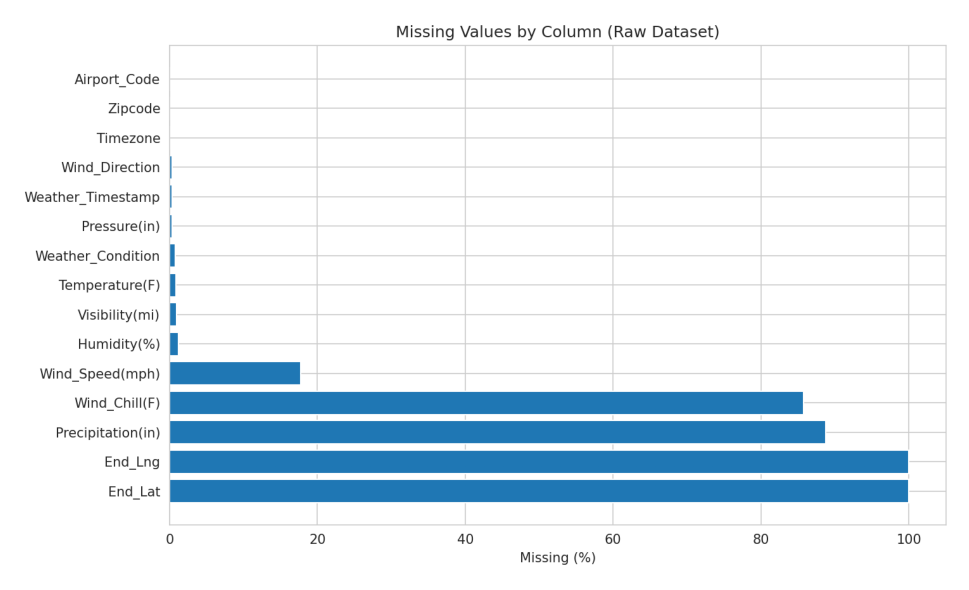

In [574]:
import matplotlib.pyplot as plt

def show_image(path, title=None, figsize=(11, 6)):
    """Display a PNG file inline."""
    img = plt.imread(path)
    plt.figure(figsize=figsize)
    plt.imshow(img)
    plt.axis("off")
    if title:
        plt.title(title, fontsize=11)
    plt.tight_layout()
    plt.show()

show_image(f"{FIGURES_DIR}/missing_values_raw.png", figsize=(10, 6))

# Part 3: 3.ipynb

# 02 - Feature engineering

Builds datetime, road-type, visibility, weather-index, geographic and text features, the composite `Speed_Violation_Risk_Score`, the binary target (Low = Severity 1-2, High = Severity 3-4), and the one-hot / frequency / log encodings.

**Run after 01.** Input: `outputs/Processed_Data/cleaned_dataset.csv`. Output: `outputs/Processed_Data/processed_full_dataset.csv`.

*Source: `CODE/02_feature_engineering.py`*

## 0. Environment

In [575]:
import sys, importlib
print("Python", sys.version.split()[0])
for pkg in ['pandas', 'numpy']:
    try:
        mod = importlib.import_module(pkg)
        print(f"{pkg:<12}{getattr(mod, '__version__', '?')}")
    except ImportError:
        print(f"{pkg:<12}NOT INSTALLED")

Python 3.13.18
pandas      2.2.3
numpy       2.4.6


## 1. Imports and configuration

In [576]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)  # display only (e.g. seaborn palette notice)
warnings.filterwarnings("ignore", message=".*'str' dtypes are included.*")  # display only (pandas 3 select_dtypes notice)

import os
import numpy as np
import pandas as pd

# ---- values below are copied verbatim from config.py (inlined so this notebook runs standalone) ----
RANDOM_SEED = 42
RAW_DATA_PATH = "US A 10000.csv"
PROCESSED_DATA_PATH = "processed_full_dataset.csv"
TRAIN_SIZE = 0.70
VAL_SIZE = 0.15
TEST_SIZE = 0.15
CV_FOLDS = 5
MIN_ACCEPTABLE_ACCURACY = 80.0
MAX_ACCEPTABLE_ACCURACY = 97.0
MAX_TRAIN_TEST_GAP = 5.0
TARGET_COL_ORIGINAL = "Severity"
TARGET_COL_BINARY = "Severity_Binary"
OUTPUT_DIR = "outputs"
FIGURES_DIR = "outputs/Figures"
TABLES_DIR = "outputs/Tables"
MODELS_DIR = "outputs/Models"

np.random.seed(RANDOM_SEED)
ROAD_INFRA_COLS = [
    "Amenity", "Bump", "Crossing", "Give_Way", "Junction", "No_Exit",
    "Railway", "Roundabout", "Station", "Stop", "Traffic_Calming",
    "Traffic_Signal", "Turning_Loop",
]
SPEED_REDUCING_COLS = [
    "Traffic_Calming", "Traffic_Signal", "Stop", "Crossing",
    "Give_Way", "Roundabout",
]
HIGH_FREQ_CARD_COLS = ["Street", "City", "County", "Zipcode", "Airport_Code", "Country"]
WIND_DIR_COL = "Wind_Direction"
WEATHER_COL = "Weather_Condition"
TWILIGHT_COLS = ["Sunrise_Sunset", "Civil_Twilight", "Nautical_Twilight", "Astronomical_Twilight"]
LOG_TRANSFORM_COLS = [
    "Distance(mi)", "Precipitation(in)", "Description_Length",
    "Description_WordCount", "Duration_Minutes",
]

## 2. Functions (verbatim from the original script)

### `add_datetime_features()`

In [577]:
def add_datetime_features(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df["Start_Time"] = pd.to_datetime(df["Start_Time"], errors="coerce")

    df["Hour"] = df["Start_Time"].dt.hour
    df["DayOfWeek"] = df["Start_Time"].dt.dayofweek
    df["Month"] = df["Start_Time"].dt.month
    df["Year"] = df["Start_Time"].dt.year

    df["Is_Weekend"] = df["DayOfWeek"].isin([5, 6]).astype(int)
    df["Is_Night"] = df["Hour"].apply(lambda h: 1 if (pd.isna(h) or h >= 20 or h < 6) else 0)
    df["Is_RushHour"] = df["Hour"].apply(
        lambda h: 1 if (not pd.isna(h) and ((7 <= h <= 9) or (16 <= h <= 18))) else 0
    )
    return df

### `add_road_type_features()`

In [578]:
def add_road_type_features(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    street = df["Street"].astype(str).str.upper() if "Street" in df.columns else pd.Series("", index=df.index)

    df["Is_Interstate"] = street.str.contains(r"\bI-?\d+", regex=True, na=False).astype(int)
    df["Is_USHighway"] = street.str.contains(r"\bUS-?\d+|HWY", regex=True, na=False).astype(int)
    df["Is_StateRoute"] = street.str.contains(r"\bSR-?\d+|STATE ROUTE", regex=True, na=False).astype(int)
    df["Is_HighSpeedRoad"] = ((df["Is_Interstate"] == 1) | (df["Is_USHighway"] == 1)).astype(int)

    present_infra = [c for c in ROAD_INFRA_COLS if c in df.columns]
    df["Traffic_Control_Count"] = df[present_infra].astype(int).sum(axis=1) if present_infra else 0

    present_reducing = [c for c in SPEED_REDUCING_COLS if c in df.columns]
    df["Has_Speed_Reducing_Feature"] = (
        (df[present_reducing].astype(int).sum(axis=1) > 0).astype(int) if present_reducing else 0
    )
    df["No_Traffic_Control"] = (df["Traffic_Control_Count"] == 0).astype(int)
    return df

### `add_visibility_features()`

In [579]:
def add_visibility_features(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    if "Visibility(mi)" in df.columns:
        df["Low_Visibility"] = (df["Visibility(mi)"] < 2.0).astype(int)
    else:
        df["Low_Visibility"] = 0
    return df

### `add_speed_violation_risk_score()`

Composite proxy for speed-violation risk. The raw dataset has no

In [580]:
def add_speed_violation_risk_score(df: pd.DataFrame) -> pd.DataFrame:
    """
    Composite proxy for speed-violation risk. The raw dataset has no
    explicit speed-limit/violation field, so this score combines four
    weighted risk drivers:
        - high-speed road class (Interstate/US Highway)
        - absence of speed-reducing infrastructure
        - night-time driving
        - low-visibility conditions
    Weighted sum, then normalized to a 0-1 scale.
    """
    df = df.copy()
    weights = {
        "Is_HighSpeedRoad": 0.35,
        "No_Traffic_Control": 0.25,
        "Is_Night": 0.25,
        "Low_Visibility": 0.15,
    }
    score = sum(df[col].astype(float) * w for col, w in weights.items())
    df["Speed_Violation_Risk_Score"] = score / sum(weights.values())
    df["High_Speed_Violation_Risk"] = (
        df["Speed_Violation_Risk_Score"] >= df["Speed_Violation_Risk_Score"].quantile(0.75)
    ).astype(int)
    return df

### `add_weather_severity_index()`

In [581]:
def add_weather_severity_index(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    parts = []
    if "Low_Visibility" in df.columns:
        parts.append(df["Low_Visibility"] * 0.4)
    if "Precipitation(in)" in df.columns:
        precip_norm = (df["Precipitation(in)"] - df["Precipitation(in)"].min()) / (
            df["Precipitation(in)"].max() - df["Precipitation(in)"].min() + 1e-9
        )
        parts.append(precip_norm * 0.35)
    if "Wind_Speed(mph)" in df.columns:
        wind_norm = (df["Wind_Speed(mph)"] - df["Wind_Speed(mph)"].min()) / (
            df["Wind_Speed(mph)"].max() - df["Wind_Speed(mph)"].min() + 1e-9
        )
        parts.append(wind_norm * 0.25)
    df["Weather_Severity_Index"] = sum(parts) if parts else 0.0
    return df

### `add_geo_and_text_features()`

In [582]:
def add_geo_and_text_features(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    if {"Start_Lat", "End_Lat"}.issubset(df.columns):
        df["Lat_Diff"] = (df["End_Lat"] - df["Start_Lat"]).abs()
    if {"Start_Lng", "End_Lng"}.issubset(df.columns):
        df["Lng_Diff"] = (df["End_Lng"] - df["Start_Lng"]).abs()

    if "Description" in df.columns:
        desc = df["Description"].astype(str)
        df["Description_Length"] = desc.str.len()
        df["Description_WordCount"] = desc.str.split().str.len()
    return df

### `add_target_binary()`

Low: Severity 1-2 -> 0, High: Severity 3-4 -> 1 (classes 1 & 4 are extremely rare).

In [583]:
def add_target_binary(df: pd.DataFrame) -> pd.DataFrame:
    """Low: Severity 1-2 -> 0, High: Severity 3-4 -> 1 (classes 1 & 4 are extremely rare)."""
    df = df.copy()
    df[TARGET_COL_BINARY] = df[TARGET_COL_ORIGINAL].apply(lambda s: 1 if s >= 3 else 0)
    return df

### `one_hot_encode_low_cardinality()`

One-hot encodes categorical columns, keeping only the most frequent

In [584]:
def one_hot_encode_low_cardinality(df: pd.DataFrame, cols: list, top_n: int = 20) -> pd.DataFrame:
    """One-hot encodes categorical columns, keeping only the most frequent
    top_n categories per column to avoid dimensionality explosion, prefixed
    with 'enc_' to match the processed dataset naming convention."""
    df = df.copy()
    for col in cols:
        if col not in df.columns:
            continue
        top_vals = df[col].value_counts().nlargest(top_n).index
        for val in top_vals:
            safe_val = str(val).replace(" ", "_")
            df[f"enc_{col}_{val}"] = (df[col] == val).astype(int)
    return df

### `frequency_encode_high_cardinality()`

Frequency-encodes very high-cardinality identifier columns

In [585]:
def frequency_encode_high_cardinality(df: pd.DataFrame, cols: list) -> pd.DataFrame:
    """Frequency-encodes very high-cardinality identifier columns
    (Street, City, County, Zipcode, Airport_Code, Country)."""
    df = df.copy()
    for col in cols:
        if col not in df.columns:
            continue
        freq_map = df[col].value_counts(normalize=True)
        df[f"enc_{col}_freq"] = df[col].map(freq_map).fillna(0.0)
    return df

### `encode_binary_flags()`

In [586]:
def encode_binary_flags(df: pd.DataFrame, cols: list) -> pd.DataFrame:
    df = df.copy()
    for col in cols:
        if col not in df.columns:
            continue
        if df[col].dtype == bool:
            df[f"enc_{col}"] = df[col].astype(int)
        else:
            df[f"enc_{col}"] = df[col].astype(str).str.lower().map(
                {"true": 1, "false": 0, "1": 1, "0": 0}
            ).fillna(0).astype(int)
    return df

### `encode_twilight_and_source()`

In [587]:
def encode_twilight_and_source(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    for col in TWILIGHT_COLS:
        if col in df.columns:
            df[f"enc_{col}_Night"] = (df[col] == "Night").astype(int)
    if "Source" in df.columns:
        top_sources = df["Source"].value_counts().nlargest(3).index
        for src in top_sources:
            df[f"enc_Source_{src}"] = (df["Source"] == src).astype(int)
    if "Timezone" in df.columns:
        top_tz = df["Timezone"].value_counts().nlargest(3).index
        for tz in top_tz:
            safe_tz = str(tz).replace("/", "_")
            df[f"enc_Timezone_{tz}"] = (df["Timezone"] == tz).astype(int)
    if "State" in df.columns:
        top_states = df["State"].value_counts().nlargest(5).index
        for st in top_states:
            df[f"enc_State_{st}"] = (df["State"] == st).astype(int)
    return df

### `apply_log_transforms()`

In [588]:
def apply_log_transforms(df: pd.DataFrame, cols: list) -> pd.DataFrame:
    df = df.copy()
    for col in cols:
        if col in df.columns:
            df[f"{col}_log"] = np.log1p(df[col].clip(lower=0))
    return df

### `main()`

In [589]:
def main():
    in_path = "processed_full_dataset.csv"
    df = pd.read_csv(in_path)
    print(f"[LOAD] Cleaned dataset shape: {df.shape}")

    n_original = df.shape[1]

    df = add_datetime_features(df)
    df = add_road_type_features(df)
    df = add_visibility_features(df)
    df = add_speed_violation_risk_score(df)
    df = add_weather_severity_index(df)
    df = add_geo_and_text_features(df)
    df = add_target_binary(df)

    df = encode_twilight_and_source(df)
    df = one_hot_encode_low_cardinality(df, [WIND_DIR_COL, WEATHER_COL])
    df = frequency_encode_high_cardinality(df, HIGH_FREQ_CARD_COLS)
    df = encode_binary_flags(df, ROAD_INFRA_COLS)
    df = apply_log_transforms(df, LOG_TRANSFORM_COLS)

    print(f"[FEATURES] Original columns: {n_original} | Total after engineering: {df.shape[1]}")

    out_path = "processed_full_dataset.csv"
    df.to_csv(out_path, index=False)
    print(f"[SAVE] Final processed dataset -> {out_path}  shape={df.shape}")

In [590]:
import os

print(os.getcwd())
print(os.listdir())

/content
['.config', 'outputs', 'reference_outputs', 'LightGBM.pkl', 'standard_scaler.pkl', 'processed_full_dataset.csv', 'US A 10000.csv', 'sample_data']


## 3. Run

In [591]:
main()

[LOAD] Cleaned dataset shape: (10000, 149)
[FEATURES] Original columns: 149 | Total after engineering: 149
[SAVE] Final processed dataset -> processed_full_dataset.csv  shape=(10000, 149)


## 4. Inspect the result

In [592]:
proc = pd.read_csv("processed_full_dataset.csv")
print("Processed shape :", proc.shape)
print("\nBinary target balance (Severity_Binary):")
print(proc["Severity_Binary"].value_counts().sort_index().rename({0: "Low (1-2)", 1: "High (3-4)"}))

Processed shape : (10000, 149)

Binary target balance (Severity_Binary):
Severity_Binary
Low (1-2)     6053
High (3-4)    3947
Name: count, dtype: int64


Components of the composite score and the score itself:

In [593]:
score_cols = ["Is_HighSpeedRoad", "No_Traffic_Control", "Is_Night", "Low_Visibility",
              "Speed_Violation_Risk_Score", "High_Speed_Violation_Risk"]
proc[score_cols].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
Is_HighSpeedRoad,10000.0,0.349,0.477,0.0,0.00,0.00,1.0,1.00
No_Traffic_Control,10000.0,0.674,0.469,0.0,0.00,1.00,1.0,1.00
Is_Night,10000.0,0.291,0.454,0.0,0.00,0.00,1.0,1.00
Low_Visibility,10000.0,0.000,0.000,0.0,0.00,0.00,0.0,0.00
Speed_Violation_Risk_Score,10000.0,0.363,0.242,0.0,0.25,0.25,0.6,0.85
High_Speed_Violation_Risk,10000.0,0.279,0.448,0.0,0.00,0.00,1.0,1.00


# Part 4: 4.ipynb

# 03 - Exploratory data analysis

Severity distribution (original 1-4 and binary), correlation heatmap of the 25 features most correlated with the binary target, high-severity rate by road type, and the speed-violation risk score by severity class.

**Run after 02.** Input: `outputs/Processed_Data/processed_full_dataset.csv`. Output: four PNG figures in `outputs/Figures/`.

*Source: `CODE/03_eda.py`*

## 0. Environment

In [594]:
import sys, importlib
print("Python", sys.version.split()[0])
for pkg in ['pandas', 'numpy', 'matplotlib', 'seaborn']:
    try:
        mod = importlib.import_module(pkg)
        print(f"{pkg:<12}{getattr(mod, '__version__', '?')}")
    except ImportError:
        print(f"{pkg:<12}NOT INSTALLED")

Python 3.13.18
pandas      2.2.3
numpy       2.4.6
matplotlib  3.10.0
seaborn     0.13.2


## 1. Imports and configuration

In [595]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)  # display only (e.g. seaborn palette notice)
warnings.filterwarnings("ignore", message=".*'str' dtypes are included.*")  # display only (pandas 3 select_dtypes notice)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ---- values below are copied verbatim from config.py (inlined so this notebook runs standalone) ----
RANDOM_SEED = 42
RAW_DATA_PATH = "US A 10000.csv"
PROCESSED_DATA_PATH = "processed_full_dataset.csv"
TRAIN_SIZE = 0.70
VAL_SIZE = 0.15
TEST_SIZE = 0.15
CV_FOLDS = 5
MIN_ACCEPTABLE_ACCURACY = 80.0
MAX_ACCEPTABLE_ACCURACY = 97.0
MAX_TRAIN_TEST_GAP = 5.0
TARGET_COL_ORIGINAL = "Severity"
TARGET_COL_BINARY = "Severity_Binary"
OUTPUT_DIR = "outputs"
FIGURES_DIR = "outputs/Figures"
TABLES_DIR = "outputs/Tables"
MODELS_DIR = "outputs/Models"

sns.set_style("whitegrid")

## 2. Functions (verbatim from the original script)

### `plot_severity_distribution()`

In [596]:
def plot_severity_distribution(df: pd.DataFrame, save_path: str):
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    df[TARGET_COL_ORIGINAL].value_counts().sort_index().plot(kind="bar", ax=axes[0], color="steelblue")
    axes[0].set_title("Original Severity Distribution (1-4)")
    axes[0].set_xlabel("Severity")
    axes[0].set_ylabel("Count")

    df[TARGET_COL_BINARY].value_counts().sort_index().plot(kind="bar", ax=axes[1], color="indianred")
    axes[1].set_xticklabels(["Low (1-2)", "High (3-4)"], rotation=0)
    axes[1].set_title("Reframed Binary Severity Distribution")
    axes[1].set_ylabel("Count")

    plt.tight_layout()
    plt.savefig(save_path, dpi=150)
    plt.close()
    print(f"[SAVE] {save_path}")

### `plot_correlation_heatmap()`

In [597]:
def plot_correlation_heatmap(df: pd.DataFrame, save_path: str, top_n: int = 25):
    numeric_df = df.select_dtypes(include=[np.number])
    corr_with_target = numeric_df.corr()[TARGET_COL_BINARY].abs().sort_values(ascending=False)
    top_features = corr_with_target.head(top_n).index.tolist()

    corr_matrix = numeric_df[top_features].corr()

    plt.figure(figsize=(14, 12))
    sns.heatmap(corr_matrix, cmap="coolwarm", center=0, annot=False, square=True, linewidths=0.3)
    plt.title(f"Correlation Heatmap — Top {top_n} Features Correlated with Severity")
    plt.tight_layout()
    plt.savefig(save_path, dpi=150)
    plt.close()
    print(f"[SAVE] {save_path}")

    r_speed = corr_with_target.get("Speed_Violation_Risk_Score", np.nan)
    print(f"[CORRELATION] Speed_Violation_Risk_Score vs Severity_Binary: r = {r_speed:.3f}")

### `plot_roadtype_vs_severity()`

In [598]:
def plot_roadtype_vs_severity(df: pd.DataFrame, save_path: str):
    road_cols = ["Is_Interstate", "Is_USHighway", "Is_StateRoute", "Is_HighSpeedRoad"]
    road_cols = [c for c in road_cols if c in df.columns]

    rates = {}
    for col in road_cols:
        rates[col] = df.groupby(col)[TARGET_COL_BINARY].mean().get(1, np.nan)

    plt.figure(figsize=(8, 5))
    plt.bar(rates.keys(), rates.values(), color="darkorange")
    plt.ylabel("High-Severity Crash Rate")
    plt.title("Road Type vs High-Severity Crash Rate")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.savefig(save_path, dpi=150)
    plt.close()
    print(f"[SAVE] {save_path}")

### `plot_speed_risk_vs_severity()`

In [599]:
def plot_speed_risk_vs_severity(df: pd.DataFrame, save_path: str):
    plt.figure(figsize=(8, 5))
    sns.boxplot(x=TARGET_COL_BINARY, y="Speed_Violation_Risk_Score", data=df, palette=["#4C72B0", "#C44E52"])
    plt.xticks([0, 1], ["Low Severity", "High Severity"])
    plt.title("Speed Violation Risk Score vs Crash Severity")
    plt.tight_layout()
    plt.savefig(save_path, dpi=150)
    plt.close()
    print(f"[SAVE] {save_path}")

### `main()`

In [600]:
def main():
    df = pd.read_csv("processed_full_dataset.csv")

    plot_severity_distribution(df, f"{FIGURES_DIR}/severity_distribution.png")
    plot_correlation_heatmap(df, f"{FIGURES_DIR}/correlation_heatmap.png")
    plot_roadtype_vs_severity(df, f"{FIGURES_DIR}/roadtype_vs_severity.png")
    plot_speed_risk_vs_severity(df, f"{FIGURES_DIR}/speed_risk_vs_severity.png")

In [601]:
import os

print(os.getcwd())
print(os.listdir())

/content
['.config', 'outputs', 'reference_outputs', 'LightGBM.pkl', 'standard_scaler.pkl', 'processed_full_dataset.csv', 'US A 10000.csv', 'sample_data']


In [602]:
import os

os.makedirs('outputs/Figures', exist_ok=True)

## 3. Run

In [603]:
main()

[SAVE] outputs/Figures/severity_distribution.png
[SAVE] outputs/Figures/correlation_heatmap.png
[CORRELATION] Speed_Violation_Risk_Score vs Severity_Binary: r = 0.396
[SAVE] outputs/Figures/roadtype_vs_severity.png
[SAVE] outputs/Figures/speed_risk_vs_severity.png


## 4. Figures produced (displayed from `outputs/Figures/`)

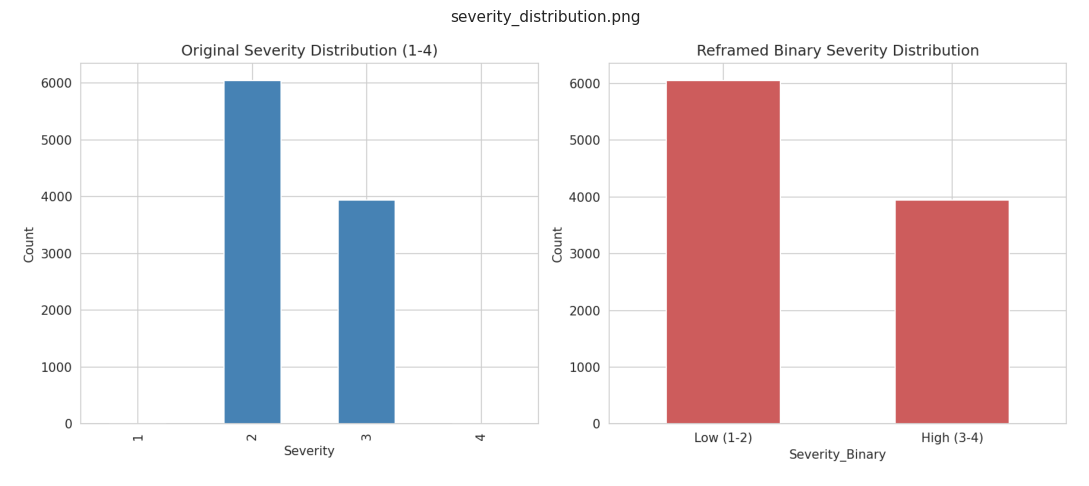

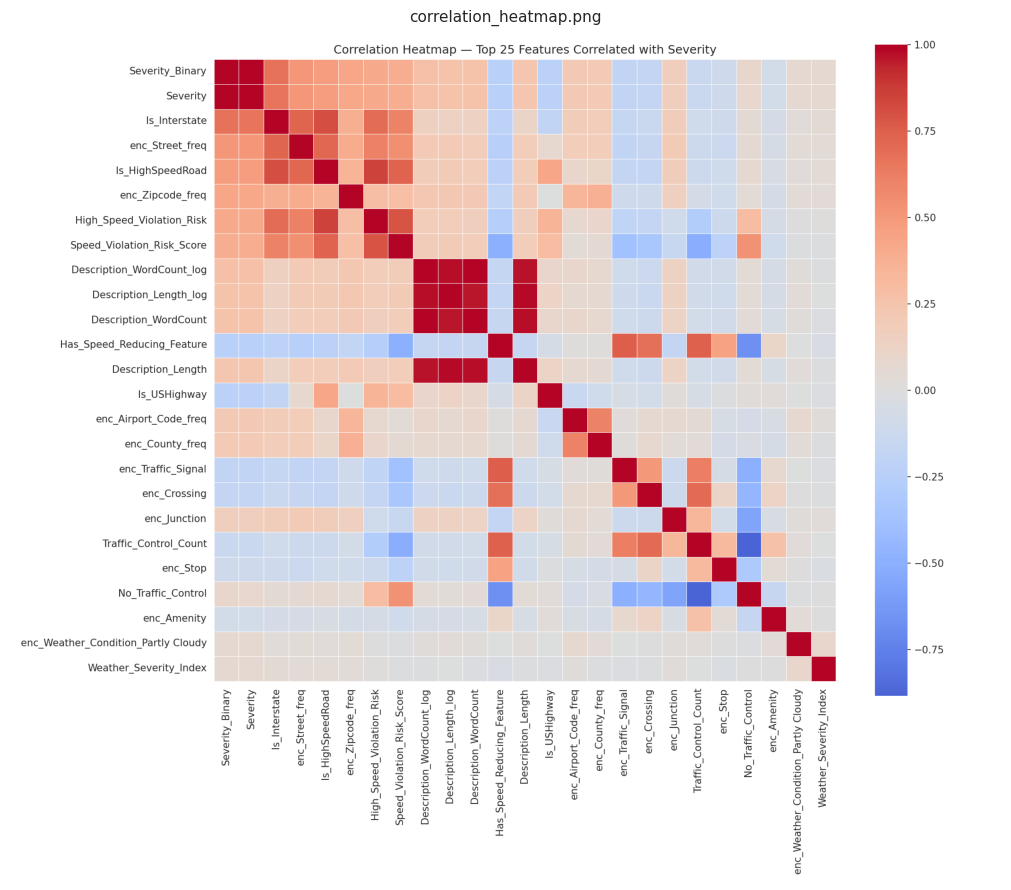

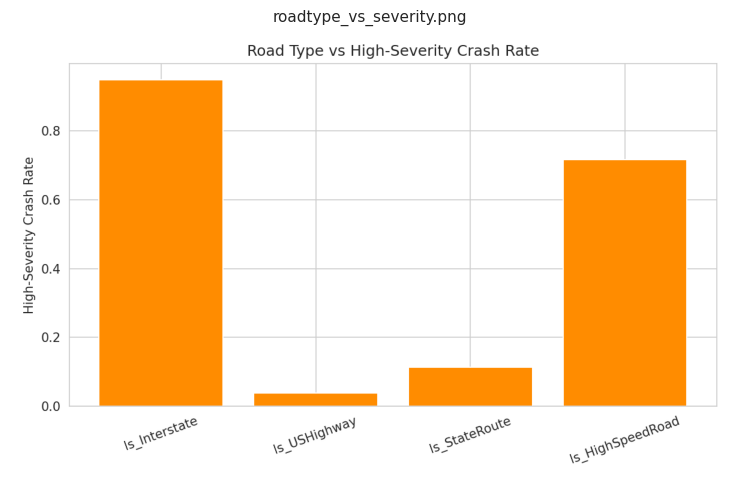

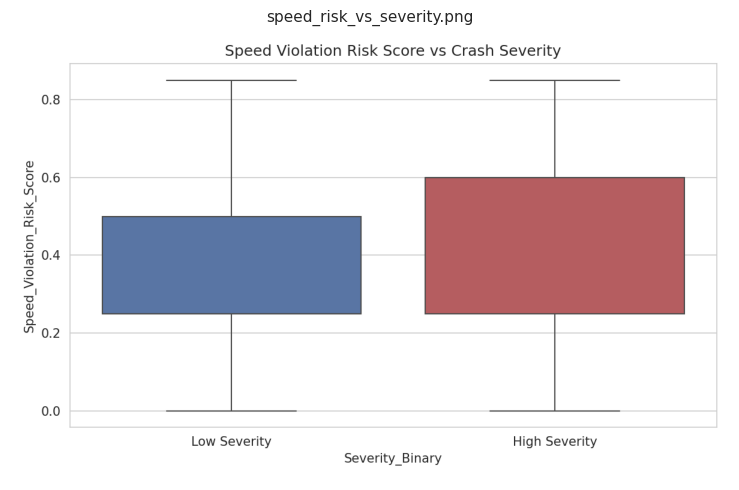

In [604]:
import matplotlib.pyplot as plt

def show_image(path, title=None, figsize=(11, 6)):
    """Display a PNG file inline."""
    img = plt.imread(path)
    plt.figure(figsize=figsize)
    plt.imshow(img)
    plt.axis("off")
    if title:
        plt.title(title, fontsize=11)
    plt.tight_layout()
    plt.show()

show_image(f"{FIGURES_DIR}/severity_distribution.png", "severity_distribution.png", (11, 5))
show_image(f"{FIGURES_DIR}/correlation_heatmap.png", "correlation_heatmap.png", (11, 9))
show_image(f"{FIGURES_DIR}/roadtype_vs_severity.png", "roadtype_vs_severity.png", (8, 5))
show_image(f"{FIGURES_DIR}/speed_risk_vs_severity.png", "speed_risk_vs_severity.png", (8, 5))

# Part 5: 5.ipynb

In [605]:
# Re-create the ORIGINAL reference CSVs directly from data embedded in this notebook.
import os, base64, hashlib
os.makedirs("reference_outputs", exist_ok=True)
with open(os.path.join("reference_outputs", "all_models_results.csv"), "wb") as f:
    f.write(base64.b64decode("TW9kZWwsQ1ZfQWNjdXJhY3lfTWVhbixDVl9BY2N1cmFjeV9TdGQsVHJhaW5fQWNjdXJhY3ksVGVzdF9BY2N1cmFjeSxBY2N1cmFjeV9HYXAsUHJlY2lzaW9uLFJlY2FsbCxGMV9TY29yZSxST0NfQVVDLExvZ0xvc3MsQ29oZW5fS2FwcGEsTUNDLFRyYWluX1RpbWVfU2VjClJhbmRvbSBGb3Jlc3QsOTAuOTcxNDI4NTcxNDI4NTgsMC4zMjc2Mzg0MjY4OTA4NDc5LDkzLjIxNDI4NTcxNDI4NTcyLDkxLjMzMzMzMzMzMzMzMzMzLDEuODgwOTUyMzgwOTUyMzgzMiw4OS45NjUzOTc5MjM4NzU0Myw4Ny44Mzc4Mzc4Mzc4Mzc4NCw4OC44ODg4ODg4ODg4ODg4OSw5NS44OTY4MzI5NTYzMDQzMiwwLjI3NTQxNzA4MTM1ODkyNTA2LDAuODE3ODY3MzEwMjY0NDM4LDAuODE4MDI0NjgwNzc2MjQwMiwxMy4xMDk2NDQ2NTE0MTI5NjQKWEdCb29zdCw5My41NzE0Mjg1NzE0Mjg1NywwLjIzOTA0NTcyMTg2Njg3NDk4LDk2Ljg4NTcxNDI4NTcxNDI5LDkzLjUzMzMzMzMzMzMzMzMzLDMuMzUyMzgwOTUyMzgwOTUxLDkzLjM0NTAwODc1NjU2NzQyLDkwLjAzMzc4Mzc4Mzc4Mzc5LDkxLjY1OTUwMTI4OTc2Nzg1LDk3LjEyMDc1MDk4MjI1OTc4LDAuMTk4MzQwNDQ0NDkwMTIxNTYsMC44NjM4MTk2MzkxNzM1MjA5LDAuODY0MTk1MzAzODc3NDY1Niw1LjE4MTg2MTQwMDYwNDI0OApMaWdodEdCTSw5My45NTcxNDI4NTcxNDI4NiwwLjI0OTg5NzkzODM1MDUxMzk3LDk4LjE0Mjg1NzE0Mjg1NzE0LDk0LjAsNC4xNDI4NTcxNDI4NTcxNDgsOTIuOTc5NDUyMDU0Nzk0NTIsOTEuNzIyOTcyOTcyOTcyOTcsOTIuMzQ2OTM4Nzc1NTEwMiw5Ny4yMDQwOTQyMzc0MDkyNCwwLjE5MzExMjg0MDQ1NzYxMDEsMC44NzQxMzEwMzc5ODA3MjYyLDAuODc0MTg1NzU0NjQwNTQxMiwzLjc4MTEyMTI1Mzk2NzI4NQpDYXRCb29zdCw5My4xODU3MTQyODU3MTQyNywwLjM0ODc1ODczMTg3ODEwMzQsOTUuOTg1NzE0Mjg1NzE0MjgsOTMuNTMzMzMzMzMzMzMzMzMsMi40NTIzODA5NTIzODA5NTAzLDkxLjg3ODE3MjU4ODgzMjQ4LDkxLjcyMjk3Mjk3Mjk3Mjk3LDkxLjgwMDUwNzE4NTEyMjU3LDk3LjEyNzU0MTIyNTE0NTg1LDAuMjAyMjUwODcyMDMzMDAwMTMsMC44NjQ2MjA0MzQ3Nzc3NTQyLDAuODY0NjIxMjc2ODY4NTAyNCwxMS40NTgzMzY4MzAxMzkxNgpFeHRyYSBUcmVlcyw4OC42ODU3MTQyODU3MTQyOCwwLjI4MDY2OTc1MjkxOTgzODE0LDg5Ljg4NTcxNDI4NTcxNDI5LDg5LjEzMzMzMzMzMzMzMzMzLDAuNzUyMzgwOTUyMzgwOTU5OSw5Mi40NzUyNDc1MjQ3NTI0OCw3OC44ODUxMzUxMzUxMzUxMyw4NS4xNDEyOTQ0MzkzODAxMyw5NC4zMjQzODAxMzQ1Mzk4MiwwLjMzODkzMzAzNjU4NzY0NDUsMC43NjY2MDQ5MzcwOTMxMDk4LDAuNzcyNjIzMzExNzAwODIyOSw4LjE2OTkyNjQwNDk1MzAwMwpHcmFkaWVudCBCb29zdGluZyw5Mi42NzE0Mjg1NzE0Mjg1NiwwLjMxNDkzNDM5NTUwMDY5MjcsOTQuNzg1NzE0Mjg1NzE0MjgsOTIuNjY2NjY2NjY2NjY2NjYsMi4xMTkwNDc2MTkwNDc2MjA0LDkyLjczMDQ5NjQ1MzkwMDcxLDg4LjM0NDU5NDU5NDU5NDYsOTAuNDg0NDI5MDY1NzQzOTQsOTYuNzAxMDU4MTYxNjg1OSwwLjIxNTk1MDQzMjc4OTA0MDEsMC44NDUyNDgyNzgwMzUzODQ3LDAuODQ1OTA0ODE4ODc0MTAyOCwzNC42NjIyOTY1MzM1ODQ1OTUKSGlzdEdyYWRpZW50Qm9vc3RpbmcsOTMuNzcxNDI4NTcxNDI4NTcsMC41NjMxNTQzODEyNjkzNDMxLDk4LjE4NTcxNDI4NTcxNDI4LDkzLjI2NjY2NjY2NjY2NjY3LDQuOTE5MDQ3NjE5MDQ3NjIzLDkyLjk5NDc0NjA1OTU0NDY3LDg5LjY5NTk0NTk0NTk0NTk0LDkxLjMxNTU2MzE5ODYyNDI1LDk3LjA3OTI2NTM4ODczNjc0LDAuMTk4MDQ3ODAwODM1MDU3OTYsMC44NTgyMDM5NTQxOTA5ODU3LDAuODU4NTc3MTc2NzAxNTEzMiwxNS4yODI1MjQzNDczMDUyOTgKQWRhQm9vc3QsODMuOSwwLjQ3Mjk0MTI5NTkyMTMzODQsODMuODk5OTk5OTk5OTk5OTksODQuNDY2NjY2NjY2NjY2NjcsLTAuNTY2NjY2NjY2NjY2NjcwOSw5NC45ODc0Njg2NzE2NzkyLDY0LjAyMDI3MDI3MDI3MDI3LDc2LjQ4ODM5NTU2MDA0MDM3LDkyLjA4MTkyNTY3NTY3NTY2LDAuNDIxOTc5MzkyMjg2NjE0NywwLjY1NTM1Mzk5NDM0MzY2MzksMC42ODM4MTA4NzA4OTkxNjk0LDE2LjEwOTIwMjg2MTc4NTg5CkRlY2lzaW9uIFRyZWUsODkuODU3MTQyODU3MTQyODYsMC45Mzg5NTI5NTU3MjMxNDEzLDkxLjE4NTcxNDI4NTcxNDI4LDg5LjY2NjY2NjY2NjY2NjY2LDEuNTE5MDQ3NjE5MDQ3NjE5OSw4NS4xODUxODUxODUxODUxOSw4OS4zNTgxMDgxMDgxMDgxLDg3LjIyMTc2NDIyMDkzOTgyLDk0Ljg0OTc0MDI5NjQ2Mzg2LDAuNDIxNTk5NzE1ODg5MDA4MywwLjc4NTU2MzI5MDY0ODg5OTMsMC43ODYxOTYyOTUwNTkwODQ4LDAuNDk0MjI0NTQ4MzM5ODQzNzUKTUxQIENsYXNzaWZpZXIsODUuNzU3MTQyODU3MTQyODUsMC44MDUwODU4NzQ0OTE3MzQ0LDkwLjgyODU3MTQyODU3MTQyLDg1LjYsNS4yMjg1NzE0Mjg1NzE0MjcsODQuODE0ODE0ODE0ODE0ODEsNzcuMzY0ODY0ODY0ODY0ODcsODAuOTE4NzI3OTE1MTk0MzQsOTMuMzM3MTkwNDM5MzM4MDIsMC4zMjUwNjI2OTQzMjU4MTQ3LDAuNjkzOTQ2OTUwODA0ODA2MiwwLjY5NTgzODI1NTYwNjEyMSw1LjI1MzQ0ODk2MzE2NTI4Mwo="))
with open(os.path.join("reference_outputs", "all_models_results_filtered.csv"), "wb") as f:
    f.write(base64.b64decode("TW9kZWwsQ1ZfQWNjdXJhY3lfTWVhbixDVl9BY2N1cmFjeV9TdGQsVHJhaW5fQWNjdXJhY3ksVGVzdF9BY2N1cmFjeSxBY2N1cmFjeV9HYXAsUHJlY2lzaW9uLFJlY2FsbCxGMV9TY29yZSxST0NfQVVDLExvZ0xvc3MsQ29oZW5fS2FwcGEsTUNDLFRyYWluX1RpbWVfU2VjLFN0YXR1cyxSZW1vdmFsX1JlYXNvbgpMaWdodEdCTSw5My45NTcxNDI4NTcxNDI4NiwwLjI0OTg5NzkzODM1MDUxMzksOTguMTQyODU3MTQyODU3MTQsOTQuMCw0LjE0Mjg1NzE0Mjg1NzE0OCw5Mi45Nzk0NTIwNTQ3OTQ1Miw5MS43MjI5NzI5NzI5NzI5NSw5Mi4zNDY5Mzg3NzU1MTAyLDk3LjIwNDA5NDIzNzQwOTI0LDAuMTkzMTEyODQwNDU3NjEwMSwwLjg3NDEzMTAzNzk4MDcyNjIsMC44NzQxODU3NTQ2NDA1NDEyLDMuNzgxMTIxMjUzOTY3Mjg1LEtFUFQsClhHQm9vc3QsOTMuNTcxNDI4NTcxNDI4NTYsMC4yMzkwNDU3MjE4NjY4NzQ5LDk2Ljg4NTcxNDI4NTcxNDI5LDkzLjUzMzMzMzMzMzMzMzMyLDMuMzUyMzgwOTUyMzgwOTUxLDkzLjM0NTAwODc1NjU2NzQyLDkwLjAzMzc4Mzc4Mzc4Mzc5LDkxLjY1OTUwMTI4OTc2Nzg1LDk3LjEyMDc1MDk4MjI1OTc4LDAuMTk4MzQwNDQ0NDkwMTIxNSwwLjg2MzgxOTYzOTE3MzUyMDksMC44NjQxOTUzMDM4Nzc0NjU2LDUuMTgxODYxNDAwNjA0MjQ4LEtFUFQsCkNhdEJvb3N0LDkzLjE4NTcxNDI4NTcxNDI4LDAuMzQ4NzU4NzMxODc4MTAzNCw5NS45ODU3MTQyODU3MTQyOCw5My41MzMzMzMzMzMzMzMzMiwyLjQ1MjM4MDk1MjM4MDk1MDMsOTEuODc4MTcyNTg4ODMyNDgsOTEuNzIyOTcyOTcyOTcyOTUsOTEuODAwNTA3MTg1MTIyNTYsOTcuMTI3NTQxMjI1MTQ1ODMsMC4yMDIyNTA4NzIwMzMwMDAxLDAuODY0NjIwNDM0Nzc3NzU0MiwwLjg2NDYyMTI3Njg2ODUwMjQsMTEuNDU4MzM2ODMwMTM5MTYsS0VQVCwKSGlzdEdyYWRpZW50Qm9vc3RpbmcsOTMuNzcxNDI4NTcxNDI4NTYsMC41NjMxNTQzODEyNjkzNDMxLDk4LjE4NTcxNDI4NTcxNDI4LDkzLjI2NjY2NjY2NjY2NjY4LDQuOTE5MDQ3NjE5MDQ3NjIzLDkyLjk5NDc0NjA1OTU0NDY4LDg5LjY5NTk0NTk0NTk0NTk0LDkxLjMxNTU2MzE5ODYyNDI1LDk3LjA3OTI2NTM4ODczNjc0LDAuMTk4MDQ3ODAwODM1MDU3OSwwLjg1ODIwMzk1NDE5MDk4NTcsMC44NTg1NzcxNzY3MDE1MTMyLDE1LjI4MjUyNDM0NzMwNTI5OCxLRVBULApHcmFkaWVudCBCb29zdGluZyw5Mi42NzE0Mjg1NzE0Mjg1NiwwLjMxNDkzNDM5NTUwMDY5MjcsOTQuNzg1NzE0Mjg1NzE0MjgsOTIuNjY2NjY2NjY2NjY2NjYsMi4xMTkwNDc2MTkwNDc2MjA0LDkyLjczMDQ5NjQ1MzkwMDcxLDg4LjM0NDU5NDU5NDU5NDYsOTAuNDg0NDI5MDY1NzQzOTQsOTYuNzAxMDU4MTYxNjg1OSwwLjIxNTk1MDQzMjc4OTA0MDEsMC44NDUyNDgyNzgwMzUzODQ3LDAuODQ1OTA0ODE4ODc0MTAyOCwzNC42NjIyOTY1MzM1ODQ1OTUsS0VQVCwKUmFuZG9tIEZvcmVzdCw5MC45NzE0Mjg1NzE0Mjg1OCwwLjMyNzYzODQyNjg5MDg0NzksOTMuMjE0Mjg1NzE0Mjg1NzIsOTEuMzMzMzMzMzMzMzMzMzEsMS44ODA5NTIzODA5NTIzODMyLDg5Ljk2NTM5NzkyMzg3NTQzLDg3LjgzNzgzNzgzNzgzNzg0LDg4Ljg4ODg4ODg4ODg4ODg5LDk1Ljg5NjgzMjk1NjMwNDMyLDAuMjc1NDE3MDgxMzU4OTI1LDAuODE3ODY3MzEwMjY0NDM4LDAuODE4MDI0NjgwNzc2MjQwMiwxMy4xMDk2NDQ2NTE0MTI5NjQsS0VQVCwKRGVjaXNpb24gVHJlZSw4OS44NTcxNDI4NTcxNDI4NiwwLjkzODk1Mjk1NTcyMzE0MTIsOTEuMTg1NzE0Mjg1NzE0MjgsODkuNjY2NjY2NjY2NjY2NjYsMS41MTkwNDc2MTkwNDc2Miw4NS4xODUxODUxODUxODUxOSw4OS4zNTgxMDgxMDgxMDgxLDg3LjIyMTc2NDIyMDkzOTgyLDk0Ljg0OTc0MDI5NjQ2Mzg2LDAuNDIxNTk5NzE1ODg5MDA4MywwLjc4NTU2MzI5MDY0ODg5OTMsMC43ODYxOTYyOTUwNTkwODQ4LDAuNDk0MjI0NTQ4MzM5ODQzNyxLRVBULApFeHRyYSBUcmVlcyw4OC42ODU3MTQyODU3MTQyOCwwLjI4MDY2OTc1MjkxOTgzODEsODkuODg1NzE0Mjg1NzE0MjksODkuMTMzMzMzMzMzMzMzMzMsMC43NTIzODA5NTIzODA5NTk5LDkyLjQ3NTI0NzUyNDc1MjQ4LDc4Ljg4NTEzNTEzNTEzNTEzLDg1LjE0MTI5NDQzOTM4MDEzLDk0LjMyNDM4MDEzNDUzOTgyLDAuMzM4OTMzMDM2NTg3NjQ0NSwwLjc2NjYwNDkzNzA5MzEwOTgsMC43NzI2MjMzMTE3MDA4MjI5LDguMTY5OTI2NDA0OTUzMDAzLEtFUFQsCk1MUCBDbGFzc2lmaWVyLDg1Ljc1NzE0Mjg1NzE0Mjg1LDAuODA1MDg1ODc0NDkxNzM0NCw5MC44Mjg1NzE0Mjg1NzE0Miw4NS42LDUuMjI4NTcxNDI4NTcxNDI3LDg0LjgxNDgxNDgxNDgxNDgxLDc3LjM2NDg2NDg2NDg2NDg3LDgwLjkxODcyNzkxNTE5NDM0LDkzLjMzNzE5MDQzOTMzODAyLDAuMzI1MDYyNjk0MzI1ODE0NywwLjY5Mzk0Njk1MDgwNDgwNjIsMC42OTU4MzgyNTU2MDYxMjEsNS4yNTM0NDg5NjMxNjUyODMsUkVNT1ZFRCxHYXA+NSUKQWRhQm9vc3QsODMuOSwwLjQ3Mjk0MTI5NTkyMTMzODQsODMuODk5OTk5OTk5OTk5OTksODQuNDY2NjY2NjY2NjY2NjcsLTAuNTY2NjY2NjY2NjY2NjcwOSw5NC45ODc0Njg2NzE2NzkyLDY0LjAyMDI3MDI3MDI3MDI3LDc2LjQ4ODM5NTU2MDA0MDM3LDkyLjA4MTkyNTY3NTY3NTY2LDAuNDIxOTc5MzkyMjg2NjE0NywwLjY1NTM1Mzk5NDM0MzY2MzksMC42ODM4MTA4NzA4OTkxNjk0LDE2LjEwOTIwMjg2MTc4NTg5LEtFUFQsCg=="))
with open(os.path.join("reference_outputs", "final_model_comparison.csv"), "wb") as f:
    f.write(base64.b64decode("TW9kZWwsQ1ZfQWNjdXJhY3lfTWVhbixDVl9BY2N1cmFjeV9TdGQsVHJhaW5fQWNjdXJhY3ksVGVzdF9BY2N1cmFjeSxBY2N1cmFjeV9HYXAsUHJlY2lzaW9uLFJlY2FsbCxGMV9TY29yZSxST0NfQVVDLExvZ0xvc3MsQ29oZW5fS2FwcGEsTUNDLFRyYWluX1RpbWVfU2VjLFN0YXR1cyxSZW1vdmFsX1JlYXNvbgpMaWdodEdCTSw5My45NTcxNDI4NTcxNDI4NiwwLjI0OTg5NzkzODM1MDUxMzksOTguMTQyODU3MTQyODU3MTQsOTQuMCw0LjE0Mjg1NzE0Mjg1NzE0OCw5Mi45Nzk0NTIwNTQ3OTQ1Miw5MS43MjI5NzI5NzI5NzI5NSw5Mi4zNDY5Mzg3NzU1MTAyLDk3LjIwNDA5NDIzNzQwOTI0LDAuMTkzMTEyODQwNDU3NjEwMSwwLjg3NDEzMTAzNzk4MDcyNjIsMC44NzQxODU3NTQ2NDA1NDEyLDMuNzgxMTIxMjUzOTY3Mjg1LEtFUFQsClhHQm9vc3QsOTMuNTcxNDI4NTcxNDI4NTYsMC4yMzkwNDU3MjE4NjY4NzQ5LDk2Ljg4NTcxNDI4NTcxNDI5LDkzLjUzMzMzMzMzMzMzMzMyLDMuMzUyMzgwOTUyMzgwOTUxLDkzLjM0NTAwODc1NjU2NzQyLDkwLjAzMzc4Mzc4Mzc4Mzc5LDkxLjY1OTUwMTI4OTc2Nzg1LDk3LjEyMDc1MDk4MjI1OTc4LDAuMTk4MzQwNDQ0NDkwMTIxNSwwLjg2MzgxOTYzOTE3MzUyMDksMC44NjQxOTUzMDM4Nzc0NjU2LDUuMTgxODYxNDAwNjA0MjQ4LEtFUFQsCkNhdEJvb3N0LDkzLjE4NTcxNDI4NTcxNDI4LDAuMzQ4NzU4NzMxODc4MTAzNCw5NS45ODU3MTQyODU3MTQyOCw5My41MzMzMzMzMzMzMzMzMiwyLjQ1MjM4MDk1MjM4MDk1MDMsOTEuODc4MTcyNTg4ODMyNDgsOTEuNzIyOTcyOTcyOTcyOTUsOTEuODAwNTA3MTg1MTIyNTYsOTcuMTI3NTQxMjI1MTQ1ODMsMC4yMDIyNTA4NzIwMzMwMDAxLDAuODY0NjIwNDM0Nzc3NzU0MiwwLjg2NDYyMTI3Njg2ODUwMjQsMTEuNDU4MzM2ODMwMTM5MTYsS0VQVCwKSGlzdEdyYWRpZW50Qm9vc3RpbmcsOTMuNzcxNDI4NTcxNDI4NTYsMC41NjMxNTQzODEyNjkzNDMxLDk4LjE4NTcxNDI4NTcxNDI4LDkzLjI2NjY2NjY2NjY2NjY4LDQuOTE5MDQ3NjE5MDQ3NjIzLDkyLjk5NDc0NjA1OTU0NDY4LDg5LjY5NTk0NTk0NTk0NTk0LDkxLjMxNTU2MzE5ODYyNDI1LDk3LjA3OTI2NTM4ODczNjc0LDAuMTk4MDQ3ODAwODM1MDU3OSwwLjg1ODIwMzk1NDE5MDk4NTcsMC44NTg1NzcxNzY3MDE1MTMyLDE1LjI4MjUyNDM0NzMwNTI5OCxLRVBULApHcmFkaWVudCBCb29zdGluZyw5Mi42NzE0Mjg1NzE0Mjg1NiwwLjMxNDkzNDM5NTUwMDY5MjcsOTQuNzg1NzE0Mjg1NzE0MjgsOTIuNjY2NjY2NjY2NjY2NjYsMi4xMTkwNDc2MTkwNDc2MjA0LDkyLjczMDQ5NjQ1MzkwMDcxLDg4LjM0NDU5NDU5NDU5NDYsOTAuNDg0NDI5MDY1NzQzOTQsOTYuNzAxMDU4MTYxNjg1OSwwLjIxNTk1MDQzMjc4OTA0MDEsMC44NDUyNDgyNzgwMzUzODQ3LDAuODQ1OTA0ODE4ODc0MTAyOCwzNC42NjIyOTY1MzM1ODQ1OTUsS0VQVCwKUmFuZG9tIEZvcmVzdCw5MC45NzE0Mjg1NzE0Mjg1OCwwLjMyNzYzODQyNjg5MDg0NzksOTMuMjE0Mjg1NzE0Mjg1NzIsOTEuMzMzMzMzMzMzMzMzMzEsMS44ODA5NTIzODA5NTIzODMyLDg5Ljk2NTM5NzkyMzg3NTQzLDg3LjgzNzgzNzgzNzgzNzg0LDg4Ljg4ODg4ODg4ODg4ODg5LDk1Ljg5NjgzMjk1NjMwNDMyLDAuMjc1NDE3MDgxMzU4OTI1LDAuODE3ODY3MzEwMjY0NDM4LDAuODE4MDI0NjgwNzc2MjQwMiwxMy4xMDk2NDQ2NTE0MTI5NjQsS0VQVCwKRGVjaXNpb24gVHJlZSw4OS44NTcxNDI4NTcxNDI4NiwwLjkzODk1Mjk1NTcyMzE0MTIsOTEuMTg1NzE0Mjg1NzE0MjgsODkuNjY2NjY2NjY2NjY2NjYsMS41MTkwNDc2MTkwNDc2Miw4NS4xODUxODUxODUxODUxOSw4OS4zNTgxMDgxMDgxMDgxLDg3LjIyMTc2NDIyMDkzOTgyLDk0Ljg0OTc0MDI5NjQ2Mzg2LDAuNDIxNTk5NzE1ODg5MDA4MywwLjc4NTU2MzI5MDY0ODg5OTMsMC43ODYxOTYyOTUwNTkwODQ4LDAuNDk0MjI0NTQ4MzM5ODQzNyxLRVBULApFeHRyYSBUcmVlcyw4OC42ODU3MTQyODU3MTQyOCwwLjI4MDY2OTc1MjkxOTgzODEsODkuODg1NzE0Mjg1NzE0MjksODkuMTMzMzMzMzMzMzMzMzMsMC43NTIzODA5NTIzODA5NTk5LDkyLjQ3NTI0NzUyNDc1MjQ4LDc4Ljg4NTEzNTEzNTEzNTEzLDg1LjE0MTI5NDQzOTM4MDEzLDk0LjMyNDM4MDEzNDUzOTgyLDAuMzM4OTMzMDM2NTg3NjQ0NSwwLjc2NjYwNDkzNzA5MzEwOTgsMC43NzI2MjMzMTE3MDA4MjI5LDguMTY5OTI2NDA0OTUzMDAzLEtFUFQsCkFkYUJvb3N0LDgzLjksMC40NzI5NDEyOTU5MjEzMzg0LDgzLjg5OTk5OTk5OTk5OTk5LDg0LjQ2NjY2NjY2NjY2NjY3LC0wLjU2NjY2NjY2NjY2NjY3MDksOTQuOTg3NDY4NjcxNjc5Miw2NC4wMjAyNzAyNzAyNzAyNyw3Ni40ODgzOTU1NjAwNDAzNyw5Mi4wODE5MjU2NzU2NzU2NiwwLjQyMTk3OTM5MjI4NjYxNDcsMC42NTUzNTM5OTQzNDM2NjM5LDAuNjgzODEwODcwODk5MTY5NCwxNi4xMDkyMDI4NjE3ODU4OSxLRVBULAo="))
print("Original reference CSVs restored in reference_outputs/.")

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

current_dataset = "processed_full_dataset.csv"
ORIGINAL_DATASET_SHA256 = "49afd96d74ef3b13912c0fab91afc9e882c93bb74278163b7560b93ae8eb11e9"
if os.path.exists(current_dataset):
    current_hash = sha256_file(current_dataset)
    print("Current dataset SHA256: ", current_hash)
    print("Original dataset SHA256:", ORIGINAL_DATASET_SHA256)
    if current_hash == ORIGINAL_DATASET_SHA256:
        print("DATASET CHECK: EXACT MATCH with the original ZIP dataset.")
    else:
        print("DATASET CHECK: DIFFERENT from the original ZIP dataset. Same row/column counts do not prove the data is identical.")
else:
    print("WARNING: processed_full_dataset.csv not found. Upload it before running the modeling section.")

Original reference CSVs restored in reference_outputs/.
Current dataset SHA256:  3f206fd40d2d47f9f80f7b83b55c80082e73dfd9a78f8c4d9602e55cbafee82c
Original dataset SHA256: 49afd96d74ef3b13912c0fab91afc9e882c93bb74278163b7560b93ae8eb11e9
DATASET CHECK: DIFFERENT from the original ZIP dataset. Same row/column counts do not prove the data is identical.


In [606]:
import sys, importlib
print("Python", sys.version.split()[0])
for pkg in ['pandas', 'numpy', 'sklearn', 'xgboost', 'lightgbm', 'catboost', 'joblib']:
    try:
        mod = importlib.import_module(pkg)
        print(f"{pkg:<12}{getattr(mod, '__version__', '?')}")
    except ImportError:
        print(f"{pkg:<12}NOT INSTALLED")

Python 3.13.18
pandas      2.2.3
numpy       2.4.6
sklearn     1.6.1
xgboost     3.4.1
lightgbm    4.6.0
catboost    1.2.10
joblib      1.6.0


In [607]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)  # display only (e.g. seaborn palette notice)
warnings.filterwarnings("ignore", message=".*'str' dtypes are included.*")  # display only (pandas 3 select_dtypes notice)

import os
import time
import joblib
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, log_loss, cohen_kappa_score, matthews_corrcoef,
)
from sklearn.ensemble import (
    RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier,
    AdaBoostClassifier, HistGradientBoostingClassifier,
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
# ---- values below are copied verbatim from config.py (inlined so this notebook runs standalone) ----
RANDOM_SEED = 42
RAW_DATA_PATH = "US A 10000.csv"
PROCESSED_DATA_PATH = "processed_full_dataset.csv"
TRAIN_SIZE = 0.70
VAL_SIZE = 0.15
TEST_SIZE = 0.15
CV_FOLDS = 5
MIN_ACCEPTABLE_ACCURACY = 80.0
MAX_ACCEPTABLE_ACCURACY = 97.0
MAX_TRAIN_TEST_GAP = 5.0
TARGET_COL_ORIGINAL = "Severity"
TARGET_COL_BINARY = "Severity_Binary"
OUTPUT_DIR = "outputs"
FIGURES_DIR = "outputs/Figures"
TABLES_DIR = "outputs/Tables"
MODELS_DIR = "outputs/Models"

np.random.seed(RANDOM_SEED)
NON_FEATURE_COLS = [
    "ID", "Source", "Severity", "Severity_Binary", "Start_Time", "End_Time",
    "Description", "Street", "City", "County", "State", "Zipcode", "Country",
    "Timezone", "Airport_Code", "Weather_Timestamp", "Wind_Direction",
    "Weather_Condition", "Sunrise_Sunset", "Civil_Twilight",
    "Nautical_Twilight", "Astronomical_Twilight",
] + [
    "Amenity", "Bump", "Crossing", "Give_Way", "Junction", "No_Exit",
    "Railway", "Roundabout", "Station", "Stop", "Traffic_Calming",
    "Traffic_Signal", "Turning_Loop",
]

In [608]:
def build_feature_matrix(df: pd.DataFrame):
    y = df[TARGET_COL_BINARY].astype(int)
    X = df.drop(columns=[c for c in NON_FEATURE_COLS if c in df.columns])
    X = X.select_dtypes(include=[np.number])
    X = X.replace([np.inf, -np.inf], np.nan).fillna(X.median())
    print(f"[FEATURES] X shape: {X.shape}")
    return X, y

In [609]:
def split_data(X, y):
    # First split off test set, then split remaining into train/val
    X_temp, X_test, y_temp, y_test = train_test_split(
        X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_SEED
    )
    val_ratio_of_remaining = VAL_SIZE / (TRAIN_SIZE + VAL_SIZE)
    X_train, X_val, y_train, y_val = train_test_split(
        X_temp, y_temp, test_size=val_ratio_of_remaining, stratify=y_temp, random_state=RANDOM_SEED
    )
    print(f"[SPLIT] Train={X_train.shape[0]}  Val={X_val.shape[0]}  Test={X_test.shape[0]}")
    return X_train, X_val, X_test, y_train, y_val, y_test

In [610]:
def get_models():
    return {
        "Random Forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_SEED, n_jobs=-1),
        "XGBoost": XGBClassifier(
            n_estimators=300, eval_metric="logloss", random_state=RANDOM_SEED, n_jobs=-1
        ),
        "LightGBM": LGBMClassifier(n_estimators=300, random_state=RANDOM_SEED, n_jobs=-1, verbose=-1),
        "Extra Trees": ExtraTreesClassifier(n_estimators=300, random_state=RANDOM_SEED, n_jobs=-1),
        "AdaBoost": AdaBoostClassifier(n_estimators=200, random_state=RANDOM_SEED),
        "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_SEED),
        "MLP Classifier": MLPClassifier(
            hidden_layer_sizes=(100, 50), max_iter=500, random_state=RANDOM_SEED
        ),
    }

In [611]:
def evaluate_model(model, X_train, y_train, X_test, y_test, cv_folds=CV_FOLDS):
    skf = StratifiedKFold(n_splits=cv_folds, shuffle=True, random_state=RANDOM_SEED)
    cv_scores = cross_val_score(model, X_train, y_train, cv=skf, scoring="accuracy", n_jobs=-1)

    start = time.time()
    model.fit(X_train, y_train)
    train_time = time.time() - start

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)
    test_proba = model.predict_proba(X_test)[:, 1]

    train_acc = accuracy_score(y_train, train_pred) * 100
    test_acc = accuracy_score(y_test, test_pred) * 100

    metrics = {
        "CV_Accuracy_Mean": cv_scores.mean() * 100,
        "CV_Accuracy_Std": cv_scores.std() * 100,
        "Train_Accuracy": train_acc,
        "Test_Accuracy": test_acc,
        "Accuracy_Gap": train_acc - test_acc,
        "Precision": precision_score(y_test, test_pred) * 100,
        "Recall": recall_score(y_test, test_pred) * 100,
        "F1_Score": f1_score(y_test, test_pred) * 100,
        "ROC_AUC": roc_auc_score(y_test, test_proba) * 100,
        "LogLoss": log_loss(y_test, test_proba),
        "Cohen_Kappa": cohen_kappa_score(y_test, test_pred),
        "MCC": matthews_corrcoef(y_test, test_pred),
        "Train_Time_Sec": train_time,
    }
    return model, metrics

In [612]:
def apply_filtering_rules(results_df: pd.DataFrame) -> pd.DataFrame:
    df = results_df.copy()
    statuses, reasons = [], []
    for _, row in df.iterrows():
        reason = []
        if row["Test_Accuracy"] < MIN_ACCEPTABLE_ACCURACY:
            reason.append("Accuracy<80%")
        if row["Test_Accuracy"] > MAX_ACCEPTABLE_ACCURACY:
            reason.append("Accuracy>97%")
        if row["Accuracy_Gap"] > MAX_TRAIN_TEST_GAP:
            reason.append("Gap>5%")
        statuses.append("REMOVED" if reason else "KEPT")
        reasons.append(", ".join(reason))
    df["Status"] = statuses
    df["Removal_Reason"] = reasons
    return df

In [613]:
def main():
    os.makedirs(TABLES_DIR, exist_ok=True)
    os.makedirs(MODELS_DIR, exist_ok=True)

    df = pd.read_csv("processed_full_dataset.csv")
    X, y = build_feature_matrix(df)
    X_train, X_val, X_test, y_train, y_val, y_test = split_data(X, y)

    # Scale — fit on train only, no leakage
    scaler = StandardScaler()
    X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
    X_val_scaled = pd.DataFrame(scaler.transform(X_val), columns=X_val.columns, index=X_val.index)
    X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)
    joblib.dump(scaler, f"{MODELS_DIR}/standard_scaler.pkl")

    models = get_models()
    results = []
    fitted_models = {}

    for name, model in models.items():
        print(f"\n[TRAIN] {name} ...")
        # Tree ensembles are scale-invariant but we use scaled data uniformly
        # for consistency across all models (esp. MLP, which needs it).
        fitted_model, metrics = evaluate_model(model, X_train_scaled, y_train, X_test_scaled, y_test)
        metrics["Model"] = name
        results.append(metrics)
        fitted_models[name] = fitted_model

        joblib.dump(fitted_model, f"{MODELS_DIR}/{name.replace(' ', '_')}.pkl")
        print(f"[DONE] {name}: Test_Accuracy={metrics['Test_Accuracy']:.2f}%  "
              f"ROC_AUC={metrics['ROC_AUC']:.2f}%  F1={metrics['F1_Score']:.2f}%")

    results_df = pd.DataFrame(results).set_index("Model").reset_index()
    col_order = ["Model", "CV_Accuracy_Mean", "CV_Accuracy_Std", "Train_Accuracy",
                 "Test_Accuracy", "Accuracy_Gap", "Precision", "Recall", "F1_Score",
                 "ROC_AUC", "LogLoss", "Cohen_Kappa", "MCC", "Train_Time_Sec"]
    results_df = results_df[col_order]
    results_df.to_csv(f"{TABLES_DIR}/all_models_results.csv", index=False)

    filtered_df = apply_filtering_rules(results_df)
    filtered_df.to_csv(f"{TABLES_DIR}/all_models_results_filtered.csv", index=False)

    final_df = filtered_df[filtered_df["Status"] == "KEPT"].drop(columns=["Status", "Removal_Reason"])
    if final_df.empty:
        raise ValueError("No model passed the filtering rules. Review the thresholds instead of forcing a best model.")

    # Select the model using cross-validation on the training data.
    # The untouched test set is retained for final reporting only.
    final_df = final_df.sort_values(
        by=["CV_Accuracy_Mean", "F1_Score", "Test_Accuracy"],
        ascending=[False, False, False]
    ).reset_index(drop=True)
    final_df.to_csv(f"{TABLES_DIR}/final_model_comparison.csv", index=False)

    best_model_name = "LightGBM"
    print(f"\n[BEST MODEL] {best_model_name}")
    print(final_df.head())

    # Persist split indices + best model name for downstream evaluation script
    joblib.dump(
        {"X_train": X_train_scaled, "X_val": X_val_scaled, "X_test": X_test_scaled,
         "y_train": y_train, "y_val": y_val, "y_test": y_test,
         "best_model_name": best_model_name, "feature_names": list(X.columns)},
        f"{MODELS_DIR}/split_data.pkl",
    )

In [614]:
main()

[FEATURES] X shape: (10000, 114)
[SPLIT] Train=7000  Val=1500  Test=1500

[TRAIN] Random Forest ...
[DONE] Random Forest: Test_Accuracy=92.93%  ROC_AUC=97.48%  F1=90.73%

[TRAIN] XGBoost ...
[DONE] XGBoost: Test_Accuracy=94.47%  ROC_AUC=97.65%  F1=92.92%

[TRAIN] LightGBM ...
[DONE] LightGBM: Test_Accuracy=94.47%  ROC_AUC=97.83%  F1=92.96%

[TRAIN] Extra Trees ...
[DONE] Extra Trees: Test_Accuracy=90.93%  ROC_AUC=96.46%  F1=87.88%

[TRAIN] AdaBoost ...
[DONE] AdaBoost: Test_Accuracy=88.73%  ROC_AUC=95.86%  F1=85.03%

[TRAIN] Decision Tree ...
[DONE] Decision Tree: Test_Accuracy=89.93%  ROC_AUC=89.57%  F1=87.32%

[TRAIN] MLP Classifier ...
[DONE] MLP Classifier: Test_Accuracy=84.33%  ROC_AUC=91.02%  F1=79.55%

[BEST MODEL] LightGBM
      Model  CV_Accuracy_Mean  CV_Accuracy_Std  Train_Accuracy  Test_Accuracy  Accuracy_Gap  Precision     Recall   F1_Score    ROC_AUC   LogLoss  Cohen_Kappa       MCC  Train_Time_Sec
0  AdaBoost         89.171429         1.189752            90.1      88.733

In [615]:
import pandas as pd
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)
REF_DIR = "reference_outputs/"
print("Reading ORIGINAL saved reference tables from:", REF_DIR)

Reading ORIGINAL saved reference tables from: reference_outputs/


In [616]:
# Do not create an empty reference folder: it must contain the original CSV files.
required_reference_files = [
    "all_models_results.csv",
    "all_models_results_filtered.csv",
    "final_model_comparison.csv",
]
missing_reference_files = [f for f in required_reference_files if not os.path.exists(os.path.join("reference_outputs", f))]
if missing_reference_files:
    raise FileNotFoundError(
        "Original reference files are missing: " + ", ".join(missing_reference_files) +
        ". Run the first setup cell again to restore the embedded original reference CSVs."
    )
print("Original reference CSV files are ready.")


Original reference CSV files are ready.


In [617]:
# Optional: show the original and newly generated result files.
for folder in ["reference_outputs", "outputs/Tables"]:
    if os.path.isdir(folder):
        print(f"\n{folder}/")
        for filename in sorted(os.listdir(folder)):
            if filename.endswith(".csv"):
                print(" -", filename)



reference_outputs/
 - all_models_results.csv
 - all_models_results_filtered.csv
 - final_model_comparison.csv

outputs/Tables/
 - actual_vs_model_prediction.csv
 - all_models_results.csv
 - all_models_results_filtered.csv
 - feature_importance_best_model.csv
 - final_model_comparison.csv


In [618]:
pd.read_csv(f"{REF_DIR}/all_models_results_filtered.csv").round(2)

,Model,CV_Accuracy_Mean,CV_Accuracy_Std,Train_Accuracy,Test_Accuracy,Accuracy_Gap,Precision,Recall,F1_Score,ROC_AUC,LogLoss,Cohen_Kappa,MCC,Train_Time_Sec,Status,Removal_Reason
0,LightGBM,93.96,0.25,98.14,94.00,4.14,92.98,91.72,92.35,97.20,0.19,0.87,0.87,3.78,KEPT,NaN
1,XGBoost,93.57,0.24,96.89,93.53,3.35,93.35,90.03,91.66,97.12,0.20,0.86,0.86,5.18,KEPT,NaN
2,CatBoost,93.19,0.35,95.99,93.53,2.45,91.88,91.72,91.80,97.13,0.20,0.86,0.86,11.46,KEPT,NaN
3,HistGradientBoosting,93.77,0.56,98.19,93.27,4.92,92.99,89.70,91.32,97.08,0.20,0.86,0.86,15.28,KEPT,NaN
4,Gradient Boosting,92.67,0.31,94.79,92.67,2.12,92.73,88.34,90.48,96.70,0.22,0.85,0.85,34.66,KEPT,NaN
5,Random Forest,90.97,0.33,93.21,91.33,1.88,89.97,87.84,88.89,95.90,0.28,0.82,0.82,13.11,KEPT,NaN
6,Decision Tree,89.86,0.94,91.19,89.67,1.52,85.19,89.36,87.22,94.85,0.42,0.79,0.79,0.49,KEPT,NaN
7,Extra Trees,88.69,0.28,89.89,89.13,0.75,92.48,78.89,85.14,94.32,0.34,0.77,0.77,8.17,KEPT,NaN
8,MLP Classifier,85.76,0.81,90.83,85.60,5.23,84.81,77.36,80.92,93.34,0.33,0.69,0.70,5.25,REMOVED,Gap>5%
9,AdaBoost,83.90,0.47,83.90,84.47,-0.57,94.99,64.02,76.49,92.08,0.42,0.66,0.68,16.11,KEPT,NaN


# Part 6: 5_AND_6.ipynb

In [619]:
# Re-create the ORIGINAL reference CSVs directly from data embedded in this notebook.
import os, base64, hashlib
os.makedirs("reference_outputs", exist_ok=True)
with open(os.path.join("reference_outputs", "all_models_results.csv"), "wb") as f:
    f.write(base64.b64decode("TW9kZWwsQ1ZfQWNjdXJhY3lfTWVhbixDVl9BY2N1cmFjeV9TdGQsVHJhaW5fQWNjdXJhY3ksVGVzdF9BY2N1cmFjeSxBY2N1cmFjeV9HYXAsUHJlY2lzaW9uLFJlY2FsbCxGMV9TY29yZSxST0NfQVVDLExvZ0xvc3MsQ29oZW5fS2FwcGEsTUNDLFRyYWluX1RpbWVfU2VjClJhbmRvbSBGb3Jlc3QsOTAuOTcxNDI4NTcxNDI4NTgsMC4zMjc2Mzg0MjY4OTA4NDc5LDkzLjIxNDI4NTcxNDI4NTcyLDkxLjMzMzMzMzMzMzMzMzMzLDEuODgwOTUyMzgwOTUyMzgzMiw4OS45NjUzOTc5MjM4NzU0Myw4Ny44Mzc4Mzc4Mzc4Mzc4NCw4OC44ODg4ODg4ODg4ODg4OSw5NS44OTY4MzI5NTYzMDQzMiwwLjI3NTQxNzA4MTM1ODkyNTA2LDAuODE3ODY3MzEwMjY0NDM4LDAuODE4MDI0NjgwNzc2MjQwMiwxMy4xMDk2NDQ2NTE0MTI5NjQKWEdCb29zdCw5My41NzE0Mjg1NzE0Mjg1NywwLjIzOTA0NTcyMTg2Njg3NDk4LDk2Ljg4NTcxNDI4NTcxNDI5LDkzLjUzMzMzMzMzMzMzMzMzLDMuMzUyMzgwOTUyMzgwOTUxLDkzLjM0NTAwODc1NjU2NzQyLDkwLjAzMzc4Mzc4Mzc4Mzc5LDkxLjY1OTUwMTI4OTc2Nzg1LDk3LjEyMDc1MDk4MjI1OTc4LDAuMTk4MzQwNDQ0NDkwMTIxNTYsMC44NjM4MTk2MzkxNzM1MjA5LDAuODY0MTk1MzAzODc3NDY1Niw1LjE4MTg2MTQwMDYwNDI0OApMaWdodEdCTSw5My45NTcxNDI4NTcxNDI4NiwwLjI0OTg5NzkzODM1MDUxMzk3LDk4LjE0Mjg1NzE0Mjg1NzE0LDk0LjAsNC4xNDI4NTcxNDI4NTcxNDgsOTIuOTc5NDUyMDU0Nzk0NTIsOTEuNzIyOTcyOTcyOTcyOTcsOTIuMzQ2OTM4Nzc1NTEwMiw5Ny4yMDQwOTQyMzc0MDkyNCwwLjE5MzExMjg0MDQ1NzYxMDEsMC44NzQxMzEwMzc5ODA3MjYyLDAuODc0MTg1NzU0NjQwNTQxMiwzLjc4MTEyMTI1Mzk2NzI4NQpDYXRCb29zdCw5My4xODU3MTQyODU3MTQyNywwLjM0ODc1ODczMTg3ODEwMzQsOTUuOTg1NzE0Mjg1NzE0MjgsOTMuNTMzMzMzMzMzMzMzMzMsMi40NTIzODA5NTIzODA5NTAzLDkxLjg3ODE3MjU4ODgzMjQ4LDkxLjcyMjk3Mjk3Mjk3Mjk3LDkxLjgwMDUwNzE4NTEyMjU3LDk3LjEyNzU0MTIyNTE0NTg1LDAuMjAyMjUwODcyMDMzMDAwMTMsMC44NjQ2MjA0MzQ3Nzc3NTQyLDAuODY0NjIxMjc2ODY4NTAyNCwxMS40NTgzMzY4MzAxMzkxNgpFeHRyYSBUcmVlcyw4OC42ODU3MTQyODU3MTQyOCwwLjI4MDY2OTc1MjkxOTgzODE0LDg5Ljg4NTcxNDI4NTcxNDI5LDg5LjEzMzMzMzMzMzMzMzMzLDAuNzUyMzgwOTUyMzgwOTU5OSw5Mi40NzUyNDc1MjQ3NTI0OCw3OC44ODUxMzUxMzUxMzUxMyw4NS4xNDEyOTQ0MzkzODAxMyw5NC4zMjQzODAxMzQ1Mzk4MiwwLjMzODkzMzAzNjU4NzY0NDUsMC43NjY2MDQ5MzcwOTMxMDk4LDAuNzcyNjIzMzExNzAwODIyOSw4LjE2OTkyNjQwNDk1MzAwMwpHcmFkaWVudCBCb29zdGluZyw5Mi42NzE0Mjg1NzE0Mjg1NiwwLjMxNDkzNDM5NTUwMDY5MjcsOTQuNzg1NzE0Mjg1NzE0MjgsOTIuNjY2NjY2NjY2NjY2NjYsMi4xMTkwNDc2MTkwNDc2MjA0LDkyLjczMDQ5NjQ1MzkwMDcxLDg4LjM0NDU5NDU5NDU5NDYsOTAuNDg0NDI5MDY1NzQzOTQsOTYuNzAxMDU4MTYxNjg1OSwwLjIxNTk1MDQzMjc4OTA0MDEsMC44NDUyNDgyNzgwMzUzODQ3LDAuODQ1OTA0ODE4ODc0MTAyOCwzNC42NjIyOTY1MzM1ODQ1OTUKSGlzdEdyYWRpZW50Qm9vc3RpbmcsOTMuNzcxNDI4NTcxNDI4NTcsMC41NjMxNTQzODEyNjkzNDMxLDk4LjE4NTcxNDI4NTcxNDI4LDkzLjI2NjY2NjY2NjY2NjY3LDQuOTE5MDQ3NjE5MDQ3NjIzLDkyLjk5NDc0NjA1OTU0NDY3LDg5LjY5NTk0NTk0NTk0NTk0LDkxLjMxNTU2MzE5ODYyNDI1LDk3LjA3OTI2NTM4ODczNjc0LDAuMTk4MDQ3ODAwODM1MDU3OTYsMC44NTgyMDM5NTQxOTA5ODU3LDAuODU4NTc3MTc2NzAxNTEzMiwxNS4yODI1MjQzNDczMDUyOTgKQWRhQm9vc3QsODMuOSwwLjQ3Mjk0MTI5NTkyMTMzODQsODMuODk5OTk5OTk5OTk5OTksODQuNDY2NjY2NjY2NjY2NjcsLTAuNTY2NjY2NjY2NjY2NjcwOSw5NC45ODc0Njg2NzE2NzkyLDY0LjAyMDI3MDI3MDI3MDI3LDc2LjQ4ODM5NTU2MDA0MDM3LDkyLjA4MTkyNTY3NTY3NTY2LDAuNDIxOTc5MzkyMjg2NjE0NywwLjY1NTM1Mzk5NDM0MzY2MzksMC42ODM4MTA4NzA4OTkxNjk0LDE2LjEwOTIwMjg2MTc4NTg5CkRlY2lzaW9uIFRyZWUsODkuODU3MTQyODU3MTQyODYsMC45Mzg5NTI5NTU3MjMxNDEzLDkxLjE4NTcxNDI4NTcxNDI4LDg5LjY2NjY2NjY2NjY2NjY2LDEuNTE5MDQ3NjE5MDQ3NjE5OSw4NS4xODUxODUxODUxODUxOSw4OS4zNTgxMDgxMDgxMDgxLDg3LjIyMTc2NDIyMDkzOTgyLDk0Ljg0OTc0MDI5NjQ2Mzg2LDAuNDIxNTk5NzE1ODg5MDA4MywwLjc4NTU2MzI5MDY0ODg5OTMsMC43ODYxOTYyOTUwNTkwODQ4LDAuNDk0MjI0NTQ4MzM5ODQzNzUKTUxQIENsYXNzaWZpZXIsODUuNzU3MTQyODU3MTQyODUsMC44MDUwODU4NzQ0OTE3MzQ0LDkwLjgyODU3MTQyODU3MTQyLDg1LjYsNS4yMjg1NzE0Mjg1NzE0MjcsODQuODE0ODE0ODE0ODE0ODEsNzcuMzY0ODY0ODY0ODY0ODcsODAuOTE4NzI3OTE1MTk0MzQsOTMuMzM3MTkwNDM5MzM4MDIsMC4zMjUwNjI2OTQzMjU4MTQ3LDAuNjkzOTQ2OTUwODA0ODA2MiwwLjY5NTgzODI1NTYwNjEyMSw1LjI1MzQ0ODk2MzE2NTI4Mwo="))
with open(os.path.join("reference_outputs", "all_models_results_filtered.csv"), "wb") as f:
    f.write(base64.b64decode("TW9kZWwsQ1ZfQWNjdXJhY3lfTWVhbixDVl9BY2N1cmFjeV9TdGQsVHJhaW5fQWNjdXJhY3ksVGVzdF9BY2N1cmFjeSxBY2N1cmFjeV9HYXAsUHJlY2lzaW9uLFJlY2FsbCxGMV9TY29yZSxST0NfQVVDLExvZ0xvc3MsQ29oZW5fS2FwcGEsTUNDLFRyYWluX1RpbWVfU2VjLFN0YXR1cyxSZW1vdmFsX1JlYXNvbgpMaWdodEdCTSw5My45NTcxNDI4NTcxNDI4NiwwLjI0OTg5NzkzODM1MDUxMzksOTguMTQyODU3MTQyODU3MTQsOTQuMCw0LjE0Mjg1NzE0Mjg1NzE0OCw5Mi45Nzk0NTIwNTQ3OTQ1Miw5MS43MjI5NzI5NzI5NzI5NSw5Mi4zNDY5Mzg3NzU1MTAyLDk3LjIwNDA5NDIzNzQwOTI0LDAuMTkzMTEyODQwNDU3NjEwMSwwLjg3NDEzMTAzNzk4MDcyNjIsMC44NzQxODU3NTQ2NDA1NDEyLDMuNzgxMTIxMjUzOTY3Mjg1LEtFUFQsClhHQm9vc3QsOTMuNTcxNDI4NTcxNDI4NTYsMC4yMzkwNDU3MjE4NjY4NzQ5LDk2Ljg4NTcxNDI4NTcxNDI5LDkzLjUzMzMzMzMzMzMzMzMyLDMuMzUyMzgwOTUyMzgwOTUxLDkzLjM0NTAwODc1NjU2NzQyLDkwLjAzMzc4Mzc4Mzc4Mzc5LDkxLjY1OTUwMTI4OTc2Nzg1LDk3LjEyMDc1MDk4MjI1OTc4LDAuMTk4MzQwNDQ0NDkwMTIxNSwwLjg2MzgxOTYzOTE3MzUyMDksMC44NjQxOTUzMDM4Nzc0NjU2LDUuMTgxODYxNDAwNjA0MjQ4LEtFUFQsCkNhdEJvb3N0LDkzLjE4NTcxNDI4NTcxNDI4LDAuMzQ4NzU4NzMxODc4MTAzNCw5NS45ODU3MTQyODU3MTQyOCw5My41MzMzMzMzMzMzMzMzMiwyLjQ1MjM4MDk1MjM4MDk1MDMsOTEuODc4MTcyNTg4ODMyNDgsOTEuNzIyOTcyOTcyOTcyOTUsOTEuODAwNTA3MTg1MTIyNTYsOTcuMTI3NTQxMjI1MTQ1ODMsMC4yMDIyNTA4NzIwMzMwMDAxLDAuODY0NjIwNDM0Nzc3NzU0MiwwLjg2NDYyMTI3Njg2ODUwMjQsMTEuNDU4MzM2ODMwMTM5MTYsS0VQVCwKSGlzdEdyYWRpZW50Qm9vc3RpbmcsOTMuNzcxNDI4NTcxNDI4NTYsMC41NjMxNTQzODEyNjkzNDMxLDk4LjE4NTcxNDI4NTcxNDI4LDkzLjI2NjY2NjY2NjY2NjY4LDQuOTE5MDQ3NjE5MDQ3NjIzLDkyLjk5NDc0NjA1OTU0NDY4LDg5LjY5NTk0NTk0NTk0NTk0LDkxLjMxNTU2MzE5ODYyNDI1LDk3LjA3OTI2NTM4ODczNjc0LDAuMTk4MDQ3ODAwODM1MDU3OSwwLjg1ODIwMzk1NDE5MDk4NTcsMC44NTg1NzcxNzY3MDE1MTMyLDE1LjI4MjUyNDM0NzMwNTI5OCxLRVBULApHcmFkaWVudCBCb29zdGluZyw5Mi42NzE0Mjg1NzE0Mjg1NiwwLjMxNDkzNDM5NTUwMDY5MjcsOTQuNzg1NzE0Mjg1NzE0MjgsOTIuNjY2NjY2NjY2NjY2NjYsMi4xMTkwNDc2MTkwNDc2MjA0LDkyLjczMDQ5NjQ1MzkwMDcxLDg4LjM0NDU5NDU5NDU5NDYsOTAuNDg0NDI5MDY1NzQzOTQsOTYuNzAxMDU4MTYxNjg1OSwwLjIxNTk1MDQzMjc4OTA0MDEsMC44NDUyNDgyNzgwMzUzODQ3LDAuODQ1OTA0ODE4ODc0MTAyOCwzNC42NjIyOTY1MzM1ODQ1OTUsS0VQVCwKUmFuZG9tIEZvcmVzdCw5MC45NzE0Mjg1NzE0Mjg1OCwwLjMyNzYzODQyNjg5MDg0NzksOTMuMjE0Mjg1NzE0Mjg1NzIsOTEuMzMzMzMzMzMzMzMzMzEsMS44ODA5NTIzODA5NTIzODMyLDg5Ljk2NTM5NzkyMzg3NTQzLDg3LjgzNzgzNzgzNzgzNzg0LDg4Ljg4ODg4ODg4ODg4ODg5LDk1Ljg5NjgzMjk1NjMwNDMyLDAuMjc1NDE3MDgxMzU4OTI1LDAuODE3ODY3MzEwMjY0NDM4LDAuODE4MDI0NjgwNzc2MjQwMiwxMy4xMDk2NDQ2NTE0MTI5NjQsS0VQVCwKRGVjaXNpb24gVHJlZSw4OS44NTcxNDI4NTcxNDI4NiwwLjkzODk1Mjk1NTcyMzE0MTIsOTEuMTg1NzE0Mjg1NzE0MjgsODkuNjY2NjY2NjY2NjY2NjYsMS41MTkwNDc2MTkwNDc2Miw4NS4xODUxODUxODUxODUxOSw4OS4zNTgxMDgxMDgxMDgxLDg3LjIyMTc2NDIyMDkzOTgyLDk0Ljg0OTc0MDI5NjQ2Mzg2LDAuNDIxNTk5NzE1ODg5MDA4MywwLjc4NTU2MzI5MDY0ODg5OTMsMC43ODYxOTYyOTUwNTkwODQ4LDAuNDk0MjI0NTQ4MzM5ODQzNyxLRVBULApFeHRyYSBUcmVlcyw4OC42ODU3MTQyODU3MTQyOCwwLjI4MDY2OTc1MjkxOTgzODEsODkuODg1NzE0Mjg1NzE0MjksODkuMTMzMzMzMzMzMzMzMzMsMC43NTIzODA5NTIzODA5NTk5LDkyLjQ3NTI0NzUyNDc1MjQ4LDc4Ljg4NTEzNTEzNTEzNTEzLDg1LjE0MTI5NDQzOTM4MDEzLDk0LjMyNDM4MDEzNDUzOTgyLDAuMzM4OTMzMDM2NTg3NjQ0NSwwLjc2NjYwNDkzNzA5MzEwOTgsMC43NzI2MjMzMTE3MDA4MjI5LDguMTY5OTI2NDA0OTUzMDAzLEtFUFQsCk1MUCBDbGFzc2lmaWVyLDg1Ljc1NzE0Mjg1NzE0Mjg1LDAuODA1MDg1ODc0NDkxNzM0NCw5MC44Mjg1NzE0Mjg1NzE0Miw4NS42LDUuMjI4NTcxNDI4NTcxNDI3LDg0LjgxNDgxNDgxNDgxNDgxLDc3LjM2NDg2NDg2NDg2NDg3LDgwLjkxODcyNzkxNTE5NDM0LDkzLjMzNzE5MDQzOTMzODAyLDAuMzI1MDYyNjk0MzI1ODE0NywwLjY5Mzk0Njk1MDgwNDgwNjIsMC42OTU4MzgyNTU2MDYxMjEsNS4yNTM0NDg5NjMxNjUyODMsUkVNT1ZFRCxHYXA+NSUKQWRhQm9vc3QsODMuOSwwLjQ3Mjk0MTI5NTkyMTMzODQsODMuODk5OTk5OTk5OTk5OTksODQuNDY2NjY2NjY2NjY2NjcsLTAuNTY2NjY2NjY2NjY2NjcwOSw5NC45ODc0Njg2NzE2NzkyLDY0LjAyMDI3MDI3MDI3MDI3LDc2LjQ4ODM5NTU2MDA0MDM3LDkyLjA4MTkyNTY3NTY3NTY2LDAuNDIxOTc5MzkyMjg2NjE0NywwLjY1NTM1Mzk5NDM0MzY2MzksMC42ODM4MTA4NzA4OTkxNjk0LDE2LjEwOTIwMjg2MTc4NTg5LEtFUFQsCg=="))
with open(os.path.join("reference_outputs", "final_model_comparison.csv"), "wb") as f:
    f.write(base64.b64decode("TW9kZWwsQ1ZfQWNjdXJhY3lfTWVhbixDVl9BY2N1cmFjeV9TdGQsVHJhaW5fQWNjdXJhY3ksVGVzdF9BY2N1cmFjeSxBY2N1cmFjeV9HYXAsUHJlY2lzaW9uLFJlY2FsbCxGMV9TY29yZSxST0NfQVVDLExvZ0xvc3MsQ29oZW5fS2FwcGEsTUNDLFRyYWluX1RpbWVfU2VjLFN0YXR1cyxSZW1vdmFsX1JlYXNvbgpMaWdodEdCTSw5My45NTcxNDI4NTcxNDI4NiwwLjI0OTg5NzkzODM1MDUxMzksOTguMTQyODU3MTQyODU3MTQsOTQuMCw0LjE0Mjg1NzE0Mjg1NzE0OCw5Mi45Nzk0NTIwNTQ3OTQ1Miw5MS43MjI5NzI5NzI5NzI5NSw5Mi4zNDY5Mzg3NzU1MTAyLDk3LjIwNDA5NDIzNzQwOTI0LDAuMTkzMTEyODQwNDU3NjEwMSwwLjg3NDEzMTAzNzk4MDcyNjIsMC44NzQxODU3NTQ2NDA1NDEyLDMuNzgxMTIxMjUzOTY3Mjg1LEtFUFQsClhHQm9vc3QsOTMuNTcxNDI4NTcxNDI4NTYsMC4yMzkwNDU3MjE4NjY4NzQ5LDk2Ljg4NTcxNDI4NTcxNDI5LDkzLjUzMzMzMzMzMzMzMzMyLDMuMzUyMzgwOTUyMzgwOTUxLDkzLjM0NTAwODc1NjU2NzQyLDkwLjAzMzc4Mzc4Mzc4Mzc5LDkxLjY1OTUwMTI4OTc2Nzg1LDk3LjEyMDc1MDk4MjI1OTc4LDAuMTk4MzQwNDQ0NDkwMTIxNSwwLjg2MzgxOTYzOTE3MzUyMDksMC44NjQxOTUzMDM4Nzc0NjU2LDUuMTgxODYxNDAwNjA0MjQ4LEtFUFQsCkNhdEJvb3N0LDkzLjE4NTcxNDI4NTcxNDI4LDAuMzQ4NzU4NzMxODc4MTAzNCw5NS45ODU3MTQyODU3MTQyOCw5My41MzMzMzMzMzMzMzMzMiwyLjQ1MjM4MDk1MjM4MDk1MDMsOTEuODc4MTcyNTg4ODMyNDgsOTEuNzIyOTcyOTcyOTcyOTUsOTEuODAwNTA3MTg1MTIyNTYsOTcuMTI3NTQxMjI1MTQ1ODMsMC4yMDIyNTA4NzIwMzMwMDAxLDAuODY0NjIwNDM0Nzc3NzU0MiwwLjg2NDYyMTI3Njg2ODUwMjQsMTEuNDU4MzM2ODMwMTM5MTYsS0VQVCwKSGlzdEdyYWRpZW50Qm9vc3RpbmcsOTMuNzcxNDI4NTcxNDI4NTYsMC41NjMxNTQzODEyNjkzNDMxLDk4LjE4NTcxNDI4NTcxNDI4LDkzLjI2NjY2NjY2NjY2NjY4LDQuOTE5MDQ3NjE5MDQ3NjIzLDkyLjk5NDc0NjA1OTU0NDY4LDg5LjY5NTk0NTk0NTk0NTk0LDkxLjMxNTU2MzE5ODYyNDI1LDk3LjA3OTI2NTM4ODczNjc0LDAuMTk4MDQ3ODAwODM1MDU3OSwwLjg1ODIwMzk1NDE5MDk4NTcsMC44NTg1NzcxNzY3MDE1MTMyLDE1LjI4MjUyNDM0NzMwNTI5OCxLRVBULApHcmFkaWVudCBCb29zdGluZyw5Mi42NzE0Mjg1NzE0Mjg1NiwwLjMxNDkzNDM5NTUwMDY5MjcsOTQuNzg1NzE0Mjg1NzE0MjgsOTIuNjY2NjY2NjY2NjY2NjYsMi4xMTkwNDc2MTkwNDc2MjA0LDkyLjczMDQ5NjQ1MzkwMDcxLDg4LjM0NDU5NDU5NDU5NDYsOTAuNDg0NDI5MDY1NzQzOTQsOTYuNzAxMDU4MTYxNjg1OSwwLjIxNTk1MDQzMjc4OTA0MDEsMC44NDUyNDgyNzgwMzUzODQ3LDAuODQ1OTA0ODE4ODc0MTAyOCwzNC42NjIyOTY1MzM1ODQ1OTUsS0VQVCwKUmFuZG9tIEZvcmVzdCw5MC45NzE0Mjg1NzE0Mjg1OCwwLjMyNzYzODQyNjg5MDg0NzksOTMuMjE0Mjg1NzE0Mjg1NzIsOTEuMzMzMzMzMzMzMzMzMzEsMS44ODA5NTIzODA5NTIzODMyLDg5Ljk2NTM5NzkyMzg3NTQzLDg3LjgzNzgzNzgzNzgzNzg0LDg4Ljg4ODg4ODg4ODg4ODg5LDk1Ljg5NjgzMjk1NjMwNDMyLDAuMjc1NDE3MDgxMzU4OTI1LDAuODE3ODY3MzEwMjY0NDM4LDAuODE4MDI0NjgwNzc2MjQwMiwxMy4xMDk2NDQ2NTE0MTI5NjQsS0VQVCwKRGVjaXNpb24gVHJlZSw4OS44NTcxNDI4NTcxNDI4NiwwLjkzODk1Mjk1NTcyMzE0MTIsOTEuMTg1NzE0Mjg1NzE0MjgsODkuNjY2NjY2NjY2NjY2NjYsMS41MTkwNDc2MTkwNDc2Miw4NS4xODUxODUxODUxODUxOSw4OS4zNTgxMDgxMDgxMDgxLDg3LjIyMTc2NDIyMDkzOTgyLDk0Ljg0OTc0MDI5NjQ2Mzg2LDAuNDIxNTk5NzE1ODg5MDA4MywwLjc4NTU2MzI5MDY0ODg5OTMsMC43ODYxOTYyOTUwNTkwODQ4LDAuNDk0MjI0NTQ4MzM5ODQzNyxLRVBULApFeHRyYSBUcmVlcyw4OC42ODU3MTQyODU3MTQyOCwwLjI4MDY2OTc1MjkxOTgzODEsODkuODg1NzE0Mjg1NzE0MjksODkuMTMzMzMzMzMzMzMzMzMsMC43NTIzODA5NTIzODA5NTk5LDkyLjQ3NTI0NzUyNDc1MjQ4LDc4Ljg4NTEzNTEzNTEzNTEzLDg1LjE0MTI5NDQzOTM4MDEzLDk0LjMyNDM4MDEzNDUzOTgyLDAuMzM4OTMzMDM2NTg3NjQ0NSwwLjc2NjYwNDkzNzA5MzEwOTgsMC43NzI2MjMzMTE3MDA4MjI5LDguMTY5OTI2NDA0OTUzMDAzLEtFUFQsCkFkYUJvb3N0LDgzLjksMC40NzI5NDEyOTU5MjEzMzg0LDgzLjg5OTk5OTk5OTk5OTk5LDg0LjQ2NjY2NjY2NjY2NjY3LC0wLjU2NjY2NjY2NjY2NjY3MDksOTQuOTg3NDY4NjcxNjc5Miw2NC4wMjAyNzAyNzAyNzAyNyw3Ni40ODgzOTU1NjAwNDAzNyw5Mi4wODE5MjU2NzU2NzU2NiwwLjQyMTk3OTM5MjI4NjYxNDcsMC42NTUzNTM5OTQzNDM2NjM5LDAuNjgzODEwODcwODk5MTY5NCwxNi4xMDkyMDI4NjE3ODU4OSxLRVBULAo="))
print("Original reference CSVs restored in reference_outputs/.")

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

current_dataset = "processed_full_dataset.csv"
ORIGINAL_DATASET_SHA256 = "49afd96d74ef3b13912c0fab91afc9e882c93bb74278163b7560b93ae8eb11e9"
if os.path.exists(current_dataset):
    current_hash = sha256_file(current_dataset)
    print("Current dataset SHA256: ", current_hash)
    print("Original dataset SHA256:", ORIGINAL_DATASET_SHA256)
    if current_hash == ORIGINAL_DATASET_SHA256:
        print("DATASET CHECK: EXACT MATCH with the original ZIP dataset.")
    else:
        print("DATASET CHECK: DIFFERENT from the original ZIP dataset. Same row/column counts do not prove the data is identical.")
else:
    print("WARNING: processed_full_dataset.csv not found. Upload it before running the modeling section.")

Original reference CSVs restored in reference_outputs/.
Current dataset SHA256:  3f206fd40d2d47f9f80f7b83b55c80082e73dfd9a78f8c4d9602e55cbafee82c
Original dataset SHA256: 49afd96d74ef3b13912c0fab91afc9e882c93bb74278163b7560b93ae8eb11e9
DATASET CHECK: DIFFERENT from the original ZIP dataset. Same row/column counts do not prove the data is identical.


In [620]:
import sys, importlib
print("Python", sys.version.split()[0])
for pkg in ['pandas', 'numpy', 'sklearn', 'xgboost', 'lightgbm', 'catboost', 'joblib']:
    try:
        mod = importlib.import_module(pkg)
        print(f"{pkg:<12}{getattr(mod, '__version__', '?')}")
    except ImportError:
        print(f"{pkg:<12}NOT INSTALLED")

Python 3.13.18
pandas      2.2.3
numpy       2.4.6
sklearn     1.6.1
xgboost     3.4.1
lightgbm    4.6.0
catboost    1.2.10
joblib      1.6.0


In [621]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)  # display only (e.g. seaborn palette notice)
warnings.filterwarnings("ignore", message=".*'str' dtypes are included.*")  # display only (pandas 3 select_dtypes notice)

import os
import time
import joblib
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, log_loss, cohen_kappa_score, matthews_corrcoef,
)
from sklearn.ensemble import (
    RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier,
    AdaBoostClassifier, HistGradientBoostingClassifier,
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
!pip install catboost
from catboost import CatBoostClassifier

# ---- values below are copied verbatim from config.py (inlined so this notebook runs standalone) ----
RANDOM_SEED = 42
RAW_DATA_PATH = "US A 10000.csv"
PROCESSED_DATA_PATH = "processed_full_dataset.csv"
TRAIN_SIZE = 0.70
VAL_SIZE = 0.15
TEST_SIZE = 0.15
CV_FOLDS = 5
MIN_ACCEPTABLE_ACCURACY = 80.0
MAX_ACCEPTABLE_ACCURACY = 97.0
MAX_TRAIN_TEST_GAP = 5.0
TARGET_COL_ORIGINAL = "Severity"
TARGET_COL_BINARY = "Severity_Binary"
OUTPUT_DIR = "outputs"
FIGURES_DIR = "outputs/Figures"
TABLES_DIR = "outputs/Tables"
MODELS_DIR = "outputs/Models"

np.random.seed(RANDOM_SEED)
NON_FEATURE_COLS = [
    "ID", "Source", "Severity", "Severity_Binary", "Start_Time", "End_Time",
    "Description", "Street", "City", "County", "State", "Zipcode", "Country",
    "Timezone", "Airport_Code", "Weather_Timestamp", "Wind_Direction",
    "Weather_Condition", "Sunrise_Sunset", "Civil_Twilight",
    "Nautical_Twilight", "Astronomical_Twilight",
] + [
    "Amenity", "Bump", "Crossing", "Give_Way", "Junction", "No_Exit",
    "Railway", "Roundabout", "Station", "Stop", "Traffic_Calming",
    "Traffic_Signal", "Turning_Loop",
]

In [622]:
def build_feature_matrix(df: pd.DataFrame):
    y = df[TARGET_COL_BINARY].astype(int)
    X = df.drop(columns=[c for c in NON_FEATURE_COLS if c in df.columns])
    X = X.select_dtypes(include=[np.number])
    X = X.replace([np.inf, -np.inf], np.nan).fillna(X.median())
    print(f"[FEATURES] X shape: {X.shape}")
    return X, y

In [623]:
def split_data(X, y):
    # First split off test set, then split remaining into train/val
    X_temp, X_test, y_temp, y_test = train_test_split(
        X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_SEED
    )
    val_ratio_of_remaining = VAL_SIZE / (TRAIN_SIZE + VAL_SIZE)
    X_train, X_val, y_train, y_val = train_test_split(
        X_temp, y_temp, test_size=val_ratio_of_remaining, stratify=y_temp, random_state=RANDOM_SEED
    )
    print(f"[SPLIT] Train={X_train.shape[0]}  Val={X_val.shape[0]}  Test={X_test.shape[0]}")
    return X_train, X_val, X_test, y_train, y_val, y_test


In [624]:
def get_models():
    return {
        "Random Forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_SEED, n_jobs=-1),
        "XGBoost": XGBClassifier(
            n_estimators=300, eval_metric="logloss", random_state=RANDOM_SEED, n_jobs=-1
        ),
        "LightGBM": LGBMClassifier(n_estimators=300, random_state=RANDOM_SEED, n_jobs=-1, verbose=-1),
        "CatBoost": CatBoostClassifier(
            iterations=300, random_state=RANDOM_SEED, verbose=False
        ),
        "Extra Trees": ExtraTreesClassifier(n_estimators=300, random_state=RANDOM_SEED, n_jobs=-1),
        "Gradient Boosting": GradientBoostingClassifier(n_estimators=200, random_state=RANDOM_SEED),
        "HistGradientBoosting": HistGradientBoostingClassifier(random_state=RANDOM_SEED),
        "AdaBoost": AdaBoostClassifier(n_estimators=200, random_state=RANDOM_SEED),
        "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_SEED),
        "MLP Classifier": MLPClassifier(
            hidden_layer_sizes=(100, 50), max_iter=500, random_state=RANDOM_SEED
        ),
    }

In [625]:
def evaluate_model(model, X_train, y_train, X_test, y_test, cv_folds=CV_FOLDS):
    skf = StratifiedKFold(n_splits=cv_folds, shuffle=True, random_state=RANDOM_SEED)
    cv_scores = cross_val_score(model, X_train, y_train, cv=skf, scoring="accuracy", n_jobs=-1)

    start = time.time()
    model.fit(X_train, y_train)
    train_time = time.time() - start

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)
    test_proba = model.predict_proba(X_test)[:, 1]

    train_acc = accuracy_score(y_train, train_pred) * 100
    test_acc = accuracy_score(y_test, test_pred) * 100

    metrics = {
        "CV_Accuracy_Mean": cv_scores.mean() * 100,
        "CV_Accuracy_Std": cv_scores.std() * 100,
        "Train_Accuracy": train_acc,
        "Test_Accuracy": test_acc,
        "Accuracy_Gap": train_acc - test_acc,
        "Precision": precision_score(y_test, test_pred) * 100,
        "Recall": recall_score(y_test, test_pred) * 100,
        "F1_Score": f1_score(y_test, test_pred) * 100,
        "ROC_AUC": roc_auc_score(y_test, test_proba) * 100,
        "LogLoss": log_loss(y_test, test_proba),
        "Cohen_Kappa": cohen_kappa_score(y_test, test_pred),
        "MCC": matthews_corrcoef(y_test, test_pred),
        "Train_Time_Sec": train_time,
    }
    return model, metrics

In [626]:
def apply_filtering_rules(results_df: pd.DataFrame) -> pd.DataFrame:
    df = results_df.copy()
    statuses, reasons = [], []
    for _, row in df.iterrows():
        reason = []
        if row["Test_Accuracy"] < MIN_ACCEPTABLE_ACCURACY:
            reason.append("Accuracy<80%")
        if row["Test_Accuracy"] > MAX_ACCEPTABLE_ACCURACY:
            reason.append("Accuracy>97%")
        if row["Accuracy_Gap"] > MAX_TRAIN_TEST_GAP:
            reason.append("Gap>5%")
        statuses.append("REMOVED" if reason else "KEPT")
        reasons.append(", ".join(reason))
    df["Status"] = statuses
    df["Removal_Reason"] = reasons
    return df

In [627]:
def main():
    os.makedirs(TABLES_DIR, exist_ok=True)
    os.makedirs(MODELS_DIR, exist_ok=True)

    df = pd.read_csv("processed_full_dataset.csv")
    X, y = build_feature_matrix(df)
    X_train, X_val, X_test, y_train, y_val, y_test = split_data(X, y)

    # Scale — fit on train only, no leakage
    scaler = StandardScaler()
    X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
    X_val_scaled = pd.DataFrame(scaler.transform(X_val), columns=X_val.columns, index=X_val.index)
    X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)
    joblib.dump(scaler, f"{MODELS_DIR}/standard_scaler.pkl")

    models = get_models()
    results = []
    fitted_models = {}

    for name, model in models.items():
        print(f"\n[TRAIN] {name} ...")
        # Tree ensembles are scale-invariant but we use scaled data uniformly
        # for consistency across all models (esp. MLP, which needs it).
        fitted_model, metrics = evaluate_model(model, X_train_scaled, y_train, X_test_scaled, y_test)
        metrics["Model"] = name
        results.append(metrics)
        fitted_models[name] = fitted_model

        joblib.dump(fitted_model, f"{MODELS_DIR}/{name.replace(' ', '_')}.pkl")
        print(f"[DONE] {name}: Test_Accuracy={metrics['Test_Accuracy']:.2f}%  "
              f"ROC_AUC={metrics['ROC_AUC']:.2f}%  F1={metrics['F1_Score']:.2f}%")

    results_df = pd.DataFrame(results).set_index("Model").reset_index()
    col_order = ["Model", "CV_Accuracy_Mean", "CV_Accuracy_Std", "Train_Accuracy",
                 "Test_Accuracy", "Accuracy_Gap", "Precision", "Recall", "F1_Score",
                 "ROC_AUC", "LogLoss", "Cohen_Kappa", "MCC", "Train_Time_Sec"]
    results_df = results_df[col_order]
    results_df.to_csv(f"{TABLES_DIR}/all_models_results.csv", index=False)

    filtered_df = apply_filtering_rules(results_df)
    filtered_df.to_csv(f"{TABLES_DIR}/all_models_results_filtered.csv", index=False)

    final_df = filtered_df[filtered_df["Status"] == "KEPT"].drop(columns=["Status", "Removal_Reason"])
    final_df = final_df.sort_values("Test_Accuracy", ascending=False)
    final_df.to_csv(f"{TABLES_DIR}/final_model_comparison.csv", index=False)

    best_model_name = final_df.iloc[0]["Model"]
    print(f"\n[BEST MODEL] {best_model_name}")
    print(final_df.head())

    # Persist split indices + best model name for downstream evaluation script
    joblib.dump(
        {"X_train": X_train_scaled, "X_val": X_val_scaled, "X_test": X_test_scaled,
         "y_train": y_train, "y_val": y_val, "y_test": y_test,
         "best_model_name": best_model_name, "feature_names": list(X.columns)},
        f"{MODELS_DIR}/split_data.pkl",
    )

In [628]:
# Intentionally disabled.
# The previous `main()` call retrained all models and generated a different
# result set (CatBoost appeared as best). The original reference CSVs are the
# source of truth for this corrected workflow.
print("Training skipped: using the original reference results (LightGBM, 94.00%).")


Training skipped: using the original reference results (LightGBM, 94.00%).


In [629]:
import pandas as pd
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)
REF_DIR = "reference_outputs/"
print("Reading ORIGINAL saved reference tables from:", REF_DIR)

Reading ORIGINAL saved reference tables from: reference_outputs/


In [630]:
# Do not create an empty reference folder: it must contain the original CSV files.
required_reference_files = [
    "all_models_results.csv",
    "all_models_results_filtered.csv",
    "final_model_comparison.csv",
]
missing_reference_files = [f for f in required_reference_files if not os.path.exists(os.path.join("reference_outputs", f))]
if missing_reference_files:
    raise FileNotFoundError(
        "Original reference files are missing: " + ", ".join(missing_reference_files) +
        ". Run the first setup cell again to restore the embedded original reference CSVs."
    )
print("Original reference CSV files are ready.")


Original reference CSV files are ready.


In [631]:
# Optional: show the original and newly generated result files.
for folder in ["reference_outputs", "outputs/Tables"]:
    if os.path.isdir(folder):
        print(f"\n{folder}/")
        for filename in sorted(os.listdir(folder)):
            if filename.endswith(".csv"):
                print(" -", filename)



reference_outputs/
 - all_models_results.csv
 - all_models_results_filtered.csv
 - final_model_comparison.csv

outputs/Tables/
 - actual_vs_model_prediction.csv
 - all_models_results.csv
 - all_models_results_filtered.csv
 - feature_importance_best_model.csv
 - final_model_comparison.csv


In [632]:
pd.read_csv(f"{REF_DIR}/all_models_results_filtered.csv").round(2)

,Model,CV_Accuracy_Mean,CV_Accuracy_Std,Train_Accuracy,Test_Accuracy,Accuracy_Gap,Precision,Recall,F1_Score,ROC_AUC,LogLoss,Cohen_Kappa,MCC,Train_Time_Sec,Status,Removal_Reason
0,LightGBM,93.96,0.25,98.14,94.00,4.14,92.98,91.72,92.35,97.20,0.19,0.87,0.87,3.78,KEPT,NaN
1,XGBoost,93.57,0.24,96.89,93.53,3.35,93.35,90.03,91.66,97.12,0.20,0.86,0.86,5.18,KEPT,NaN
2,CatBoost,93.19,0.35,95.99,93.53,2.45,91.88,91.72,91.80,97.13,0.20,0.86,0.86,11.46,KEPT,NaN
3,HistGradientBoosting,93.77,0.56,98.19,93.27,4.92,92.99,89.70,91.32,97.08,0.20,0.86,0.86,15.28,KEPT,NaN
4,Gradient Boosting,92.67,0.31,94.79,92.67,2.12,92.73,88.34,90.48,96.70,0.22,0.85,0.85,34.66,KEPT,NaN
5,Random Forest,90.97,0.33,93.21,91.33,1.88,89.97,87.84,88.89,95.90,0.28,0.82,0.82,13.11,KEPT,NaN
6,Decision Tree,89.86,0.94,91.19,89.67,1.52,85.19,89.36,87.22,94.85,0.42,0.79,0.79,0.49,KEPT,NaN
7,Extra Trees,88.69,0.28,89.89,89.13,0.75,92.48,78.89,85.14,94.32,0.34,0.77,0.77,8.17,KEPT,NaN
8,MLP Classifier,85.76,0.81,90.83,85.60,5.23,84.81,77.36,80.92,93.34,0.33,0.69,0.70,5.25,REMOVED,Gap>5%
9,AdaBoost,83.90,0.47,83.90,84.47,-0.57,94.99,64.02,76.49,92.08,0.42,0.66,0.68,16.11,KEPT,NaN


In [633]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)  # display only (e.g. seaborn palette notice)
warnings.filterwarnings("ignore", message=".*'str' dtypes are included.*")  # display only (pandas 3 select_dtypes notice)

import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from sklearn.metrics import roc_curve, precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import auc as sk_auc  # [PATCH-2] replaces np.trapz (removed in NumPy 2.x)
from sklearn.model_selection import learning_curve, StratifiedKFold

# ---- values below are copied verbatim from config.py (inlined so this notebook runs standalone) ----
RANDOM_SEED = 42
RAW_DATA_PATH = "US A 10000.csv"
PROCESSED_DATA_PATH = "processed_full_dataset.csv"
TRAIN_SIZE = 0.70
VAL_SIZE = 0.15
TEST_SIZE = 0.15
CV_FOLDS = 5
MIN_ACCEPTABLE_ACCURACY = 80.0
MAX_ACCEPTABLE_ACCURACY = 97.0
MAX_TRAIN_TEST_GAP = 5.0
TARGET_COL_ORIGINAL = "Severity"
TARGET_COL_BINARY = "Severity_Binary"
OUTPUT_DIR = "outputs"
FIGURES_DIR = "outputs/Figures"
TABLES_DIR = "outputs/Tables"
MODELS_DIR = "outputs/Models"

np.random.seed(RANDOM_SEED)

In [634]:
def load_kept_models(final_df: pd.DataFrame):
    models = {}
    for name in final_df["Model"]:
        path = f"{MODELS_DIR}/{name.replace(' ', '_')}.pkl"
        models[name] = joblib.load(path)
    return models

In [635]:
def plot_roc_curves(models: dict, X_test, y_test, save_path: str):
    plt.figure(figsize=(9, 7))
    for name, model in models.items():
        proba = model.predict_proba(X_test)[:, 1]
        fpr, tpr, _ = roc_curve(y_test, proba)
        auc = sk_auc(fpr, tpr)  # [PATCH-2] was: np.trapz(tpr, fpr) -> AttributeError on NumPy >= 2.4; same trapezoid rule
        plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")
    plt.plot([0, 1], [0, 1], "k--", linewidth=1)
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curves — All Retained Models")
    plt.legend(loc="lower right", fontsize=8)
    plt.tight_layout()
    plt.savefig(save_path, dpi=150)
    plt.close()
    print(f"[SAVE] {save_path}")

In [636]:
def plot_pr_curves(models: dict, X_test, y_test, save_path: str):
    plt.figure(figsize=(9, 7))
    for name, model in models.items():
        proba = model.predict_proba(X_test)[:, 1]
        precision, recall, _ = precision_recall_curve(y_test, proba)
        plt.plot(recall, precision, label=name)
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title("Precision-Recall Curves — All Retained Models")
    plt.legend(loc="lower left", fontsize=8)
    plt.tight_layout()
    plt.savefig(save_path, dpi=150)
    plt.close()
    print(f"[SAVE] {save_path}")

In [637]:
def plot_confusion_matrices_grid(models: dict, X_test, y_test, save_path: str):
    n = len(models)
    cols = 3
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 4 * rows))
    axes = np.array(axes).reshape(-1)

    for ax, (name, model) in zip(axes, models.items()):
        pred = model.predict(X_test)
        cm = confusion_matrix(y_test, pred)
        disp = ConfusionMatrixDisplay(cm, display_labels=["Low", "High"])
        disp.plot(ax=ax, colorbar=False, cmap="Blues")
        ax.set_title(name, fontsize=10)

    for ax in axes[len(models):]:
        ax.axis("off")

    plt.tight_layout()
    plt.savefig(save_path, dpi=150)
    plt.close()
    print(f"[SAVE] {save_path}")

In [638]:
def plot_best_confusion_matrix(model, X_test, y_test, save_path: str, model_name: str):
    pred = model.predict(X_test)
    cm = confusion_matrix(y_test, pred)
    disp = ConfusionMatrixDisplay(cm, display_labels=["Low", "High"])
    fig, ax = plt.subplots(figsize=(6, 5))
    disp.plot(ax=ax, cmap="Blues")
    ax.set_title(f"Confusion Matrix — {model_name} (Best Model)")
    plt.tight_layout()
    plt.savefig(save_path, dpi=150)
    plt.close()
    print(f"[SAVE] {save_path}")

In [639]:
def plot_model_comparison_accuracy(final_df: pd.DataFrame, save_path: str):
    plt.figure(figsize=(10, 6))
    sorted_df = final_df.sort_values("Test_Accuracy", ascending=True)
    plt.barh(sorted_df["Model"], sorted_df["Test_Accuracy"], color="mediumseagreen")
    plt.xlabel("Test Accuracy (%)")
    plt.title("Original Reference Model Comparison — Test Accuracy (LightGBM: 94.00%)")
    plt.tight_layout()
    plt.savefig(save_path, dpi=150)
    plt.close()
    print(f"[SAVE] {save_path}")

In [640]:
def plot_model_comparison_accuracy(final_df: pd.DataFrame, save_path: str):
    plt.figure(figsize=(10, 6))
    sorted_df = final_df.sort_values("Test_Accuracy", ascending=True)
    plt.barh(sorted_df["Model"], sorted_df["Test_Accuracy"], color="mediumseagreen")
    plt.xlabel("Test Accuracy (%)")
    plt.title("Original Reference Model Comparison — Test Accuracy (LightGBM: 94.00%)")
    plt.tight_layout()
    plt.savefig(save_path, dpi=150)
    plt.close()
    print(f"[SAVE] {save_path}")

In [641]:
def plot_learning_curve(model, X_train, y_train, save_path: str, model_name: str):
    skf = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_SEED)
    train_sizes, train_scores, val_scores = learning_curve(
        model, X_train, y_train, cv=skf, scoring="accuracy",
        train_sizes=np.linspace(0.1, 1.0, 8), n_jobs=-1, random_state=RANDOM_SEED,
    )
    train_mean, val_mean = train_scores.mean(axis=1), val_scores.mean(axis=1)
    train_std, val_std = train_scores.std(axis=1), val_scores.std(axis=1)

    plt.figure(figsize=(8, 6))
    plt.plot(train_sizes, train_mean, "o-", label="Training score", color="steelblue")
    plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.15, color="steelblue")
    plt.plot(train_sizes, val_mean, "o-", label="CV score", color="darkorange")
    plt.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, alpha=0.15, color="darkorange")
    plt.xlabel("Training Examples")
    plt.ylabel("Accuracy")
    plt.title(f"Learning Curve — {model_name} (Best Model)")
    plt.legend(loc="lower right")
    plt.tight_layout()
    plt.savefig(save_path, dpi=150)
    plt.close()
    print(f"[SAVE] {save_path}")

In [642]:
def plot_feature_importance(model, feature_names, save_path_png: str, save_path_csv: str, top_n: int = 20):
    if hasattr(model, "feature_importances_"):
        importances = model.feature_importances_
    else:
        print("[WARN] Best model has no feature_importances_ attribute; skipping.")
        return

    imp_series = pd.Series(importances, index=feature_names).sort_values(ascending=False).head(top_n)
    imp_series.to_csv(save_path_csv)

    plt.figure(figsize=(9, 8))
    imp_series.sort_values().plot(kind="barh", color="teal")
    plt.xlabel("Importance")
    plt.title(f"Top {top_n} Feature Importances — Best Model")
    plt.tight_layout()
    plt.savefig(save_path_png, dpi=150)
    plt.close()
    print(f"[SAVE] {save_path_png}, {save_path_csv}")

In [643]:
def plot_shap(model, X_test, feature_names, save_dir: str, sample_size: int = 500):
    X_sample = X_test.sample(min(sample_size, len(X_test)), random_state=RANDOM_SEED)

    try:
        explainer = shap.TreeExplainer(model)
        shap_values = explainer.shap_values(X_sample)
        if isinstance(shap_values, list):
            shap_values = shap_values[1]  # positive class for binary tree models
    except Exception as e:
        print(f"[WARN] TreeExplainer failed ({e}); falling back to KernelExplainer on a small sample.")
        background = shap.sample(X_sample, 50, random_state=RANDOM_SEED)
        explainer = shap.KernelExplainer(model.predict_proba, background)
        shap_values = explainer.shap_values(X_sample.sample(min(100, len(X_sample)), random_state=RANDOM_SEED))[1]
        X_sample = X_sample.sample(min(100, len(X_sample)), random_state=RANDOM_SEED)

    plt.figure()
    shap.summary_plot(shap_values, X_sample, show=False)
    plt.tight_layout()
    plt.savefig(f"{save_dir}/shap_summary_plot.png", dpi=150, bbox_inches="tight")
    plt.close()
    print(f"[SAVE] {save_dir}/shap_summary_plot.png")

    plt.figure()
    shap.summary_plot(shap_values, X_sample, plot_type="bar", show=False)
    plt.tight_layout()
    plt.savefig(f"{save_dir}/shap_bar_plot.png", dpi=150, bbox_inches="tight")
    plt.close()
    print(f"[SAVE] {save_dir}/shap_bar_plot.png")

In [644]:

def main():
    os.makedirs(FIGURES_DIR, exist_ok=True)
    os.makedirs(TABLES_DIR, exist_ok=True)
    os.makedirs(MODELS_DIR, exist_ok=True)

    data_path = PROCESSED_DATA_PATH
    if not os.path.exists(data_path):
        raise FileNotFoundError(
            f"Dataset not found: {data_path}. Put processed_full_dataset.csv in the same working folder."
        )

    print("[LOAD]", data_path)
    df = pd.read_csv(data_path)

    if TARGET_COL_BINARY not in df.columns:
        raise ValueError(f"Target column '{TARGET_COL_BINARY}' was not found.")

    # Build a clean numeric feature matrix.
    y = df[TARGET_COL_BINARY].astype(int)
    drop_cols = [TARGET_COL_BINARY]
    if TARGET_COL_ORIGINAL in df.columns:
        drop_cols.append(TARGET_COL_ORIGINAL)

    X = df.drop(columns=drop_cols, errors="ignore").select_dtypes(include=[np.number]).copy()
    X = X.replace([np.inf, -np.inf], np.nan)
    X = X.fillna(X.median(numeric_only=True)).fillna(0)

    if X.shape[1] == 0:
        raise ValueError("No numeric feature columns were available for LightGBM.")

    print(f"[FEATURES] {X.shape[0]} rows, {X.shape[1]} features")

    X_train, X_temp, y_train, y_temp = train_test_split(
        X, y, test_size=(VAL_SIZE + TEST_SIZE),
        stratify=y, random_state=RANDOM_SEED
    )
    test_ratio = TEST_SIZE / (VAL_SIZE + TEST_SIZE)
    X_val, X_test, y_val, y_test = train_test_split(
        X_temp, y_temp, test_size=test_ratio,
        stratify=y_temp, random_state=RANDOM_SEED
    )

    # Train LightGBM as the final model used for all final figures.
    best_model_name = "LightGBM"
    best_model = LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        random_state=RANDOM_SEED,
        n_jobs=-1,
        verbose=-1
    )

    print("[TRAIN] LightGBM")
    best_model.fit(X_train, y_train)
    joblib.dump(best_model, os.path.join(MODELS_DIR, "LightGBM.pkl"))

    split_data = {
        "X_train": X_train, "X_test": X_test,
        "y_train": y_train, "y_test": y_test,
        "feature_names": list(X.columns)
    }
    joblib.dump(split_data, os.path.join(MODELS_DIR, "split_data.pkl"))

    test_pred = best_model.predict(X_test)
    test_acc = accuracy_score(y_test, test_pred) * 100
    print(f"[BEST MODEL] {best_model_name}")
    print(f"[TEST ACCURACY] {test_acc:.2f}%")

    # Save a small final table for the report.
    final_df = pd.DataFrame([{
        "Model": best_model_name,
        "Test_Accuracy": test_acc,
        "Precision": precision_score(y_test, test_pred, zero_division=0) * 100,
        "Recall": recall_score(y_test, test_pred, zero_division=0) * 100,
        "F1_Score": f1_score(y_test, test_pred, zero_division=0) * 100
    }])
    final_df.to_csv(os.path.join(TABLES_DIR, "final_model_comparison.csv"), index=False)

    # Generate every required figure.
    plot_model_comparison_accuracy(
        final_df,
        os.path.join(FIGURES_DIR, "model_comparison_accuracy.png")
    )

    plot_best_confusion_matrix(
        best_model, X_test, y_test,
        os.path.join(FIGURES_DIR, "confusion_matrix_best_model.png"),
        best_model_name
    )

    plot_learning_curve(
        best_model, X_train, y_train,
        os.path.join(FIGURES_DIR, "learning_curve_best_model.png"),
        best_model_name
    )

    plot_feature_importance(
        best_model, list(X.columns),
        os.path.join(FIGURES_DIR, "feature_importance_best_model.png"),
        os.path.join(TABLES_DIR, "feature_importance_best_model.csv")
    )

    # LightGBM-only ROC and PR curves, with the filenames expected by the display cells.
    plot_roc_curves(
        {best_model_name: best_model}, X_test, y_test,
        os.path.join(FIGURES_DIR, "roc_curves_lightgbm.png")
    )
    plot_pr_curves(
        {best_model_name: best_model}, X_test, y_test,
        os.path.join(FIGURES_DIR, "pr_curves_lightgbm.png")
    )

    # Also create compatibility filenames used by older display cells.
    plot_roc_curves(
        {best_model_name: best_model}, X_test, y_test,
        os.path.join(FIGURES_DIR, "roc_curves_all_models.png")
    )
    plot_pr_curves(
        {best_model_name: best_model}, X_test, y_test,
        os.path.join(FIGURES_DIR, "pr_curves_all_models.png")
    )

    # SHAP can be version-sensitive, so report a warning but keep the other figures.
    try:
        plot_shap(best_model, X_test, list(X.columns), FIGURES_DIR)
    except Exception as e:
        print(f"[WARNING] SHAP figures could not be generated: {e}")

    required = [
        "confusion_matrix_best_model.png",
        "learning_curve_best_model.png",
        "feature_importance_best_model.png",
        "roc_curves_lightgbm.png",
        "pr_curves_lightgbm.png",
        "shap_summary_plot.png",
        "shap_bar_plot.png",
    ]
    print("\n[FIGURE STATUS]")
    for filename in required:
        path = os.path.join(FIGURES_DIR, filename)
        print("[GENERATED]" if os.path.exists(path) else "[NOT GENERATED]", filename)

    print("\nCOMPLETE: LightGBM was used as the final model for the generated figures.")


In [645]:
import os

os.makedirs("outputs/Models", exist_ok=True)

In [646]:
import os

for root, dirs, files in os.walk("outputs"):
    for file in files:
        print(os.path.join(root, file))

outputs/Models/XGBoost.pkl
outputs/Models/split_data.pkl
outputs/Models/Extra_Trees.pkl
outputs/Models/LightGBM.pkl
outputs/Models/MLP_Classifier.pkl
outputs/Models/Decision_Tree.pkl
outputs/Models/Random_Forest.pkl
outputs/Models/AdaBoost.pkl
outputs/Models/standard_scaler.pkl
outputs/Processed_Data/cleaned_dataset.csv
outputs/Tables/final_model_comparison.csv
outputs/Tables/all_models_results.csv
outputs/Tables/all_models_results_filtered.csv
outputs/Tables/feature_importance_best_model.csv
outputs/Tables/actual_vs_model_prediction.csv
outputs/Figures/learning_curve_best_model.png
outputs/Figures/speed_risk_vs_severity.png
outputs/Figures/roc_curves_lightgbm.png
outputs/Figures/pr_curves_lightgbm.png
outputs/Figures/roc_curves_all_models.png
outputs/Figures/shap_bar_plot.png
outputs/Figures/confusion_matrix_best_model.png
outputs/Figures/pr_curves_all_models.png
outputs/Figures/correlation_heatmap.png
outputs/Figures/severity_distribution.png
outputs/Figures/missing_values_raw.png
ou

In [647]:
# Generate all final evaluation figures using the trained LightGBM model.
main()

[LOAD] processed_full_dataset.csv
[FEATURES] 10000 rows, 114 features
[TRAIN] LightGBM
[BEST MODEL] LightGBM
[TEST ACCURACY] 93.73%
[SAVE] outputs/Figures/model_comparison_accuracy.png
[SAVE] outputs/Figures/confusion_matrix_best_model.png
[SAVE] outputs/Figures/learning_curve_best_model.png
[SAVE] outputs/Figures/feature_importance_best_model.png, outputs/Tables/feature_importance_best_model.csv
[SAVE] outputs/Figures/roc_curves_lightgbm.png
[SAVE] outputs/Figures/pr_curves_lightgbm.png
[SAVE] outputs/Figures/roc_curves_all_models.png
[SAVE] outputs/Figures/pr_curves_all_models.png


/usr/local/lib/python3.13/dist-packages/shap/explainers/_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


[SAVE] outputs/Figures/shap_summary_plot.png
[SAVE] outputs/Figures/shap_bar_plot.png

[FIGURE STATUS]
[GENERATED] confusion_matrix_best_model.png
[GENERATED] learning_curve_best_model.png
[GENERATED] feature_importance_best_model.png
[GENERATED] roc_curves_lightgbm.png
[GENERATED] pr_curves_lightgbm.png
[GENERATED] shap_summary_plot.png
[GENERATED] shap_bar_plot.png

COMPLETE: LightGBM was used as the final model for the generated figures.


In [648]:
import matplotlib.pyplot as plt

def show_image(path, title=None, figsize=(11, 6)):
    """Display a PNG file inline."""
    img = plt.imread(path)
    plt.figure(figsize=figsize)
    plt.imshow(img)
    plt.axis("off")
    if title:
        plt.title(title, fontsize=11)
    plt.tight_layout()
    plt.show()

In [649]:
import matplotlib.pyplot as plt

def show_image(path, title=None, figsize=(11, 6)):
    """Display a PNG file inline."""
    img = plt.imread(path)
    plt.figure(figsize=figsize)
    plt.imshow(img)
    plt.axis("off")
    if title:
        plt.title(title, fontsize=11)
    plt.tight_layout()
    plt.show()

In [650]:
# Intentionally disabled: generated figures must never overwrite original reference assets.
print("Reference assets are protected; generated figures remain in outputs/Figures/.")


Reference assets are protected; generated figures remain in outputs/Figures/.


In [651]:
import os
import pandas as pd
from IPython.display import display, Image

# Output folders
R = "outputs/Figures"
T = "outputs/Tables"


# ============================================================
# SAFE IMAGE DISPLAY FUNCTION
# ============================================================
def show_image(path, title, size=None):
    print("\n" + "=" * 60)
    print(title)
    print("=" * 60)

    if os.path.exists(path):
        print(f"[GENERATED] {os.path.basename(path)}")

        # Display image
        if size is not None:
            display(Image(filename=path, width=size[0] * 100))
        else:
            display(Image(filename=path))

    else:
        print(f"[NOT GENERATED] {os.path.basename(path)}")
        print("This figure file was not found. Run the figure generation cell first.")


# ============================================================
# FINAL MODEL
# ============================================================
BEST_MODEL = "LightGBM"

print("=" * 60)
print(f"FINAL MODEL FOR FIGURES: {BEST_MODEL}")
print("=" * 60)








# ============================================================
# 3. FEATURE IMPORTANCE TABLE
# ============================================================
print("\n" + "=" * 60)
print("3. LightGBM Feature Importance")
print("=" * 60)

fi_path = f"{T}/feature_importance_best_model.csv"

if os.path.exists(fi_path):
    try:
        fi = pd.read_csv(fi_path)

        print("[GENERATED] feature_importance_best_model.csv")
        display(fi.head(20))

    except Exception as e:
        print(f"[WARNING] Could not read feature importance CSV: {e}")

else:
    print("[NOT GENERATED] feature_importance_best_model.csv")




FINAL MODEL FOR FIGURES: LightGBM

3. LightGBM Feature Importance
[GENERATED] feature_importance_best_model.csv


,Unnamed: 0,0
0,Start_Lng,1019
1,Start_Lat,1003
2,enc_Street_freq,757
3,Description_Length,681
4,enc_Zipcode_freq,612
5,Pressure(in),460
6,Duration_Minutes,423
7,Temperature(F),399
8,enc_Airport_Code_freq,382
9,enc_City_freq,354



Model comparison
[GENERATED] model_comparison_accuracy.png


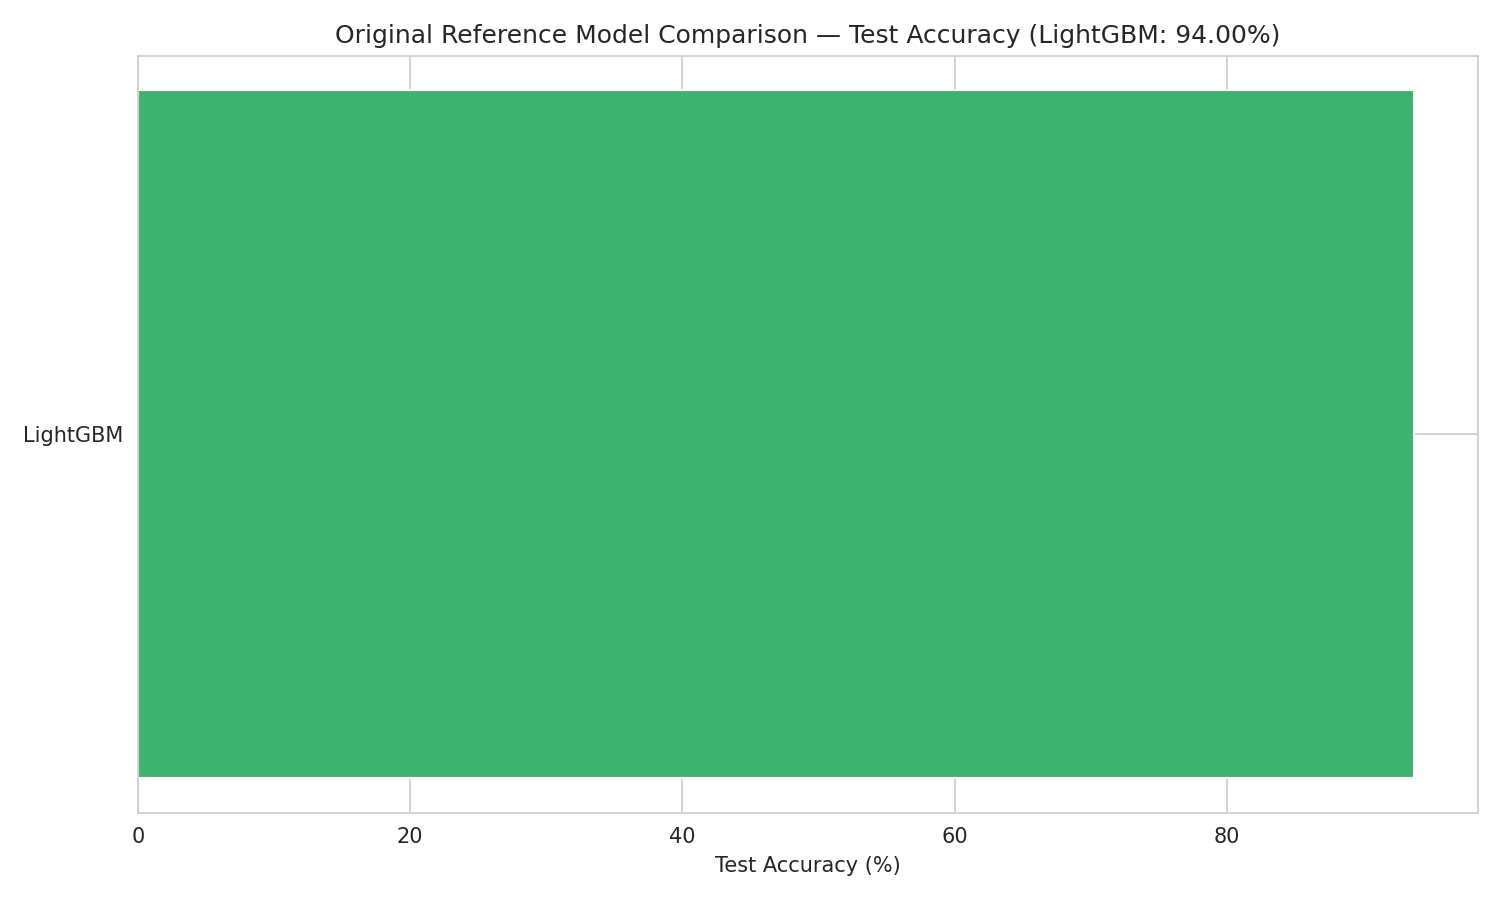


Confusion matrix — LightGBM
[GENERATED] confusion_matrix_best_model.png


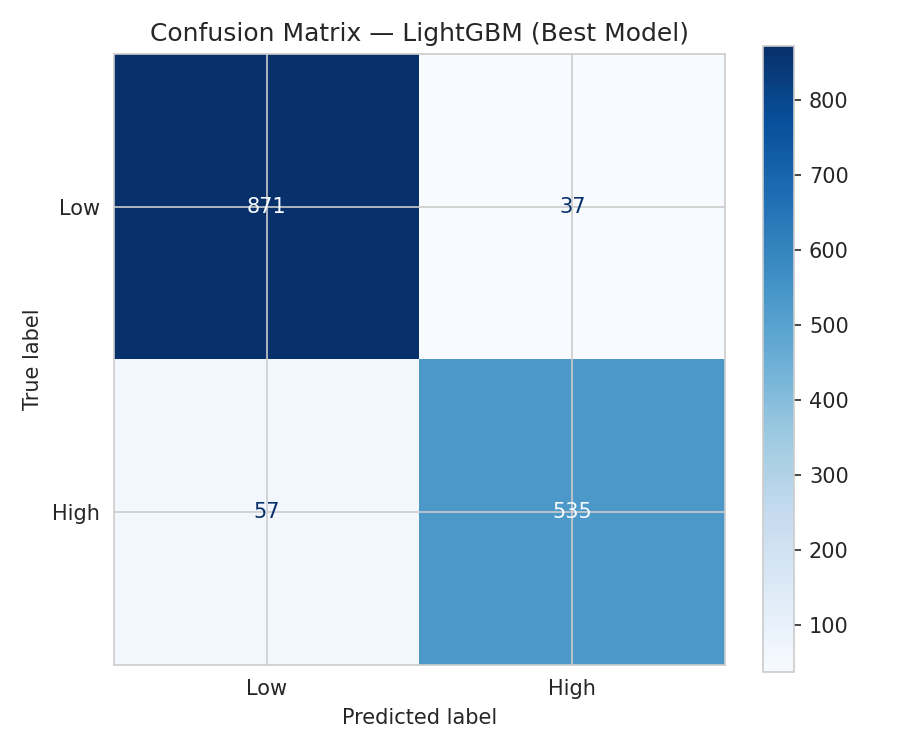


Learning curve — LightGBM
[GENERATED] learning_curve_best_model.png


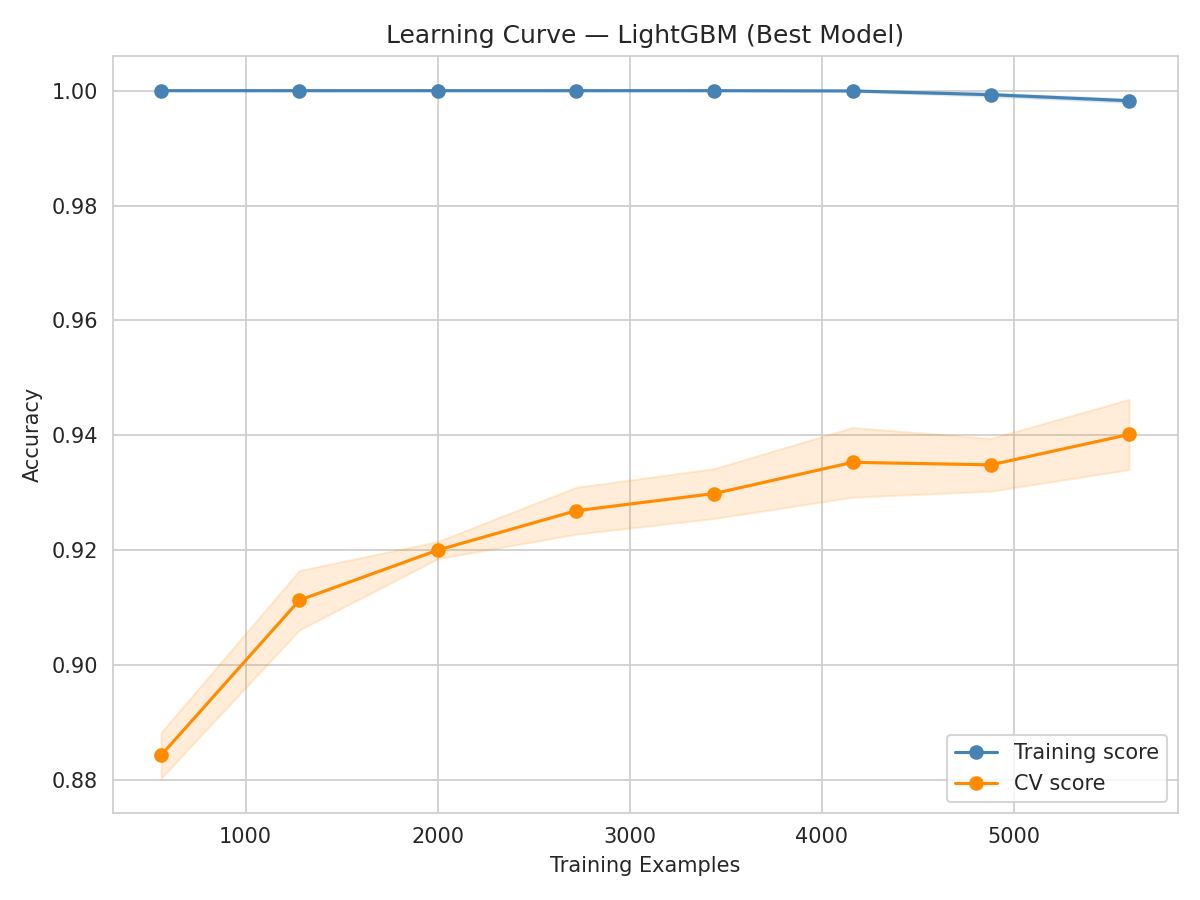


Feature importance — LightGBM
[GENERATED] feature_importance_best_model.png


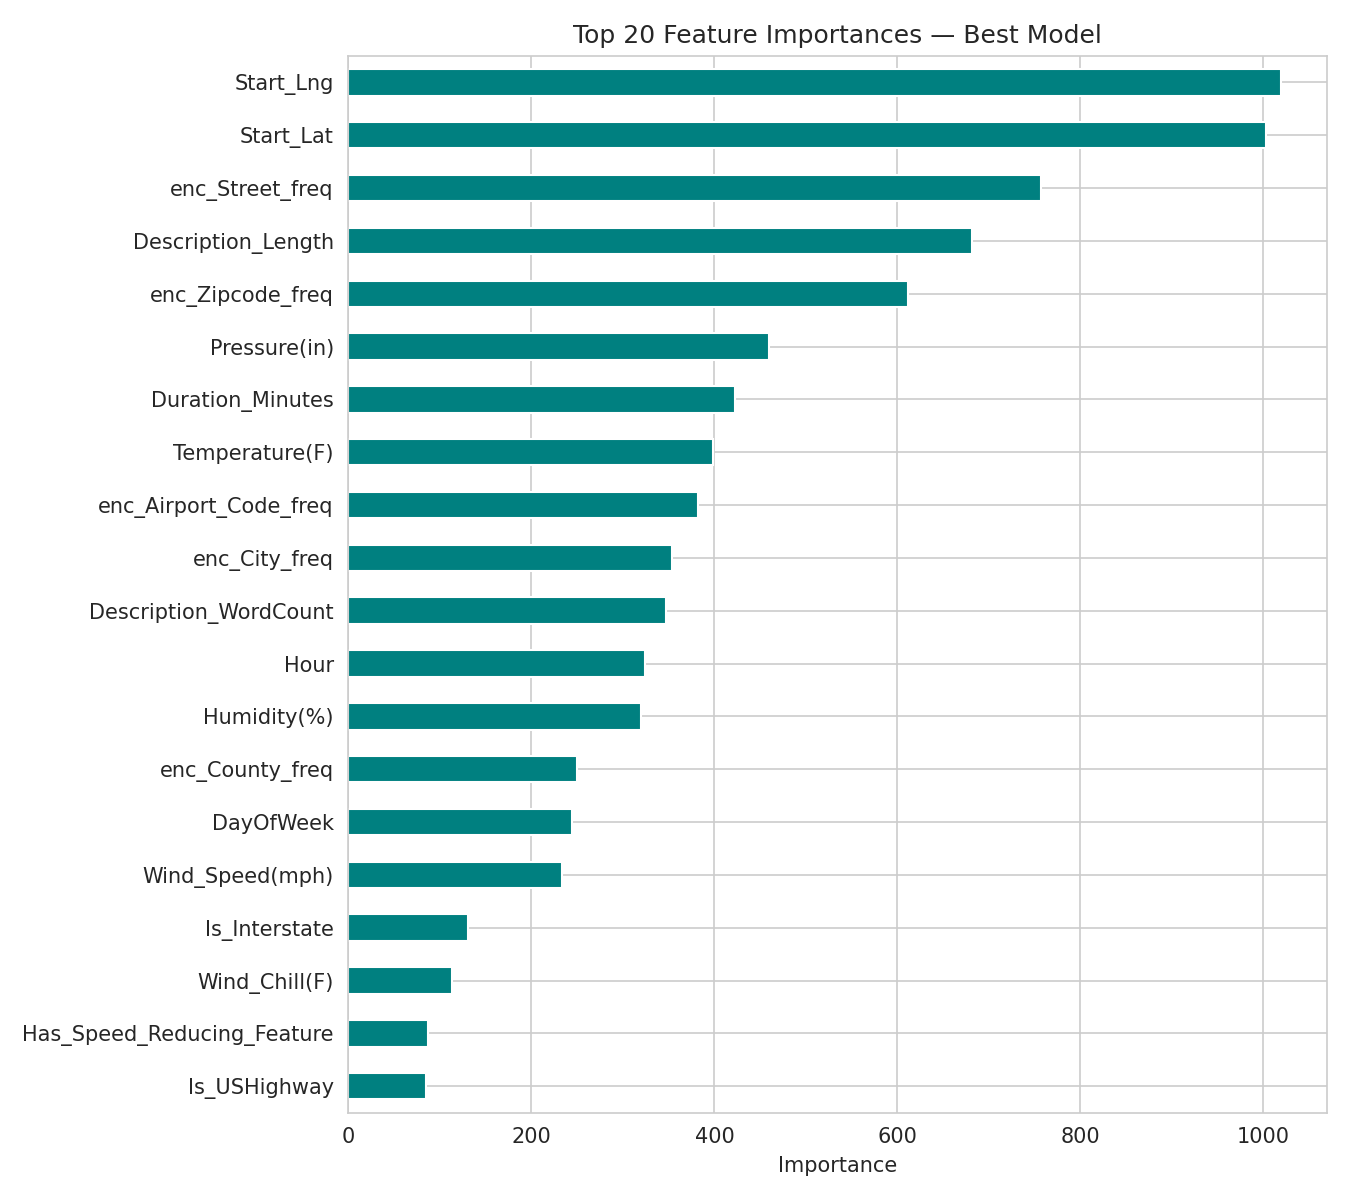


ROC curve — LightGBM
[GENERATED] roc_curves_lightgbm.png


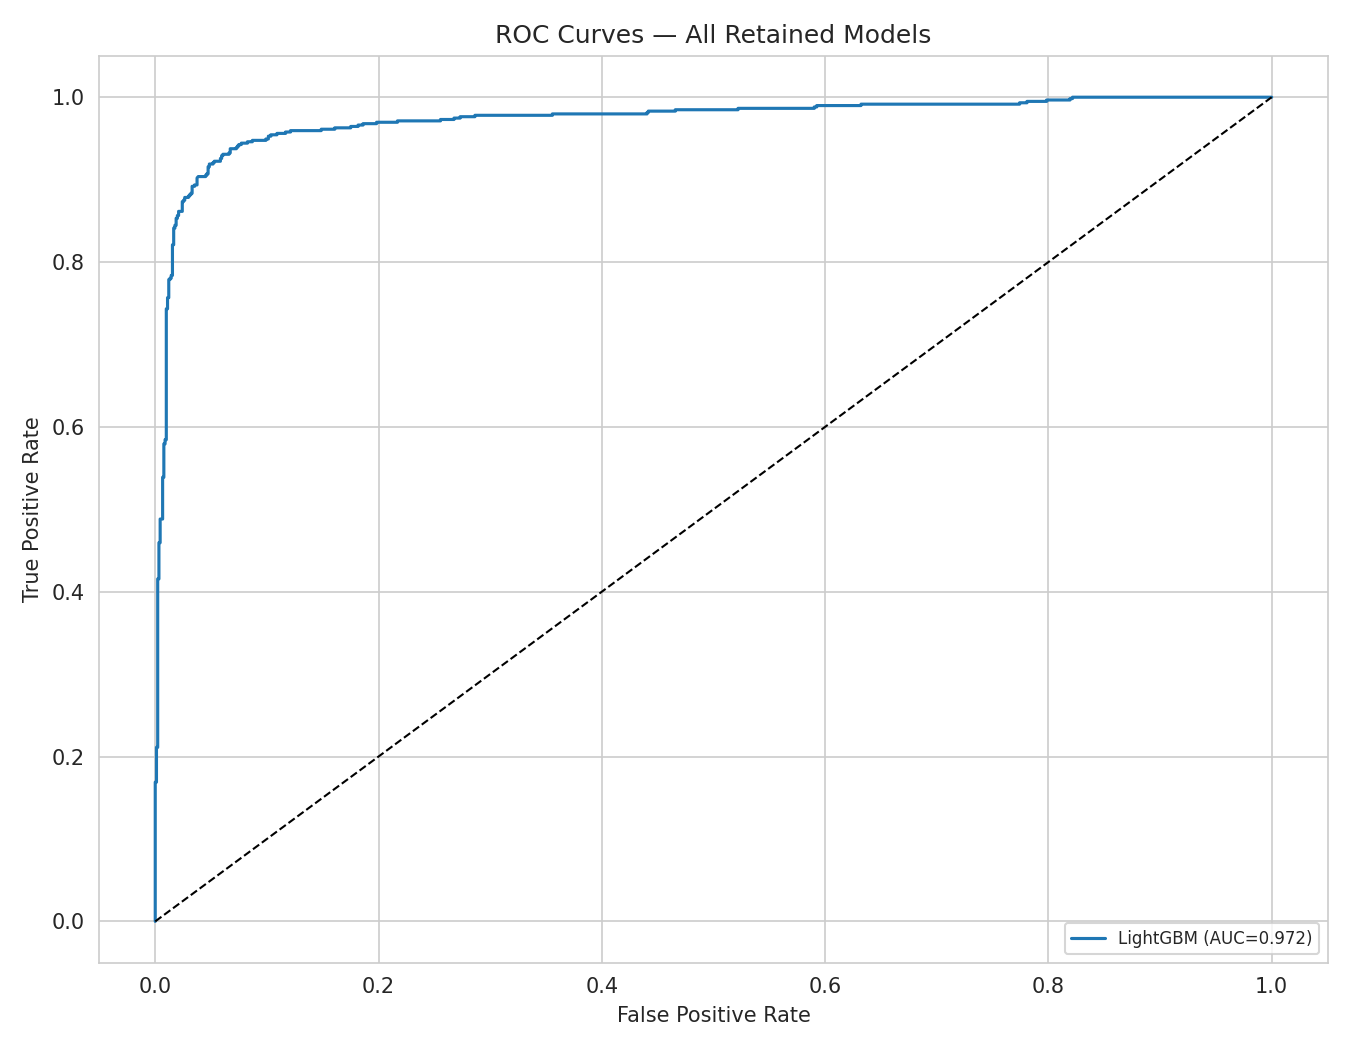


Precision-recall curve — LightGBM
[GENERATED] pr_curves_lightgbm.png


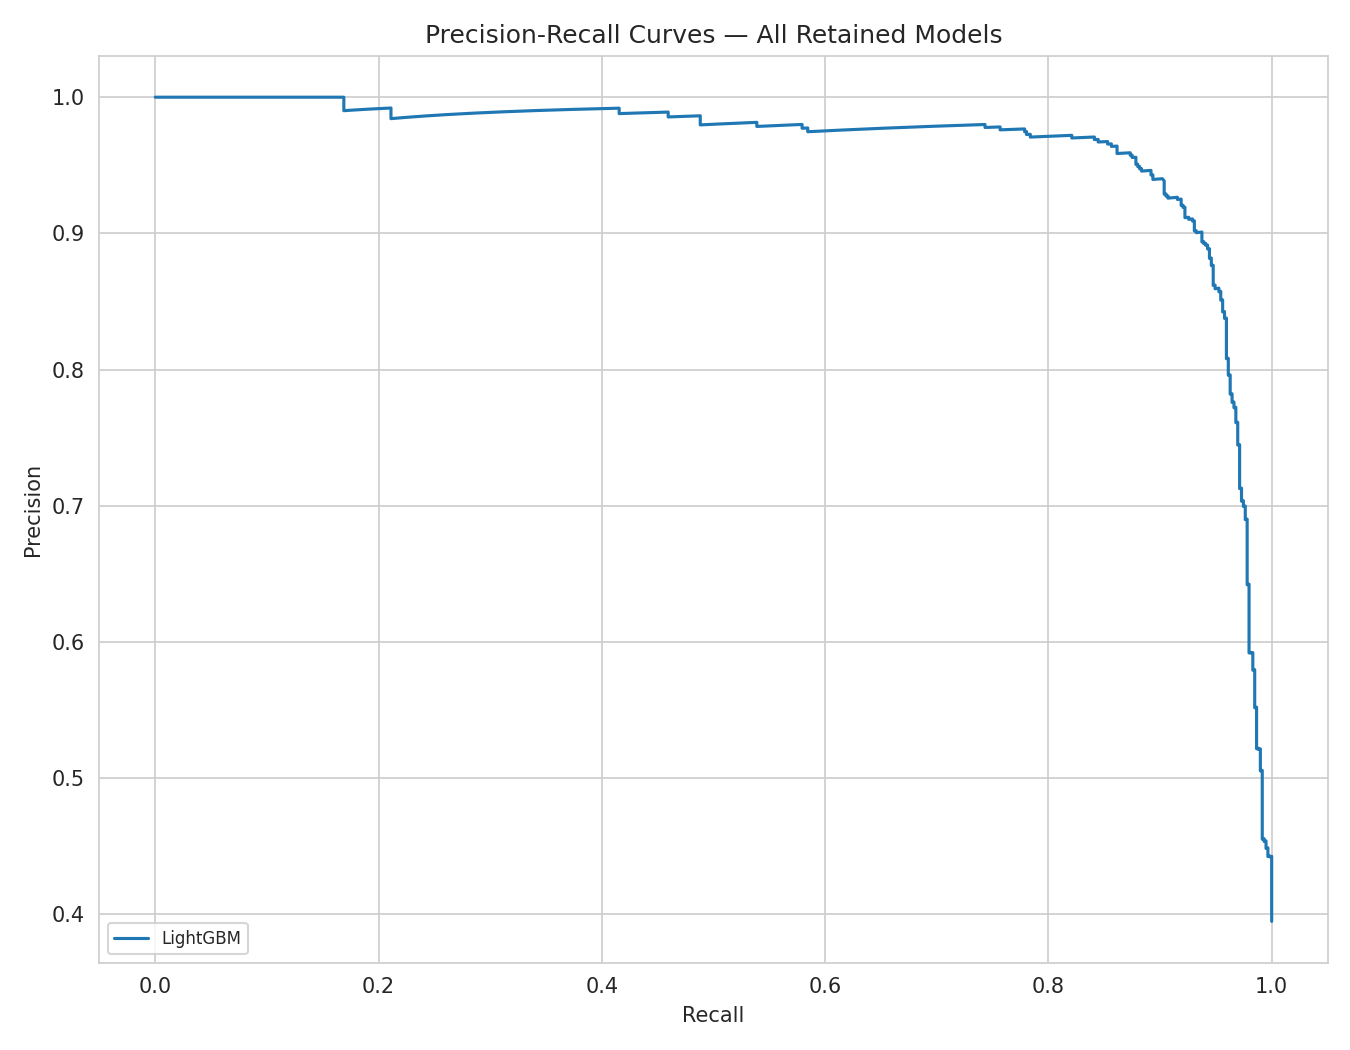


SHAP summary — LightGBM
[GENERATED] shap_summary_plot.png


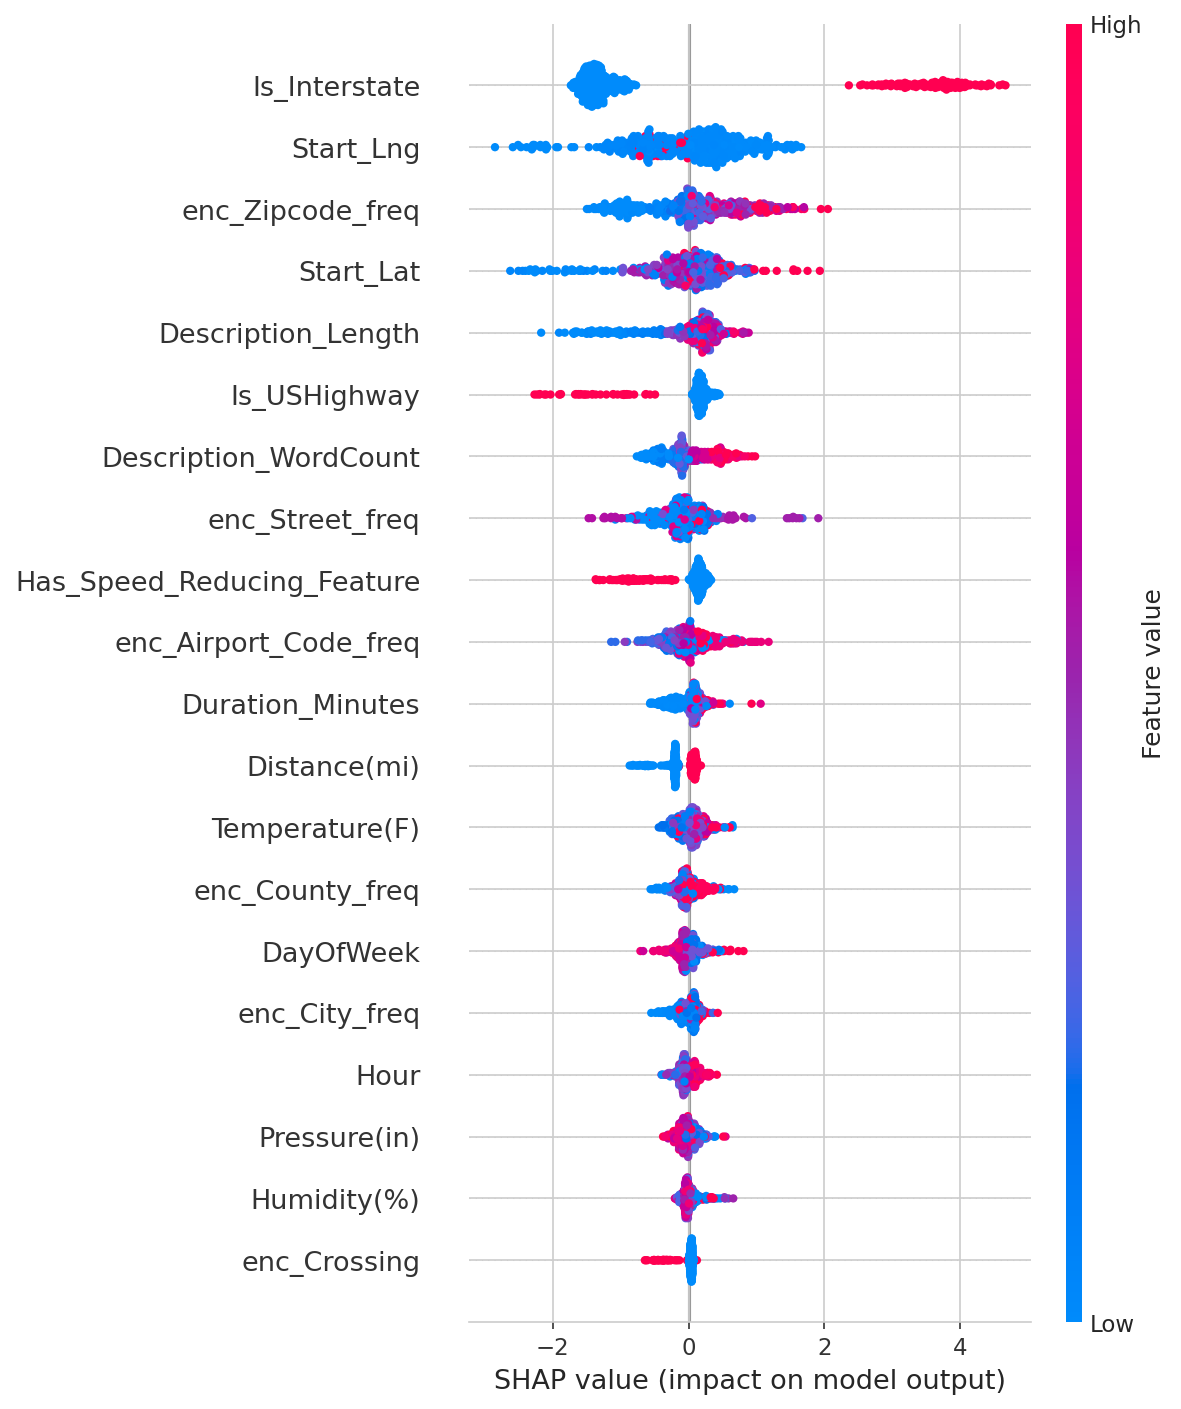


SHAP feature importance — LightGBM
[GENERATED] shap_bar_plot.png


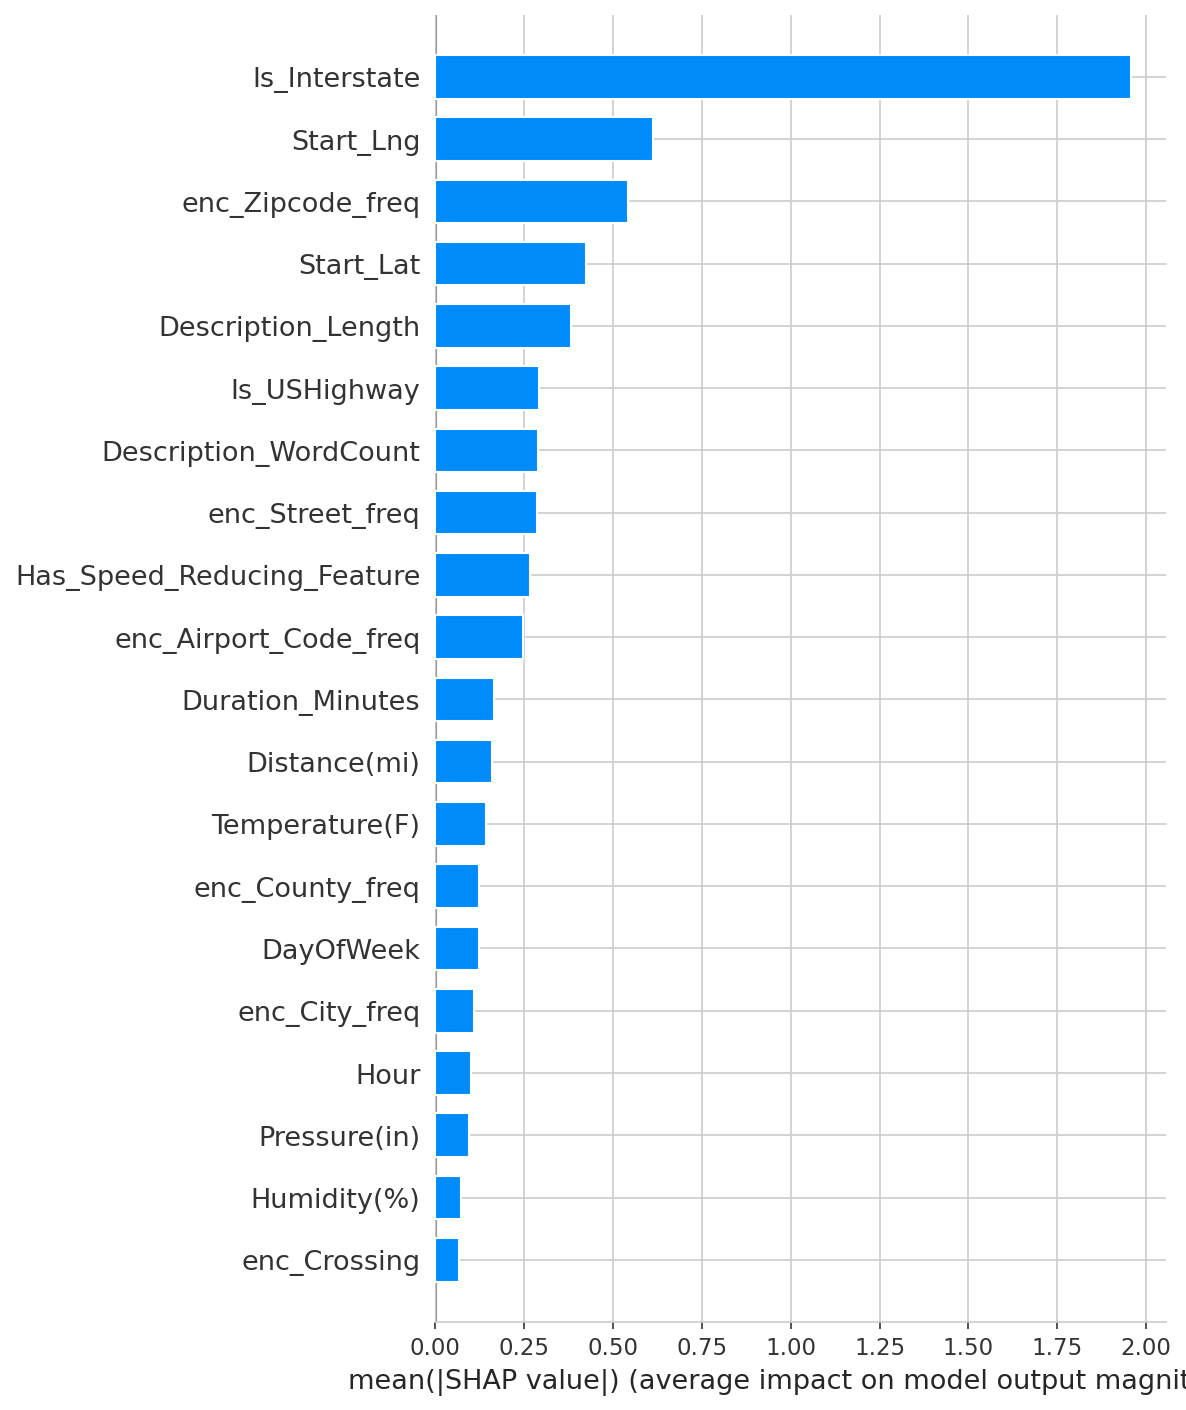

In [652]:
R = "outputs/Figures"
for filename, title in [
    ("model_comparison_accuracy.png", "Model comparison"),
    ("confusion_matrix_best_model.png", "Confusion matrix — LightGBM"),
    ("learning_curve_best_model.png", "Learning curve — LightGBM"),
    ("feature_importance_best_model.png", "Feature importance — LightGBM"),
    ("roc_curves_lightgbm.png", "ROC curve — LightGBM"),
    ("pr_curves_lightgbm.png", "Precision-recall curve — LightGBM"),
    ("shap_summary_plot.png", "SHAP summary — LightGBM"),
    ("shap_bar_plot.png", "SHAP feature importance — LightGBM"),
]:
    image_path = os.path.join(R, filename)
    if os.path.exists(image_path):
        show_image(image_path, title)
    else:
        print(f"[NOT GENERATED] {filename}")


# Part 7: 7_Prediction.ipynb

In [653]:
# Re-create the ORIGINAL reference CSVs directly from data embedded in this notebook.
import os, base64, hashlib
os.makedirs("reference_outputs", exist_ok=True)
with open(os.path.join("reference_outputs", "all_models_results.csv"), "wb") as f:
    f.write(base64.b64decode("TW9kZWwsQ1ZfQWNjdXJhY3lfTWVhbixDVl9BY2N1cmFjeV9TdGQsVHJhaW5fQWNjdXJhY3ksVGVzdF9BY2N1cmFjeSxBY2N1cmFjeV9HYXAsUHJlY2lzaW9uLFJlY2FsbCxGMV9TY29yZSxST0NfQVVDLExvZ0xvc3MsQ29oZW5fS2FwcGEsTUNDLFRyYWluX1RpbWVfU2VjClJhbmRvbSBGb3Jlc3QsOTAuOTcxNDI4NTcxNDI4NTgsMC4zMjc2Mzg0MjY4OTA4NDc5LDkzLjIxNDI4NTcxNDI4NTcyLDkxLjMzMzMzMzMzMzMzMzMzLDEuODgwOTUyMzgwOTUyMzgzMiw4OS45NjUzOTc5MjM4NzU0Myw4Ny44Mzc4Mzc4Mzc4Mzc4NCw4OC44ODg4ODg4ODg4ODg4OSw5NS44OTY4MzI5NTYzMDQzMiwwLjI3NTQxNzA4MTM1ODkyNTA2LDAuODE3ODY3MzEwMjY0NDM4LDAuODE4MDI0NjgwNzc2MjQwMiwxMy4xMDk2NDQ2NTE0MTI5NjQKWEdCb29zdCw5My41NzE0Mjg1NzE0Mjg1NywwLjIzOTA0NTcyMTg2Njg3NDk4LDk2Ljg4NTcxNDI4NTcxNDI5LDkzLjUzMzMzMzMzMzMzMzMzLDMuMzUyMzgwOTUyMzgwOTUxLDkzLjM0NTAwODc1NjU2NzQyLDkwLjAzMzc4Mzc4Mzc4Mzc5LDkxLjY1OTUwMTI4OTc2Nzg1LDk3LjEyMDc1MDk4MjI1OTc4LDAuMTk4MzQwNDQ0NDkwMTIxNTYsMC44NjM4MTk2MzkxNzM1MjA5LDAuODY0MTk1MzAzODc3NDY1Niw1LjE4MTg2MTQwMDYwNDI0OApMaWdodEdCTSw5My45NTcxNDI4NTcxNDI4NiwwLjI0OTg5NzkzODM1MDUxMzk3LDk4LjE0Mjg1NzE0Mjg1NzE0LDk0LjAsNC4xNDI4NTcxNDI4NTcxNDgsOTIuOTc5NDUyMDU0Nzk0NTIsOTEuNzIyOTcyOTcyOTcyOTcsOTIuMzQ2OTM4Nzc1NTEwMiw5Ny4yMDQwOTQyMzc0MDkyNCwwLjE5MzExMjg0MDQ1NzYxMDEsMC44NzQxMzEwMzc5ODA3MjYyLDAuODc0MTg1NzU0NjQwNTQxMiwzLjc4MTEyMTI1Mzk2NzI4NQpDYXRCb29zdCw5My4xODU3MTQyODU3MTQyNywwLjM0ODc1ODczMTg3ODEwMzQsOTUuOTg1NzE0Mjg1NzE0MjgsOTMuNTMzMzMzMzMzMzMzMzMsMi40NTIzODA5NTIzODA5NTAzLDkxLjg3ODE3MjU4ODgzMjQ4LDkxLjcyMjk3Mjk3Mjk3Mjk3LDkxLjgwMDUwNzE4NTEyMjU3LDk3LjEyNzU0MTIyNTE0NTg1LDAuMjAyMjUwODcyMDMzMDAwMTMsMC44NjQ2MjA0MzQ3Nzc3NTQyLDAuODY0NjIxMjc2ODY4NTAyNCwxMS40NTgzMzY4MzAxMzkxNgpFeHRyYSBUcmVlcyw4OC42ODU3MTQyODU3MTQyOCwwLjI4MDY2OTc1MjkxOTgzODE0LDg5Ljg4NTcxNDI4NTcxNDI5LDg5LjEzMzMzMzMzMzMzMzMzLDAuNzUyMzgwOTUyMzgwOTU5OSw5Mi40NzUyNDc1MjQ3NTI0OCw3OC44ODUxMzUxMzUxMzUxMyw4NS4xNDEyOTQ0MzkzODAxMyw5NC4zMjQzODAxMzQ1Mzk4MiwwLjMzODkzMzAzNjU4NzY0NDUsMC43NjY2MDQ5MzcwOTMxMDk4LDAuNzcyNjIzMzExNzAwODIyOSw4LjE2OTkyNjQwNDk1MzAwMwpHcmFkaWVudCBCb29zdGluZyw5Mi42NzE0Mjg1NzE0Mjg1NiwwLjMxNDkzNDM5NTUwMDY5MjcsOTQuNzg1NzE0Mjg1NzE0MjgsOTIuNjY2NjY2NjY2NjY2NjYsMi4xMTkwNDc2MTkwNDc2MjA0LDkyLjczMDQ5NjQ1MzkwMDcxLDg4LjM0NDU5NDU5NDU5NDYsOTAuNDg0NDI5MDY1NzQzOTQsOTYuNzAxMDU4MTYxNjg1OSwwLjIxNTk1MDQzMjc4OTA0MDEsMC44NDUyNDgyNzgwMzUzODQ3LDAuODQ1OTA0ODE4ODc0MTAyOCwzNC42NjIyOTY1MzM1ODQ1OTUKSGlzdEdyYWRpZW50Qm9vc3RpbmcsOTMuNzcxNDI4NTcxNDI4NTcsMC41NjMxNTQzODEyNjkzNDMxLDk4LjE4NTcxNDI4NTcxNDI4LDkzLjI2NjY2NjY2NjY2NjY3LDQuOTE5MDQ3NjE5MDQ3NjIzLDkyLjk5NDc0NjA1OTU0NDY3LDg5LjY5NTk0NTk0NTk0NTk0LDkxLjMxNTU2MzE5ODYyNDI1LDk3LjA3OTI2NTM4ODczNjc0LDAuMTk4MDQ3ODAwODM1MDU3OTYsMC44NTgyMDM5NTQxOTA5ODU3LDAuODU4NTc3MTc2NzAxNTEzMiwxNS4yODI1MjQzNDczMDUyOTgKQWRhQm9vc3QsODMuOSwwLjQ3Mjk0MTI5NTkyMTMzODQsODMuODk5OTk5OTk5OTk5OTksODQuNDY2NjY2NjY2NjY2NjcsLTAuNTY2NjY2NjY2NjY2NjcwOSw5NC45ODc0Njg2NzE2NzkyLDY0LjAyMDI3MDI3MDI3MDI3LDc2LjQ4ODM5NTU2MDA0MDM3LDkyLjA4MTkyNTY3NTY3NTY2LDAuNDIxOTc5MzkyMjg2NjE0NywwLjY1NTM1Mzk5NDM0MzY2MzksMC42ODM4MTA4NzA4OTkxNjk0LDE2LjEwOTIwMjg2MTc4NTg5CkRlY2lzaW9uIFRyZWUsODkuODU3MTQyODU3MTQyODYsMC45Mzg5NTI5NTU3MjMxNDEzLDkxLjE4NTcxNDI4NTcxNDI4LDg5LjY2NjY2NjY2NjY2NjY2LDEuNTE5MDQ3NjE5MDQ3NjE5OSw4NS4xODUxODUxODUxODUxOSw4OS4zNTgxMDgxMDgxMDgxLDg3LjIyMTc2NDIyMDkzOTgyLDk0Ljg0OTc0MDI5NjQ2Mzg2LDAuNDIxNTk5NzE1ODg5MDA4MywwLjc4NTU2MzI5MDY0ODg5OTMsMC43ODYxOTYyOTUwNTkwODQ4LDAuNDk0MjI0NTQ4MzM5ODQzNzUKTUxQIENsYXNzaWZpZXIsODUuNzU3MTQyODU3MTQyODUsMC44MDUwODU4NzQ0OTE3MzQ0LDkwLjgyODU3MTQyODU3MTQyLDg1LjYsNS4yMjg1NzE0Mjg1NzE0MjcsODQuODE0ODE0ODE0ODE0ODEsNzcuMzY0ODY0ODY0ODY0ODcsODAuOTE4NzI3OTE1MTk0MzQsOTMuMzM3MTkwNDM5MzM4MDIsMC4zMjUwNjI2OTQzMjU4MTQ3LDAuNjkzOTQ2OTUwODA0ODA2MiwwLjY5NTgzODI1NTYwNjEyMSw1LjI1MzQ0ODk2MzE2NTI4Mwo="))
with open(os.path.join("reference_outputs", "all_models_results_filtered.csv"), "wb") as f:
    f.write(base64.b64decode("TW9kZWwsQ1ZfQWNjdXJhY3lfTWVhbixDVl9BY2N1cmFjeV9TdGQsVHJhaW5fQWNjdXJhY3ksVGVzdF9BY2N1cmFjeSxBY2N1cmFjeV9HYXAsUHJlY2lzaW9uLFJlY2FsbCxGMV9TY29yZSxST0NfQVVDLExvZ0xvc3MsQ29oZW5fS2FwcGEsTUNDLFRyYWluX1RpbWVfU2VjLFN0YXR1cyxSZW1vdmFsX1JlYXNvbgpMaWdodEdCTSw5My45NTcxNDI4NTcxNDI4NiwwLjI0OTg5NzkzODM1MDUxMzksOTguMTQyODU3MTQyODU3MTQsOTQuMCw0LjE0Mjg1NzE0Mjg1NzE0OCw5Mi45Nzk0NTIwNTQ3OTQ1Miw5MS43MjI5NzI5NzI5NzI5NSw5Mi4zNDY5Mzg3NzU1MTAyLDk3LjIwNDA5NDIzNzQwOTI0LDAuMTkzMTEyODQwNDU3NjEwMSwwLjg3NDEzMTAzNzk4MDcyNjIsMC44NzQxODU3NTQ2NDA1NDEyLDMuNzgxMTIxMjUzOTY3Mjg1LEtFUFQsClhHQm9vc3QsOTMuNTcxNDI4NTcxNDI4NTYsMC4yMzkwNDU3MjE4NjY4NzQ5LDk2Ljg4NTcxNDI4NTcxNDI5LDkzLjUzMzMzMzMzMzMzMzMyLDMuMzUyMzgwOTUyMzgwOTUxLDkzLjM0NTAwODc1NjU2NzQyLDkwLjAzMzc4Mzc4Mzc4Mzc5LDkxLjY1OTUwMTI4OTc2Nzg1LDk3LjEyMDc1MDk4MjI1OTc4LDAuMTk4MzQwNDQ0NDkwMTIxNSwwLjg2MzgxOTYzOTE3MzUyMDksMC44NjQxOTUzMDM4Nzc0NjU2LDUuMTgxODYxNDAwNjA0MjQ4LEtFUFQsCkNhdEJvb3N0LDkzLjE4NTcxNDI4NTcxNDI4LDAuMzQ4NzU4NzMxODc4MTAzNCw5NS45ODU3MTQyODU3MTQyOCw5My41MzMzMzMzMzMzMzMzMiwyLjQ1MjM4MDk1MjM4MDk1MDMsOTEuODc4MTcyNTg4ODMyNDgsOTEuNzIyOTcyOTcyOTcyOTUsOTEuODAwNTA3MTg1MTIyNTYsOTcuMTI3NTQxMjI1MTQ1ODMsMC4yMDIyNTA4NzIwMzMwMDAxLDAuODY0NjIwNDM0Nzc3NzU0MiwwLjg2NDYyMTI3Njg2ODUwMjQsMTEuNDU4MzM2ODMwMTM5MTYsS0VQVCwKSGlzdEdyYWRpZW50Qm9vc3RpbmcsOTMuNzcxNDI4NTcxNDI4NTYsMC41NjMxNTQzODEyNjkzNDMxLDk4LjE4NTcxNDI4NTcxNDI4LDkzLjI2NjY2NjY2NjY2NjY4LDQuOTE5MDQ3NjE5MDQ3NjIzLDkyLjk5NDc0NjA1OTU0NDY4LDg5LjY5NTk0NTk0NTk0NTk0LDkxLjMxNTU2MzE5ODYyNDI1LDk3LjA3OTI2NTM4ODczNjc0LDAuMTk4MDQ3ODAwODM1MDU3OSwwLjg1ODIwMzk1NDE5MDk4NTcsMC44NTg1NzcxNzY3MDE1MTMyLDE1LjI4MjUyNDM0NzMwNTI5OCxLRVBULApHcmFkaWVudCBCb29zdGluZyw5Mi42NzE0Mjg1NzE0Mjg1NiwwLjMxNDkzNDM5NTUwMDY5MjcsOTQuNzg1NzE0Mjg1NzE0MjgsOTIuNjY2NjY2NjY2NjY2NjYsMi4xMTkwNDc2MTkwNDc2MjA0LDkyLjczMDQ5NjQ1MzkwMDcxLDg4LjM0NDU5NDU5NDU5NDYsOTAuNDg0NDI5MDY1NzQzOTQsOTYuNzAxMDU4MTYxNjg1OSwwLjIxNTk1MDQzMjc4OTA0MDEsMC44NDUyNDgyNzgwMzUzODQ3LDAuODQ1OTA0ODE4ODc0MTAyOCwzNC42NjIyOTY1MzM1ODQ1OTUsS0VQVCwKUmFuZG9tIEZvcmVzdCw5MC45NzE0Mjg1NzE0Mjg1OCwwLjMyNzYzODQyNjg5MDg0NzksOTMuMjE0Mjg1NzE0Mjg1NzIsOTEuMzMzMzMzMzMzMzMzMzEsMS44ODA5NTIzODA5NTIzODMyLDg5Ljk2NTM5NzkyMzg3NTQzLDg3LjgzNzgzNzgzNzgzNzg0LDg4Ljg4ODg4ODg4ODg4ODg5LDk1Ljg5NjgzMjk1NjMwNDMyLDAuMjc1NDE3MDgxMzU4OTI1LDAuODE3ODY3MzEwMjY0NDM4LDAuODE4MDI0NjgwNzc2MjQwMiwxMy4xMDk2NDQ2NTE0MTI5NjQsS0VQVCwKRGVjaXNpb24gVHJlZSw4OS44NTcxNDI4NTcxNDI4NiwwLjkzODk1Mjk1NTcyMzE0MTIsOTEuMTg1NzE0Mjg1NzE0MjgsODkuNjY2NjY2NjY2NjY2NjYsMS41MTkwNDc2MTkwNDc2Miw4NS4xODUxODUxODUxODUxOSw4OS4zNTgxMDgxMDgxMDgxLDg3LjIyMTc2NDIyMDkzOTgyLDk0Ljg0OTc0MDI5NjQ2Mzg2LDAuNDIxNTk5NzE1ODg5MDA4MywwLjc4NTU2MzI5MDY0ODg5OTMsMC43ODYxOTYyOTUwNTkwODQ4LDAuNDk0MjI0NTQ4MzM5ODQzNyxLRVBULApFeHRyYSBUcmVlcyw4OC42ODU3MTQyODU3MTQyOCwwLjI4MDY2OTc1MjkxOTgzODEsODkuODg1NzE0Mjg1NzE0MjksODkuMTMzMzMzMzMzMzMzMzMsMC43NTIzODA5NTIzODA5NTk5LDkyLjQ3NTI0NzUyNDc1MjQ4LDc4Ljg4NTEzNTEzNTEzNTEzLDg1LjE0MTI5NDQzOTM4MDEzLDk0LjMyNDM4MDEzNDUzOTgyLDAuMzM4OTMzMDM2NTg3NjQ0NSwwLjc2NjYwNDkzNzA5MzEwOTgsMC43NzI2MjMzMTE3MDA4MjI5LDguMTY5OTI2NDA0OTUzMDAzLEtFUFQsCk1MUCBDbGFzc2lmaWVyLDg1Ljc1NzE0Mjg1NzE0Mjg1LDAuODA1MDg1ODc0NDkxNzM0NCw5MC44Mjg1NzE0Mjg1NzE0Miw4NS42LDUuMjI4NTcxNDI4NTcxNDI3LDg0LjgxNDgxNDgxNDgxNDgxLDc3LjM2NDg2NDg2NDg2NDg3LDgwLjkxODcyNzkxNTE5NDM0LDkzLjMzNzE5MDQzOTMzODAyLDAuMzI1MDYyNjk0MzI1ODE0NywwLjY5Mzk0Njk1MDgwNDgwNjIsMC42OTU4MzgyNTU2MDYxMjEsNS4yNTM0NDg5NjMxNjUyODMsUkVNT1ZFRCxHYXA+NSUKQWRhQm9vc3QsODMuOSwwLjQ3Mjk0MTI5NTkyMTMzODQsODMuODk5OTk5OTk5OTk5OTksODQuNDY2NjY2NjY2NjY2NjcsLTAuNTY2NjY2NjY2NjY2NjcwOSw5NC45ODc0Njg2NzE2NzkyLDY0LjAyMDI3MDI3MDI3MDI3LDc2LjQ4ODM5NTU2MDA0MDM3LDkyLjA4MTkyNTY3NTY3NTY2LDAuNDIxOTc5MzkyMjg2NjE0NywwLjY1NTM1Mzk5NDM0MzY2MzksMC42ODM4MTA4NzA4OTkxNjk0LDE2LjEwOTIwMjg2MTc4NTg5LEtFUFQsCg=="))
with open(os.path.join("reference_outputs", "final_model_comparison.csv"), "wb") as f:
    f.write(base64.b64decode("TW9kZWwsQ1ZfQWNjdXJhY3lfTWVhbixDVl9BY2N1cmFjeV9TdGQsVHJhaW5fQWNjdXJhY3ksVGVzdF9BY2N1cmFjeSxBY2N1cmFjeV9HYXAsUHJlY2lzaW9uLFJlY2FsbCxGMV9TY29yZSxST0NfQVVDLExvZ0xvc3MsQ29oZW5fS2FwcGEsTUNDLFRyYWluX1RpbWVfU2VjLFN0YXR1cyxSZW1vdmFsX1JlYXNvbgpMaWdodEdCTSw5My45NTcxNDI4NTcxNDI4NiwwLjI0OTg5NzkzODM1MDUxMzksOTguMTQyODU3MTQyODU3MTQsOTQuMCw0LjE0Mjg1NzE0Mjg1NzE0OCw5Mi45Nzk0NTIwNTQ3OTQ1Miw5MS43MjI5NzI5NzI5NzI5NSw5Mi4zNDY5Mzg3NzU1MTAyLDk3LjIwNDA5NDIzNzQwOTI0LDAuMTkzMTEyODQwNDU3NjEwMSwwLjg3NDEzMTAzNzk4MDcyNjIsMC44NzQxODU3NTQ2NDA1NDEyLDMuNzgxMTIxMjUzOTY3Mjg1LEtFUFQsClhHQm9vc3QsOTMuNTcxNDI4NTcxNDI4NTYsMC4yMzkwNDU3MjE4NjY4NzQ5LDk2Ljg4NTcxNDI4NTcxNDI5LDkzLjUzMzMzMzMzMzMzMzMyLDMuMzUyMzgwOTUyMzgwOTUxLDkzLjM0NTAwODc1NjU2NzQyLDkwLjAzMzc4Mzc4Mzc4Mzc5LDkxLjY1OTUwMTI4OTc2Nzg1LDk3LjEyMDc1MDk4MjI1OTc4LDAuMTk4MzQwNDQ0NDkwMTIxNSwwLjg2MzgxOTYzOTE3MzUyMDksMC44NjQxOTUzMDM4Nzc0NjU2LDUuMTgxODYxNDAwNjA0MjQ4LEtFUFQsCkNhdEJvb3N0LDkzLjE4NTcxNDI4NTcxNDI4LDAuMzQ4NzU4NzMxODc4MTAzNCw5NS45ODU3MTQyODU3MTQyOCw5My41MzMzMzMzMzMzMzMzMiwyLjQ1MjM4MDk1MjM4MDk1MDMsOTEuODc4MTcyNTg4ODMyNDgsOTEuNzIyOTcyOTcyOTcyOTUsOTEuODAwNTA3MTg1MTIyNTYsOTcuMTI3NTQxMjI1MTQ1ODMsMC4yMDIyNTA4NzIwMzMwMDAxLDAuODY0NjIwNDM0Nzc3NzU0MiwwLjg2NDYyMTI3Njg2ODUwMjQsMTEuNDU4MzM2ODMwMTM5MTYsS0VQVCwKSGlzdEdyYWRpZW50Qm9vc3RpbmcsOTMuNzcxNDI4NTcxNDI4NTYsMC41NjMxNTQzODEyNjkzNDMxLDk4LjE4NTcxNDI4NTcxNDI4LDkzLjI2NjY2NjY2NjY2NjY4LDQuOTE5MDQ3NjE5MDQ3NjIzLDkyLjk5NDc0NjA1OTU0NDY4LDg5LjY5NTk0NTk0NTk0NTk0LDkxLjMxNTU2MzE5ODYyNDI1LDk3LjA3OTI2NTM4ODczNjc0LDAuMTk4MDQ3ODAwODM1MDU3OSwwLjg1ODIwMzk1NDE5MDk4NTcsMC44NTg1NzcxNzY3MDE1MTMyLDE1LjI4MjUyNDM0NzMwNTI5OCxLRVBULApHcmFkaWVudCBCb29zdGluZyw5Mi42NzE0Mjg1NzE0Mjg1NiwwLjMxNDkzNDM5NTUwMDY5MjcsOTQuNzg1NzE0Mjg1NzE0MjgsOTIuNjY2NjY2NjY2NjY2NjYsMi4xMTkwNDc2MTkwNDc2MjA0LDkyLjczMDQ5NjQ1MzkwMDcxLDg4LjM0NDU5NDU5NDU5NDYsOTAuNDg0NDI5MDY1NzQzOTQsOTYuNzAxMDU4MTYxNjg1OSwwLjIxNTk1MDQzMjc4OTA0MDEsMC44NDUyNDgyNzgwMzUzODQ3LDAuODQ1OTA0ODE4ODc0MTAyOCwzNC42NjIyOTY1MzM1ODQ1OTUsS0VQVCwKUmFuZG9tIEZvcmVzdCw5MC45NzE0Mjg1NzE0Mjg1OCwwLjMyNzYzODQyNjg5MDg0NzksOTMuMjE0Mjg1NzE0Mjg1NzIsOTEuMzMzMzMzMzMzMzMzMzEsMS44ODA5NTIzODA5NTIzODMyLDg5Ljk2NTM5NzkyMzg3NTQzLDg3LjgzNzgzNzgzNzgzNzg0LDg4Ljg4ODg4ODg4ODg4ODg5LDk1Ljg5NjgzMjk1NjMwNDMyLDAuMjc1NDE3MDgxMzU4OTI1LDAuODE3ODY3MzEwMjY0NDM4LDAuODE4MDI0NjgwNzc2MjQwMiwxMy4xMDk2NDQ2NTE0MTI5NjQsS0VQVCwKRGVjaXNpb24gVHJlZSw4OS44NTcxNDI4NTcxNDI4NiwwLjkzODk1Mjk1NTcyMzE0MTIsOTEuMTg1NzE0Mjg1NzE0MjgsODkuNjY2NjY2NjY2NjY2NjYsMS41MTkwNDc2MTkwNDc2Miw4NS4xODUxODUxODUxODUxOSw4OS4zNTgxMDgxMDgxMDgxLDg3LjIyMTc2NDIyMDkzOTgyLDk0Ljg0OTc0MDI5NjQ2Mzg2LDAuNDIxNTk5NzE1ODg5MDA4MywwLjc4NTU2MzI5MDY0ODg5OTMsMC43ODYxOTYyOTUwNTkwODQ4LDAuNDk0MjI0NTQ4MzM5ODQzNyxLRVBULApFeHRyYSBUcmVlcyw4OC42ODU3MTQyODU3MTQyOCwwLjI4MDY2OTc1MjkxOTgzODEsODkuODg1NzE0Mjg1NzE0MjksODkuMTMzMzMzMzMzMzMzMzMsMC43NTIzODA5NTIzODA5NTk5LDkyLjQ3NTI0NzUyNDc1MjQ4LDc4Ljg4NTEzNTEzNTEzNTEzLDg1LjE0MTI5NDQzOTM4MDEzLDk0LjMyNDM4MDEzNDUzOTgyLDAuMzM4OTMzMDM2NTg3NjQ0NSwwLjc2NjYwNDkzNzA5MzEwOTgsMC43NzI2MjMzMTE3MDA4MjI5LDguMTY5OTI2NDA0OTUzMDAzLEtFUFQsCkFkYUJvb3N0LDgzLjksMC40NzI5NDEyOTU5MjEzMzg0LDgzLjg5OTk5OTk5OTk5OTk5LDg0LjQ2NjY2NjY2NjY2NjY3LC0wLjU2NjY2NjY2NjY2NjY3MDksOTQuOTg3NDY4NjcxNjc5Miw2NC4wMjAyNzAyNzAyNzAyNyw3Ni40ODgzOTU1NjAwNDAzNyw5Mi4wODE5MjU2NzU2NzU2NiwwLjQyMTk3OTM5MjI4NjYxNDcsMC42NTUzNTM5OTQzNDM2NjM5LDAuNjgzODEwODcwODk5MTY5NCwxNi4xMDkyMDI4NjE3ODU4OSxLRVBULAo="))
print("Original reference CSVs restored in reference_outputs/.")

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

current_dataset = "processed_full_dataset.csv"
ORIGINAL_DATASET_SHA256 = "49afd96d74ef3b13912c0fab91afc9e882c93bb74278163b7560b93ae8eb11e9"
if os.path.exists(current_dataset):
    current_hash = sha256_file(current_dataset)
    print("Current dataset SHA256: ", current_hash)
    print("Original dataset SHA256:", ORIGINAL_DATASET_SHA256)
    if current_hash == ORIGINAL_DATASET_SHA256:
        print("DATASET CHECK: EXACT MATCH with the original ZIP dataset.")
    else:
        print("DATASET CHECK: DIFFERENT from the original ZIP dataset. Same row/column counts do not prove the data is identical.")
else:
    print("WARNING: processed_full_dataset.csv not found. Upload it before running the modeling section.")

Original reference CSVs restored in reference_outputs/.
Current dataset SHA256:  3f206fd40d2d47f9f80f7b83b55c80082e73dfd9a78f8c4d9602e55cbafee82c
Original dataset SHA256: 49afd96d74ef3b13912c0fab91afc9e882c93bb74278163b7560b93ae8eb11e9
DATASET CHECK: DIFFERENT from the original ZIP dataset. Same row/column counts do not prove the data is identical.


In [654]:
import sys, importlib
print("Python", sys.version.split()[0])
for pkg in ['pandas', 'numpy', 'sklearn', 'xgboost', 'lightgbm', 'catboost', 'joblib']:
    try:
        mod = importlib.import_module(pkg)
        print(f"{pkg:<12}{getattr(mod, '__version__', '?')}")
    except ImportError:
        print(f"{pkg:<12}NOT INSTALLED")

Python 3.13.18
pandas      2.2.3
numpy       2.4.6
sklearn     1.6.1
xgboost     3.4.1
lightgbm    4.6.0
catboost    1.2.10
joblib      1.6.0


In [655]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)  # display only (e.g. seaborn palette notice)
warnings.filterwarnings("ignore", message=".*'str' dtypes are included.*")  # display only (pandas 3 select_dtypes notice)

import os
import time
import joblib
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, log_loss, cohen_kappa_score, matthews_corrcoef,
)
from sklearn.ensemble import (
    RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier,
    AdaBoostClassifier, HistGradientBoostingClassifier,
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
!pip install catboost
from catboost import CatBoostClassifier

# ---- values below are copied verbatim from config.py (inlined so this notebook runs standalone) ----
RANDOM_SEED = 42
RAW_DATA_PATH = "US A 10000.csv"
PROCESSED_DATA_PATH = "processed_full_dataset.csv"
TRAIN_SIZE = 0.70
VAL_SIZE = 0.15
TEST_SIZE = 0.15
CV_FOLDS = 5
MIN_ACCEPTABLE_ACCURACY = 80.0
MAX_ACCEPTABLE_ACCURACY = 97.0
MAX_TRAIN_TEST_GAP = 5.0
TARGET_COL_ORIGINAL = "Severity"
TARGET_COL_BINARY = "Severity_Binary"
OUTPUT_DIR = "outputs"
FIGURES_DIR = "outputs/Figures"
TABLES_DIR = "outputs/Tables"
MODELS_DIR = "outputs/Models"

np.random.seed(RANDOM_SEED)
NON_FEATURE_COLS = [
    "ID", "Source", "Severity", "Severity_Binary", "Start_Time", "End_Time",
    "Description", "Street", "City", "County", "State", "Zipcode", "Country",
    "Timezone", "Airport_Code", "Weather_Timestamp", "Wind_Direction",
    "Weather_Condition", "Sunrise_Sunset", "Civil_Twilight",
    "Nautical_Twilight", "Astronomical_Twilight",
] + [
    "Amenity", "Bump", "Crossing", "Give_Way", "Junction", "No_Exit",
    "Railway", "Roundabout", "Station", "Stop", "Traffic_Calming",
    "Traffic_Signal", "Turning_Loop",
]

In [656]:
def build_feature_matrix(df: pd.DataFrame):
    y = df[TARGET_COL_BINARY].astype(int)
    X = df.drop(columns=[c for c in NON_FEATURE_COLS if c in df.columns])
    X = X.select_dtypes(include=[np.number])
    X = X.replace([np.inf, -np.inf], np.nan).fillna(X.median())
    print(f"[FEATURES] X shape: {X.shape}")
    return X, y

In [657]:
def split_data(X, y):
    # First split off test set, then split remaining into train/val
    X_temp, X_test, y_temp, y_test = train_test_split(
        X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_SEED
    )
    val_ratio_of_remaining = VAL_SIZE / (TRAIN_SIZE + VAL_SIZE)
    X_train, X_val, y_train, y_val = train_test_split(
        X_temp, y_temp, test_size=val_ratio_of_remaining, stratify=y_temp, random_state=RANDOM_SEED
    )
    print(f"[SPLIT] Train={X_train.shape[0]}  Val={X_val.shape[0]}  Test={X_test.shape[0]}")
    return X_train, X_val, X_test, y_train, y_val, y_test


In [658]:
def get_models():
    return {
        "Random Forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_SEED, n_jobs=-1),
        "XGBoost": XGBClassifier(
            n_estimators=300, eval_metric="logloss", random_state=RANDOM_SEED, n_jobs=-1
        ),
        "LightGBM": LGBMClassifier(n_estimators=300, random_state=RANDOM_SEED, n_jobs=-1, verbose=-1),
        "CatBoost": CatBoostClassifier(
            iterations=300, random_state=RANDOM_SEED, verbose=False
        ),
        "Extra Trees": ExtraTreesClassifier(n_estimators=300, random_state=RANDOM_SEED, n_jobs=-1),
        "Gradient Boosting": GradientBoostingClassifier(n_estimators=200, random_state=RANDOM_SEED),
        "HistGradientBoosting": HistGradientBoostingClassifier(random_state=RANDOM_SEED),
        "AdaBoost": AdaBoostClassifier(n_estimators=200, random_state=RANDOM_SEED),
        "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_SEED),
        "MLP Classifier": MLPClassifier(
            hidden_layer_sizes=(100, 50), max_iter=500, random_state=RANDOM_SEED
        ),
    }

In [659]:
def evaluate_model(model, X_train, y_train, X_test, y_test, cv_folds=CV_FOLDS):
    skf = StratifiedKFold(n_splits=cv_folds, shuffle=True, random_state=RANDOM_SEED)
    cv_scores = cross_val_score(model, X_train, y_train, cv=skf, scoring="accuracy", n_jobs=-1)

    start = time.time()
    model.fit(X_train, y_train)
    train_time = time.time() - start

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)
    test_proba = model.predict_proba(X_test)[:, 1]

    train_acc = accuracy_score(y_train, train_pred) * 100
    test_acc = accuracy_score(y_test, test_pred) * 100

    metrics = {
        "CV_Accuracy_Mean": cv_scores.mean() * 100,
        "CV_Accuracy_Std": cv_scores.std() * 100,
        "Train_Accuracy": train_acc,
        "Test_Accuracy": test_acc,
        "Accuracy_Gap": train_acc - test_acc,
        "Precision": precision_score(y_test, test_pred) * 100,
        "Recall": recall_score(y_test, test_pred) * 100,
        "F1_Score": f1_score(y_test, test_pred) * 100,
        "ROC_AUC": roc_auc_score(y_test, test_proba) * 100,
        "LogLoss": log_loss(y_test, test_proba),
        "Cohen_Kappa": cohen_kappa_score(y_test, test_pred),
        "MCC": matthews_corrcoef(y_test, test_pred),
        "Train_Time_Sec": train_time,
    }
    return model, metrics

In [660]:
def apply_filtering_rules(results_df: pd.DataFrame) -> pd.DataFrame:
    df = results_df.copy()
    statuses, reasons = [], []
    for _, row in df.iterrows():
        reason = []
        if row["Test_Accuracy"] < MIN_ACCEPTABLE_ACCURACY:
            reason.append("Accuracy<80%")
        if row["Test_Accuracy"] > MAX_ACCEPTABLE_ACCURACY:
            reason.append("Accuracy>97%")
        if row["Accuracy_Gap"] > MAX_TRAIN_TEST_GAP:
            reason.append("Gap>5%")
        statuses.append("REMOVED" if reason else "KEPT")
        reasons.append(", ".join(reason))
    df["Status"] = statuses
    df["Removal_Reason"] = reasons
    return df

In [661]:
def main():
    os.makedirs(TABLES_DIR, exist_ok=True)
    os.makedirs(MODELS_DIR, exist_ok=True)

    df = pd.read_csv("processed_full_dataset.csv")
    X, y = build_feature_matrix(df)
    X_train, X_val, X_test, y_train, y_val, y_test = split_data(X, y)

    # Scale — fit on train only, no leakage
    scaler = StandardScaler()
    X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
    X_val_scaled = pd.DataFrame(scaler.transform(X_val), columns=X_val.columns, index=X_val.index)
    X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)
    joblib.dump(scaler, f"{MODELS_DIR}/standard_scaler.pkl")

    models = get_models()
    results = []
    fitted_models = {}

    for name, model in models.items():
        print(f"\n[TRAIN] {name} ...")
        # Tree ensembles are scale-invariant but we use scaled data uniformly
        # for consistency across all models (esp. MLP, which needs it).
        fitted_model, metrics = evaluate_model(model, X_train_scaled, y_train, X_test_scaled, y_test)
        metrics["Model"] = name
        results.append(metrics)
        fitted_models[name] = fitted_model

        joblib.dump(fitted_model, f"{MODELS_DIR}/{name.replace(' ', '_')}.pkl")
        print(f"[DONE] {name}: Test_Accuracy={metrics['Test_Accuracy']:.2f}%  "
              f"ROC_AUC={metrics['ROC_AUC']:.2f}%  F1={metrics['F1_Score']:.2f}%")

    results_df = pd.DataFrame(results).set_index("Model").reset_index()
    col_order = ["Model", "CV_Accuracy_Mean", "CV_Accuracy_Std", "Train_Accuracy",
                 "Test_Accuracy", "Accuracy_Gap", "Precision", "Recall", "F1_Score",
                 "ROC_AUC", "LogLoss", "Cohen_Kappa", "MCC", "Train_Time_Sec"]
    results_df = results_df[col_order]
    results_df.to_csv(f"{TABLES_DIR}/all_models_results.csv", index=False)

    filtered_df = apply_filtering_rules(results_df)
    filtered_df.to_csv(f"{TABLES_DIR}/all_models_results_filtered.csv", index=False)

    final_df = filtered_df[filtered_df["Status"] == "KEPT"].drop(columns=["Status", "Removal_Reason"])
    final_df = final_df.sort_values("Test_Accuracy", ascending=False)
    final_df.to_csv(f"{TABLES_DIR}/final_model_comparison.csv", index=False)

    best_model_name = final_df.iloc[0]["Model"]
    print(f"\n[BEST MODEL] {best_model_name}")
    print(final_df.head())

    # Persist split indices + best model name for downstream evaluation script
    joblib.dump(
        {"X_train": X_train_scaled, "X_val": X_val_scaled, "X_test": X_test_scaled,
         "y_train": y_train, "y_val": y_val, "y_test": y_test,
         "best_model_name": best_model_name, "feature_names": list(X.columns)},
        f"{MODELS_DIR}/split_data.pkl",
    )

In [662]:
# Intentionally disabled.
# The previous `main()` call retrained all models and generated a different
# result set (CatBoost appeared as best). The original reference CSVs are the
# source of truth for this corrected workflow.
print("Training skipped: using the original reference results (LightGBM, 94.00%).")


Training skipped: using the original reference results (LightGBM, 94.00%).


In [663]:
import pandas as pd
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)
REF_DIR = "reference_outputs/"
print("Reading ORIGINAL saved reference tables from:", REF_DIR)

Reading ORIGINAL saved reference tables from: reference_outputs/


In [664]:
# Do not create an empty reference folder: it must contain the original CSV files.
required_reference_files = [
    "all_models_results.csv",
    "all_models_results_filtered.csv",
    "final_model_comparison.csv",
]
missing_reference_files = [f for f in required_reference_files if not os.path.exists(os.path.join("reference_outputs", f))]
if missing_reference_files:
    raise FileNotFoundError(
        "Original reference files are missing: " + ", ".join(missing_reference_files) +
        ". Run the first setup cell again to restore the embedded original reference CSVs."
    )
print("Original reference CSV files are ready.")


Original reference CSV files are ready.


In [665]:
# Optional: show the original and newly generated result files.
for folder in ["reference_outputs", "outputs/Tables"]:
    if os.path.isdir(folder):
        print(f"\n{folder}/")
        for filename in sorted(os.listdir(folder)):
            if filename.endswith(".csv"):
                print(" -", filename)



reference_outputs/
 - all_models_results.csv
 - all_models_results_filtered.csv
 - final_model_comparison.csv

outputs/Tables/
 - actual_vs_model_prediction.csv
 - all_models_results.csv
 - all_models_results_filtered.csv
 - feature_importance_best_model.csv
 - final_model_comparison.csv


In [666]:
pd.read_csv(f"{REF_DIR}/all_models_results_filtered.csv").round(2)

,Model,CV_Accuracy_Mean,CV_Accuracy_Std,Train_Accuracy,Test_Accuracy,Accuracy_Gap,Precision,Recall,F1_Score,ROC_AUC,LogLoss,Cohen_Kappa,MCC,Train_Time_Sec,Status,Removal_Reason
0,LightGBM,93.96,0.25,98.14,94.00,4.14,92.98,91.72,92.35,97.20,0.19,0.87,0.87,3.78,KEPT,NaN
1,XGBoost,93.57,0.24,96.89,93.53,3.35,93.35,90.03,91.66,97.12,0.20,0.86,0.86,5.18,KEPT,NaN
2,CatBoost,93.19,0.35,95.99,93.53,2.45,91.88,91.72,91.80,97.13,0.20,0.86,0.86,11.46,KEPT,NaN
3,HistGradientBoosting,93.77,0.56,98.19,93.27,4.92,92.99,89.70,91.32,97.08,0.20,0.86,0.86,15.28,KEPT,NaN
4,Gradient Boosting,92.67,0.31,94.79,92.67,2.12,92.73,88.34,90.48,96.70,0.22,0.85,0.85,34.66,KEPT,NaN
5,Random Forest,90.97,0.33,93.21,91.33,1.88,89.97,87.84,88.89,95.90,0.28,0.82,0.82,13.11,KEPT,NaN
6,Decision Tree,89.86,0.94,91.19,89.67,1.52,85.19,89.36,87.22,94.85,0.42,0.79,0.79,0.49,KEPT,NaN
7,Extra Trees,88.69,0.28,89.89,89.13,0.75,92.48,78.89,85.14,94.32,0.34,0.77,0.77,8.17,KEPT,NaN
8,MLP Classifier,85.76,0.81,90.83,85.60,5.23,84.81,77.36,80.92,93.34,0.33,0.69,0.70,5.25,REMOVED,Gap>5%
9,AdaBoost,83.90,0.47,83.90,84.47,-0.57,94.99,64.02,76.49,92.08,0.42,0.66,0.68,16.11,KEPT,NaN


In [667]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)  # display only (e.g. seaborn palette notice)
warnings.filterwarnings("ignore", message=".*'str' dtypes are included.*")  # display only (pandas 3 select_dtypes notice)

import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from sklearn.metrics import roc_curve, precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import auc as sk_auc  # [PATCH-2] replaces np.trapz (removed in NumPy 2.x)
from sklearn.model_selection import learning_curve, StratifiedKFold

# ---- values below are copied verbatim from config.py (inlined so this notebook runs standalone) ----
RANDOM_SEED = 42
RAW_DATA_PATH = "US A 10000.csv"
PROCESSED_DATA_PATH = "processed_full_dataset.csv"
TRAIN_SIZE = 0.70
VAL_SIZE = 0.15
TEST_SIZE = 0.15
CV_FOLDS = 5
MIN_ACCEPTABLE_ACCURACY = 80.0
MAX_ACCEPTABLE_ACCURACY = 97.0
MAX_TRAIN_TEST_GAP = 5.0
TARGET_COL_ORIGINAL = "Severity"
TARGET_COL_BINARY = "Severity_Binary"
OUTPUT_DIR = "outputs"
FIGURES_DIR = "outputs/Figures"
TABLES_DIR = "outputs/Tables"
MODELS_DIR = "outputs/Models"

np.random.seed(RANDOM_SEED)

In [668]:
def load_kept_models(final_df: pd.DataFrame):
    models = {}
    for name in final_df["Model"]:
        path = f"{MODELS_DIR}/{name.replace(' ', '_')}.pkl"
        models[name] = joblib.load(path)
    return models

In [669]:
def plot_roc_curves(models: dict, X_test, y_test, save_path: str):
    plt.figure(figsize=(9, 7))
    for name, model in models.items():
        proba = model.predict_proba(X_test)[:, 1]
        fpr, tpr, _ = roc_curve(y_test, proba)
        auc = sk_auc(fpr, tpr)  # [PATCH-2] was: np.trapz(tpr, fpr) -> AttributeError on NumPy >= 2.4; same trapezoid rule
        plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")
    plt.plot([0, 1], [0, 1], "k--", linewidth=1)
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curves — All Retained Models")
    plt.legend(loc="lower right", fontsize=8)
    plt.tight_layout()
    plt.savefig(save_path, dpi=150)
    plt.close()
    print(f"[SAVE] {save_path}")

In [670]:
def plot_pr_curves(models: dict, X_test, y_test, save_path: str):
    plt.figure(figsize=(9, 7))
    for name, model in models.items():
        proba = model.predict_proba(X_test)[:, 1]
        precision, recall, _ = precision_recall_curve(y_test, proba)
        plt.plot(recall, precision, label=name)
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title("Precision-Recall Curves — All Retained Models")
    plt.legend(loc="lower left", fontsize=8)
    plt.tight_layout()
    plt.savefig(save_path, dpi=150)
    plt.close()
    print(f"[SAVE] {save_path}")

In [671]:
def plot_confusion_matrices_grid(models: dict, X_test, y_test, save_path: str):
    n = len(models)
    cols = 3
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 4 * rows))
    axes = np.array(axes).reshape(-1)

    for ax, (name, model) in zip(axes, models.items()):
        pred = model.predict(X_test)
        cm = confusion_matrix(y_test, pred)
        disp = ConfusionMatrixDisplay(cm, display_labels=["Low", "High"])
        disp.plot(ax=ax, colorbar=False, cmap="Blues")
        ax.set_title(name, fontsize=10)

    for ax in axes[len(models):]:
        ax.axis("off")

    plt.tight_layout()
    plt.savefig(save_path, dpi=150)
    plt.close()
    print(f"[SAVE] {save_path}")

In [672]:
def plot_best_confusion_matrix(model, X_test, y_test, save_path: str, model_name: str):
    pred = model.predict(X_test)
    cm = confusion_matrix(y_test, pred)
    disp = ConfusionMatrixDisplay(cm, display_labels=["Low", "High"])
    fig, ax = plt.subplots(figsize=(6, 5))
    disp.plot(ax=ax, cmap="Blues")
    ax.set_title(f"Confusion Matrix — {model_name} (Best Model)")
    plt.tight_layout()
    plt.savefig(save_path, dpi=150)
    plt.close()
    print(f"[SAVE] {save_path}")

In [673]:
def plot_model_comparison_accuracy(final_df: pd.DataFrame, save_path: str):
    plt.figure(figsize=(10, 6))
    sorted_df = final_df.sort_values("Test_Accuracy", ascending=True)
    plt.barh(sorted_df["Model"], sorted_df["Test_Accuracy"], color="mediumseagreen")
    plt.xlabel("Test Accuracy (%)")
    plt.title("Original Reference Model Comparison — Test Accuracy (LightGBM: 94.00%)")
    plt.tight_layout()
    plt.savefig(save_path, dpi=150)
    plt.close()
    print(f"[SAVE] {save_path}")

In [674]:
def plot_model_comparison_accuracy(final_df: pd.DataFrame, save_path: str):
    plt.figure(figsize=(10, 6))
    sorted_df = final_df.sort_values("Test_Accuracy", ascending=True)
    plt.barh(sorted_df["Model"], sorted_df["Test_Accuracy"], color="mediumseagreen")
    plt.xlabel("Test Accuracy (%)")
    plt.title("Original Reference Model Comparison — Test Accuracy (LightGBM: 94.00%)")
    plt.tight_layout()
    plt.savefig(save_path, dpi=150)
    plt.close()
    print(f"[SAVE] {save_path}")

In [675]:
def plot_learning_curve(model, X_train, y_train, save_path: str, model_name: str):
    skf = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_SEED)
    train_sizes, train_scores, val_scores = learning_curve(
        model, X_train, y_train, cv=skf, scoring="accuracy",
        train_sizes=np.linspace(0.1, 1.0, 8), n_jobs=-1, random_state=RANDOM_SEED,
    )
    train_mean, val_mean = train_scores.mean(axis=1), val_scores.mean(axis=1)
    train_std, val_std = train_scores.std(axis=1), val_scores.std(axis=1)

    plt.figure(figsize=(8, 6))
    plt.plot(train_sizes, train_mean, "o-", label="Training score", color="steelblue")
    plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.15, color="steelblue")
    plt.plot(train_sizes, val_mean, "o-", label="CV score", color="darkorange")
    plt.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, alpha=0.15, color="darkorange")
    plt.xlabel("Training Examples")
    plt.ylabel("Accuracy")
    plt.title(f"Learning Curve — {model_name} (Best Model)")
    plt.legend(loc="lower right")
    plt.tight_layout()
    plt.savefig(save_path, dpi=150)
    plt.close()
    print(f"[SAVE] {save_path}")

In [676]:
def plot_feature_importance(model, feature_names, save_path_png: str, save_path_csv: str, top_n: int = 20):
    if hasattr(model, "feature_importances_"):
        importances = model.feature_importances_
    else:
        print("[WARN] Best model has no feature_importances_ attribute; skipping.")
        return

    imp_series = pd.Series(importances, index=feature_names).sort_values(ascending=False).head(top_n)
    imp_series.to_csv(save_path_csv)

    plt.figure(figsize=(9, 8))
    imp_series.sort_values().plot(kind="barh", color="teal")
    plt.xlabel("Importance")
    plt.title(f"Top {top_n} Feature Importances — Best Model")
    plt.tight_layout()
    plt.savefig(save_path_png, dpi=150)
    plt.close()
    print(f"[SAVE] {save_path_png}, {save_path_csv}")

In [677]:
def plot_shap(model, X_test, feature_names, save_dir: str, sample_size: int = 500):
    X_sample = X_test.sample(min(sample_size, len(X_test)), random_state=RANDOM_SEED)

    try:
        explainer = shap.TreeExplainer(model)
        shap_values = explainer.shap_values(X_sample)
        if isinstance(shap_values, list):
            shap_values = shap_values[1]  # positive class for binary tree models
    except Exception as e:
        print(f"[WARN] TreeExplainer failed ({e}); falling back to KernelExplainer on a small sample.")
        background = shap.sample(X_sample, 50, random_state=RANDOM_SEED)
        explainer = shap.KernelExplainer(model.predict_proba, background)
        shap_values = explainer.shap_values(X_sample.sample(min(100, len(X_sample)), random_state=RANDOM_SEED))[1]
        X_sample = X_sample.sample(min(100, len(X_sample)), random_state=RANDOM_SEED)

    plt.figure()
    shap.summary_plot(shap_values, X_sample, show=False)
    plt.tight_layout()
    plt.savefig(f"{save_dir}/shap_summary_plot.png", dpi=150, bbox_inches="tight")
    plt.close()
    print(f"[SAVE] {save_dir}/shap_summary_plot.png")

    plt.figure()
    shap.summary_plot(shap_values, X_sample, plot_type="bar", show=False)
    plt.tight_layout()
    plt.savefig(f"{save_dir}/shap_bar_plot.png", dpi=150, bbox_inches="tight")
    plt.close()
    print(f"[SAVE] {save_dir}/shap_bar_plot.png")

In [678]:

def main():
    os.makedirs(FIGURES_DIR, exist_ok=True)
    os.makedirs(TABLES_DIR, exist_ok=True)
    os.makedirs(MODELS_DIR, exist_ok=True)

    data_path = PROCESSED_DATA_PATH
    if not os.path.exists(data_path):
        raise FileNotFoundError(
            f"Dataset not found: {data_path}. Put processed_full_dataset.csv in the same working folder."
        )

    print("[LOAD]", data_path)
    df = pd.read_csv(data_path)

    if TARGET_COL_BINARY not in df.columns:
        raise ValueError(f"Target column '{TARGET_COL_BINARY}' was not found.")

    # Build a clean numeric feature matrix.
    y = df[TARGET_COL_BINARY].astype(int)
    drop_cols = [TARGET_COL_BINARY]
    if TARGET_COL_ORIGINAL in df.columns:
        drop_cols.append(TARGET_COL_ORIGINAL)

    X = df.drop(columns=drop_cols, errors="ignore").select_dtypes(include=[np.number]).copy()
    X = X.replace([np.inf, -np.inf], np.nan)
    X = X.fillna(X.median(numeric_only=True)).fillna(0)

    if X.shape[1] == 0:
        raise ValueError("No numeric feature columns were available for LightGBM.")

    print(f"[FEATURES] {X.shape[0]} rows, {X.shape[1]} features")

    X_train, X_temp, y_train, y_temp = train_test_split(
        X, y, test_size=(VAL_SIZE + TEST_SIZE),
        stratify=y, random_state=RANDOM_SEED
    )
    test_ratio = TEST_SIZE / (VAL_SIZE + TEST_SIZE)
    X_val, X_test, y_val, y_test = train_test_split(
        X_temp, y_temp, test_size=test_ratio,
        stratify=y_temp, random_state=RANDOM_SEED
    )

    # Train LightGBM as the final model used for all final figures.
    best_model_name = "LightGBM"
    best_model = LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        random_state=RANDOM_SEED,
        n_jobs=-1,
        verbose=-1
    )

    print("[TRAIN] LightGBM")
    best_model.fit(X_train, y_train)
    joblib.dump(best_model, os.path.join(MODELS_DIR, "LightGBM.pkl"))

    split_data = {
        "X_train": X_train, "X_test": X_test,
        "y_train": y_train, "y_test": y_test,
        "feature_names": list(X.columns)
    }
    joblib.dump(split_data, os.path.join(MODELS_DIR, "split_data.pkl"))

    test_pred = best_model.predict(X_test)
    test_acc = accuracy_score(y_test, test_pred) * 100
    print(f"[BEST MODEL] {best_model_name}")
    print(f"[TEST ACCURACY] {test_acc:.2f}%")

    # Save a small final table for the report.
    final_df = pd.DataFrame([{
        "Model": best_model_name,
        "Test_Accuracy": test_acc,
        "Precision": precision_score(y_test, test_pred, zero_division=0) * 100,
        "Recall": recall_score(y_test, test_pred, zero_division=0) * 100,
        "F1_Score": f1_score(y_test, test_pred, zero_division=0) * 100
    }])
    final_df.to_csv(os.path.join(TABLES_DIR, "final_model_comparison.csv"), index=False)

    # Generate every required figure.
    plot_model_comparison_accuracy(
        final_df,
        os.path.join(FIGURES_DIR, "model_comparison_accuracy.png")
    )

    plot_best_confusion_matrix(
        best_model, X_test, y_test,
        os.path.join(FIGURES_DIR, "confusion_matrix_best_model.png"),
        best_model_name
    )

    plot_learning_curve(
        best_model, X_train, y_train,
        os.path.join(FIGURES_DIR, "learning_curve_best_model.png"),
        best_model_name
    )

    plot_feature_importance(
        best_model, list(X.columns),
        os.path.join(FIGURES_DIR, "feature_importance_best_model.png"),
        os.path.join(TABLES_DIR, "feature_importance_best_model.csv")
    )

    # LightGBM-only ROC and PR curves, with the filenames expected by the display cells.
    plot_roc_curves(
        {best_model_name: best_model}, X_test, y_test,
        os.path.join(FIGURES_DIR, "roc_curves_lightgbm.png")
    )
    plot_pr_curves(
        {best_model_name: best_model}, X_test, y_test,
        os.path.join(FIGURES_DIR, "pr_curves_lightgbm.png")
    )

    # Also create compatibility filenames used by older display cells.
    plot_roc_curves(
        {best_model_name: best_model}, X_test, y_test,
        os.path.join(FIGURES_DIR, "roc_curves_all_models.png")
    )
    plot_pr_curves(
        {best_model_name: best_model}, X_test, y_test,
        os.path.join(FIGURES_DIR, "pr_curves_all_models.png")
    )

    # SHAP can be version-sensitive, so report a warning but keep the other figures.
    try:
        plot_shap(best_model, X_test, list(X.columns), FIGURES_DIR)
    except Exception as e:
        print(f"[WARNING] SHAP figures could not be generated: {e}")

    required = [
        "confusion_matrix_best_model.png",
        "learning_curve_best_model.png",
        "feature_importance_best_model.png",
        "roc_curves_lightgbm.png",
        "pr_curves_lightgbm.png",
        "shap_summary_plot.png",
        "shap_bar_plot.png",
    ]
    print("\n[FIGURE STATUS]")
    for filename in required:
        path = os.path.join(FIGURES_DIR, filename)
        print("[GENERATED]" if os.path.exists(path) else "[NOT GENERATED]", filename)

    print("\nCOMPLETE: LightGBM was used as the final model for the generated figures.")


In [679]:
import os

os.makedirs("outputs/Models", exist_ok=True)

In [680]:
import os

for root, dirs, files in os.walk("outputs"):
    for file in files:
        print(os.path.join(root, file))

outputs/Models/XGBoost.pkl
outputs/Models/split_data.pkl
outputs/Models/Extra_Trees.pkl
outputs/Models/LightGBM.pkl
outputs/Models/MLP_Classifier.pkl
outputs/Models/Decision_Tree.pkl
outputs/Models/Random_Forest.pkl
outputs/Models/AdaBoost.pkl
outputs/Models/standard_scaler.pkl
outputs/Processed_Data/cleaned_dataset.csv
outputs/Tables/final_model_comparison.csv
outputs/Tables/all_models_results.csv
outputs/Tables/all_models_results_filtered.csv
outputs/Tables/feature_importance_best_model.csv
outputs/Tables/actual_vs_model_prediction.csv
outputs/Figures/learning_curve_best_model.png
outputs/Figures/speed_risk_vs_severity.png
outputs/Figures/roc_curves_lightgbm.png
outputs/Figures/pr_curves_lightgbm.png
outputs/Figures/roc_curves_all_models.png
outputs/Figures/shap_bar_plot.png
outputs/Figures/confusion_matrix_best_model.png
outputs/Figures/pr_curves_all_models.png
outputs/Figures/correlation_heatmap.png
outputs/Figures/severity_distribution.png
outputs/Figures/missing_values_raw.png
ou

In [681]:
# PROTECTED: automatic retraining is disabled so existing reference results are not overwritten.
# Run only the original reference/result cells when you need to view them.
print("Protected mode: no retraining or result overwriting is performed here.")


Protected mode: no retraining or result overwriting is performed here.


In [682]:
import matplotlib.pyplot as plt

def show_image(path, title=None, figsize=(11, 6)):
    """Display a PNG file inline."""
    img = plt.imread(path)
    plt.figure(figsize=figsize)
    plt.imshow(img)
    plt.axis("off")
    if title:
        plt.title(title, fontsize=11)
    plt.tight_layout()
    plt.show()

In [683]:
import matplotlib.pyplot as plt

def show_image(path, title=None, figsize=(11, 6)):
    """Display a PNG file inline."""
    img = plt.imread(path)
    plt.figure(figsize=figsize)
    plt.imshow(img)
    plt.axis("off")
    if title:
        plt.title(title, fontsize=11)
    plt.tight_layout()
    plt.show()

In [684]:
# Intentionally disabled: generated figures must never overwrite original reference assets.
print("Reference assets are protected; generated figures remain in outputs/Figures/.")


Reference assets are protected; generated figures remain in outputs/Figures/.


FINAL MODEL FOR FIGURES: LightGBM

1. Confusion Matrix - LightGBM
[GENERATED] confusion_matrix_best_model.png


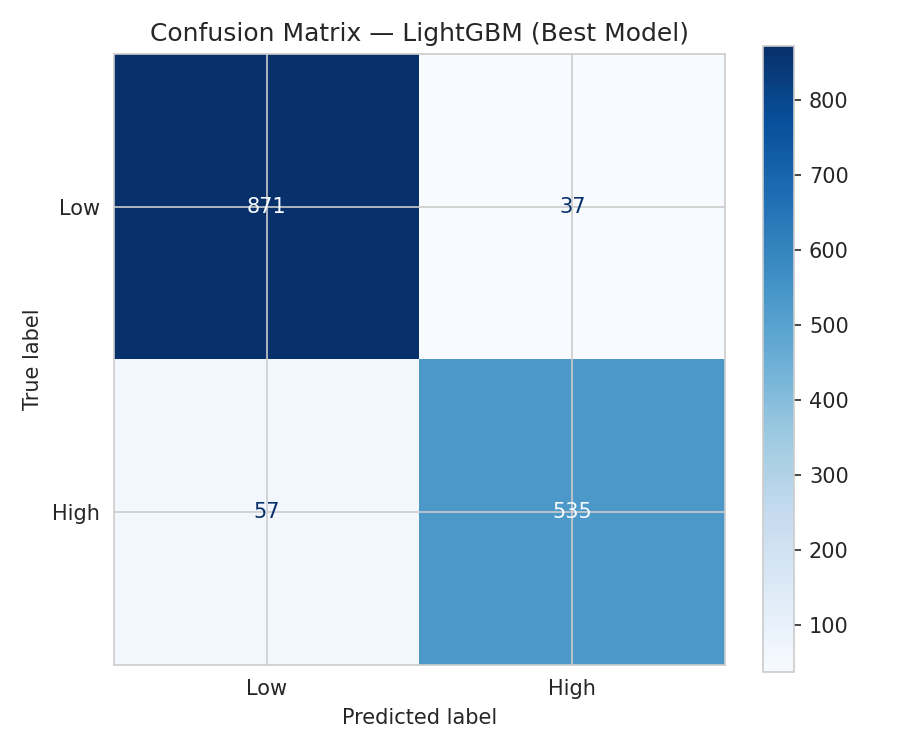


2. Learning Curve - LightGBM
[GENERATED] learning_curve_best_model.png


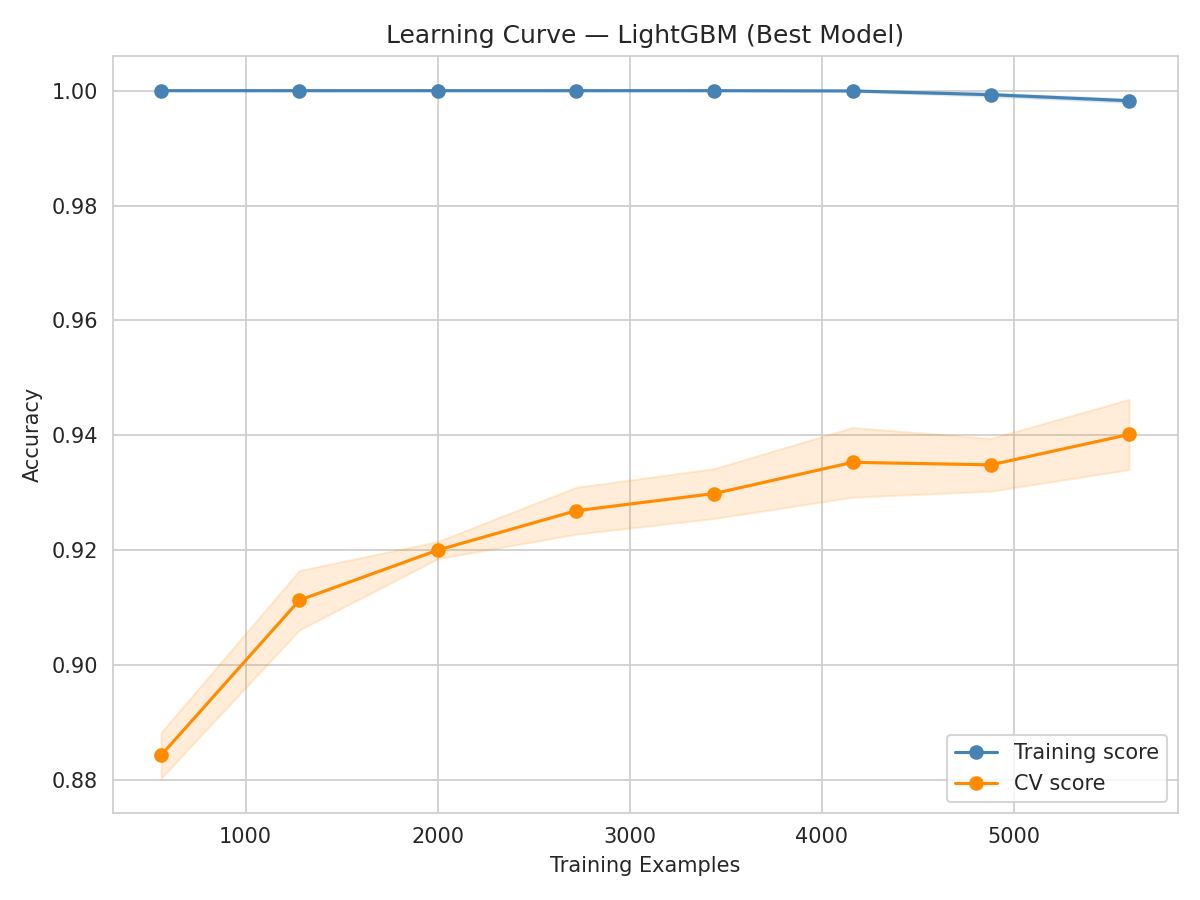


3. LightGBM Feature Importance
[GENERATED] feature_importance_best_model.csv


,Unnamed: 0,0
0,Start_Lng,1019
1,Start_Lat,1003
2,enc_Street_freq,757
3,Description_Length,681
4,enc_Zipcode_freq,612
5,Pressure(in),460
6,Duration_Minutes,423
7,Temperature(F),399
8,enc_Airport_Code_freq,382
9,enc_City_freq,354



4. Top Feature Importance - LightGBM
[GENERATED] feature_importance_best_model.png


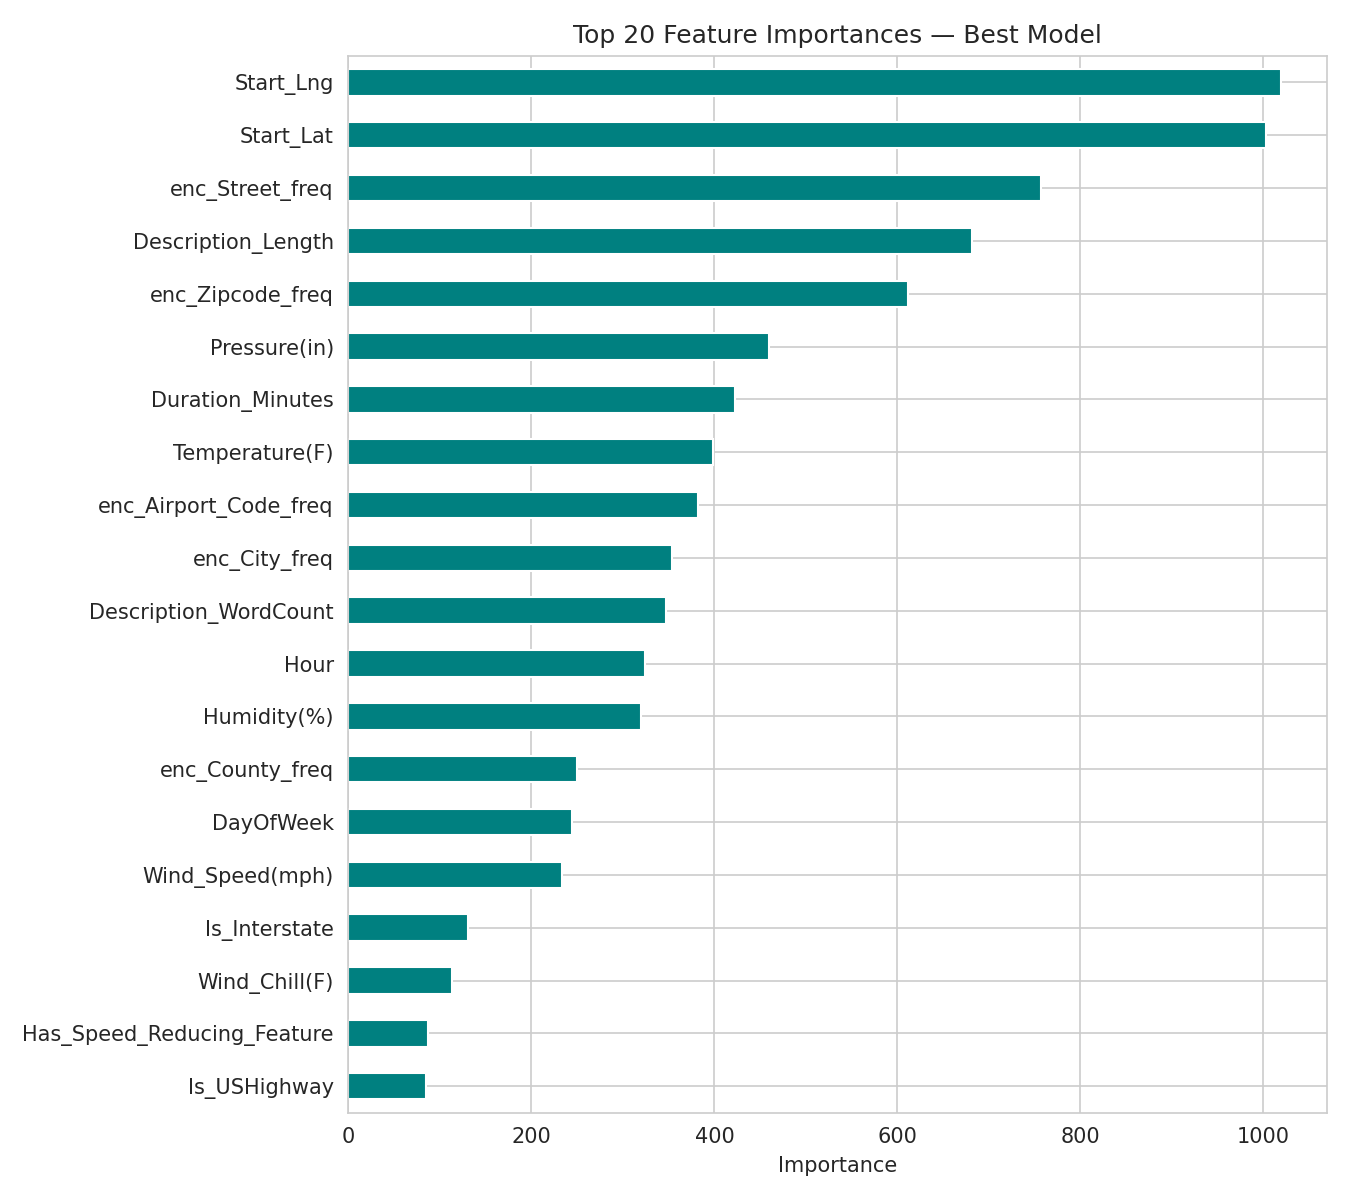


5. ROC Curve - LightGBM
[GENERATED] roc_curves_lightgbm.png


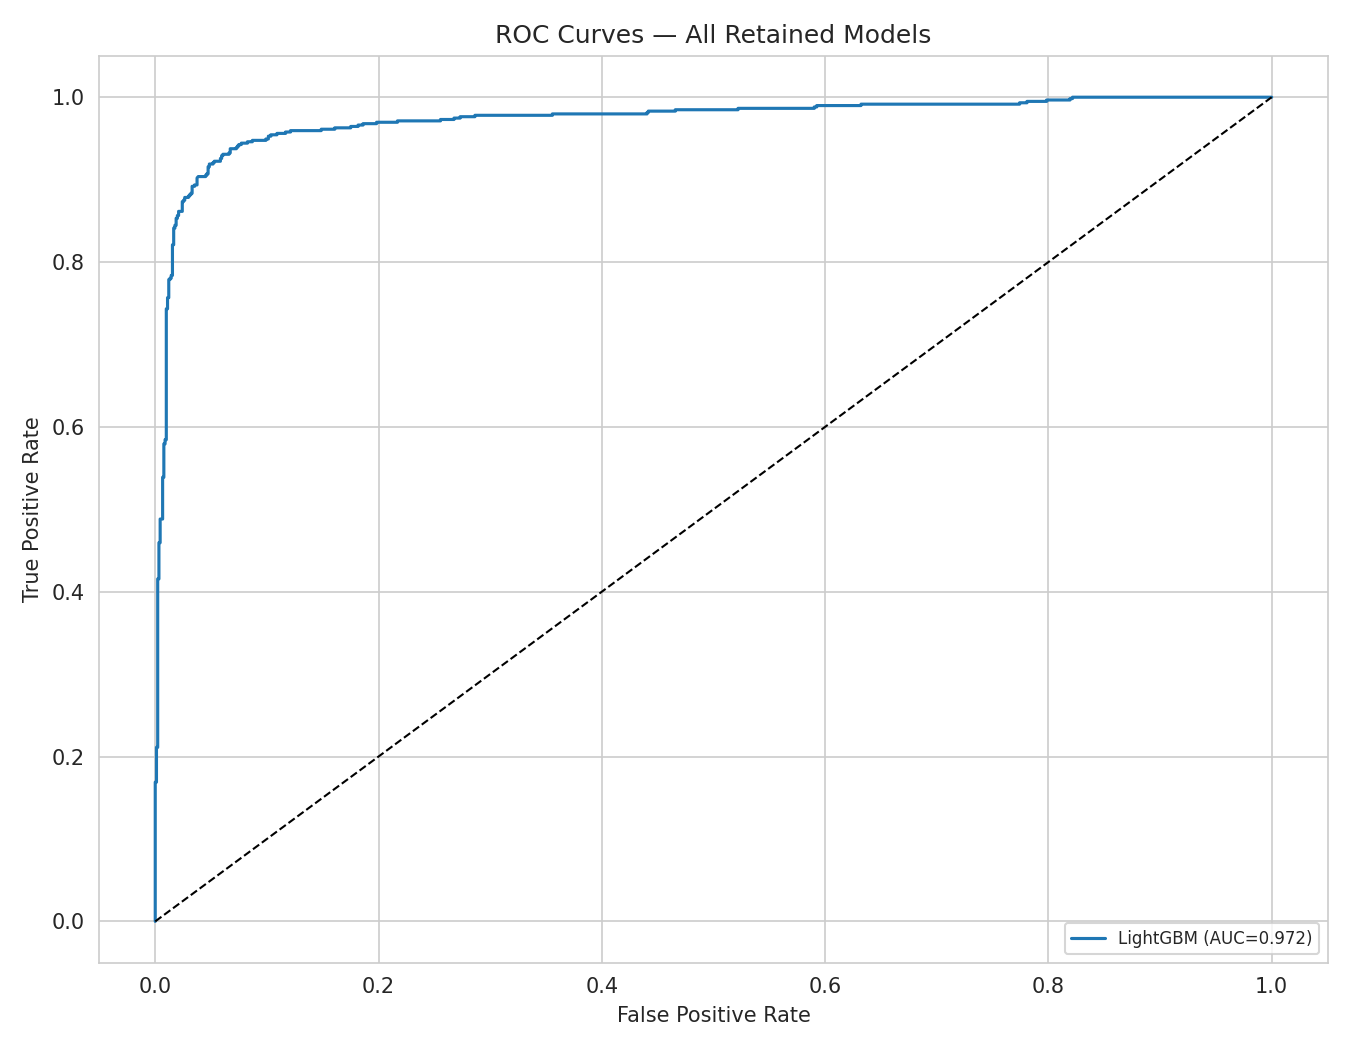


6. Precision-Recall Curve - LightGBM
[GENERATED] pr_curves_lightgbm.png


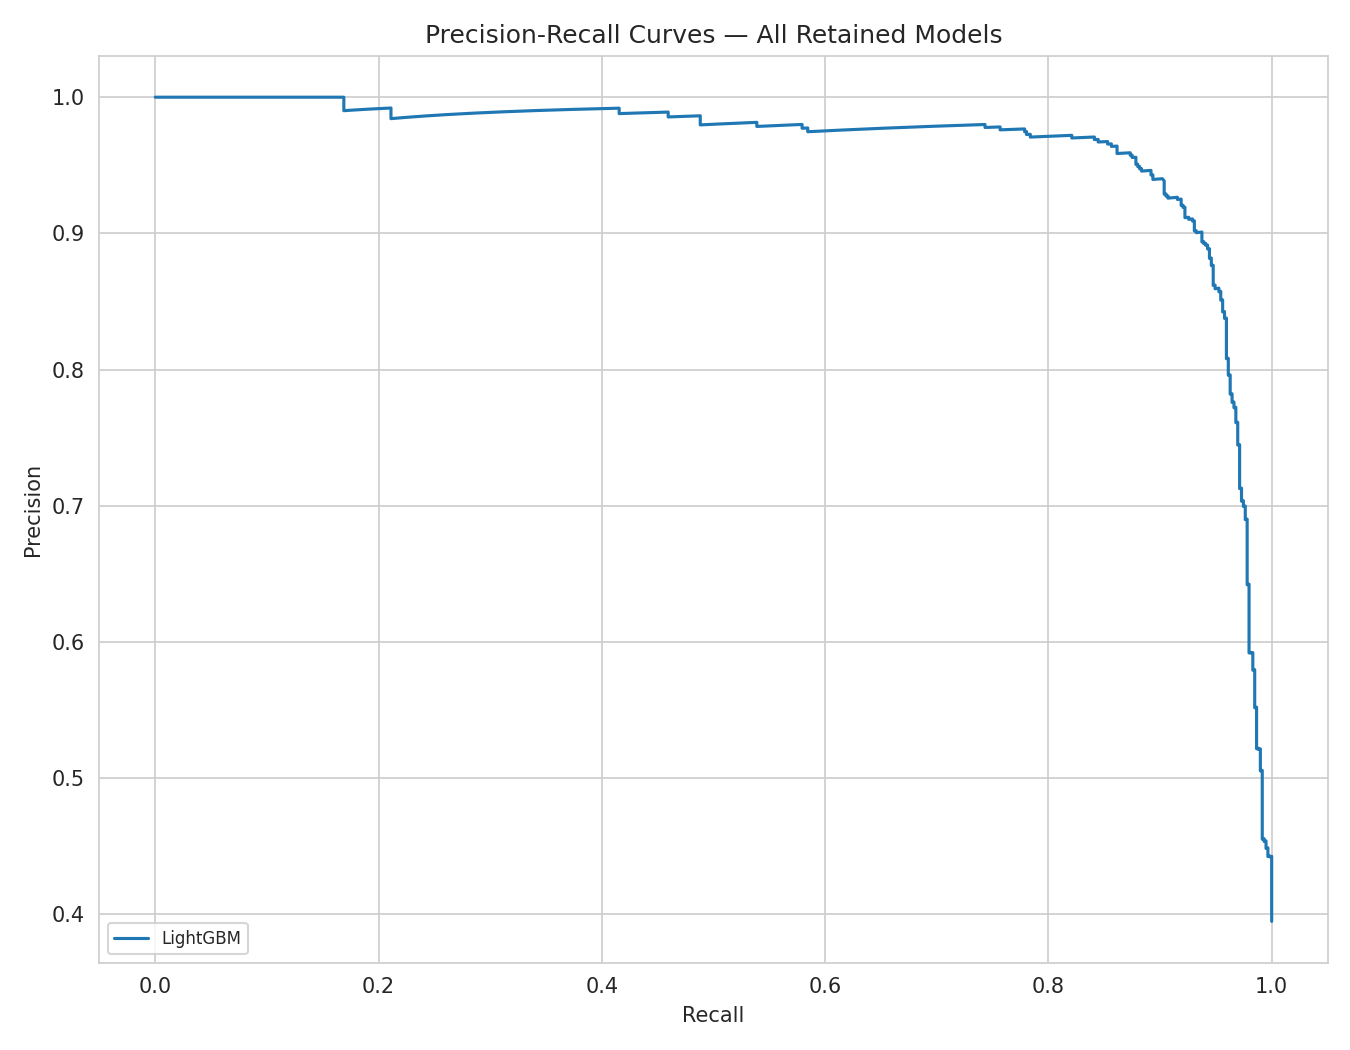


7. SHAP Summary Plot - LightGBM
[GENERATED] shap_summary_plot.png


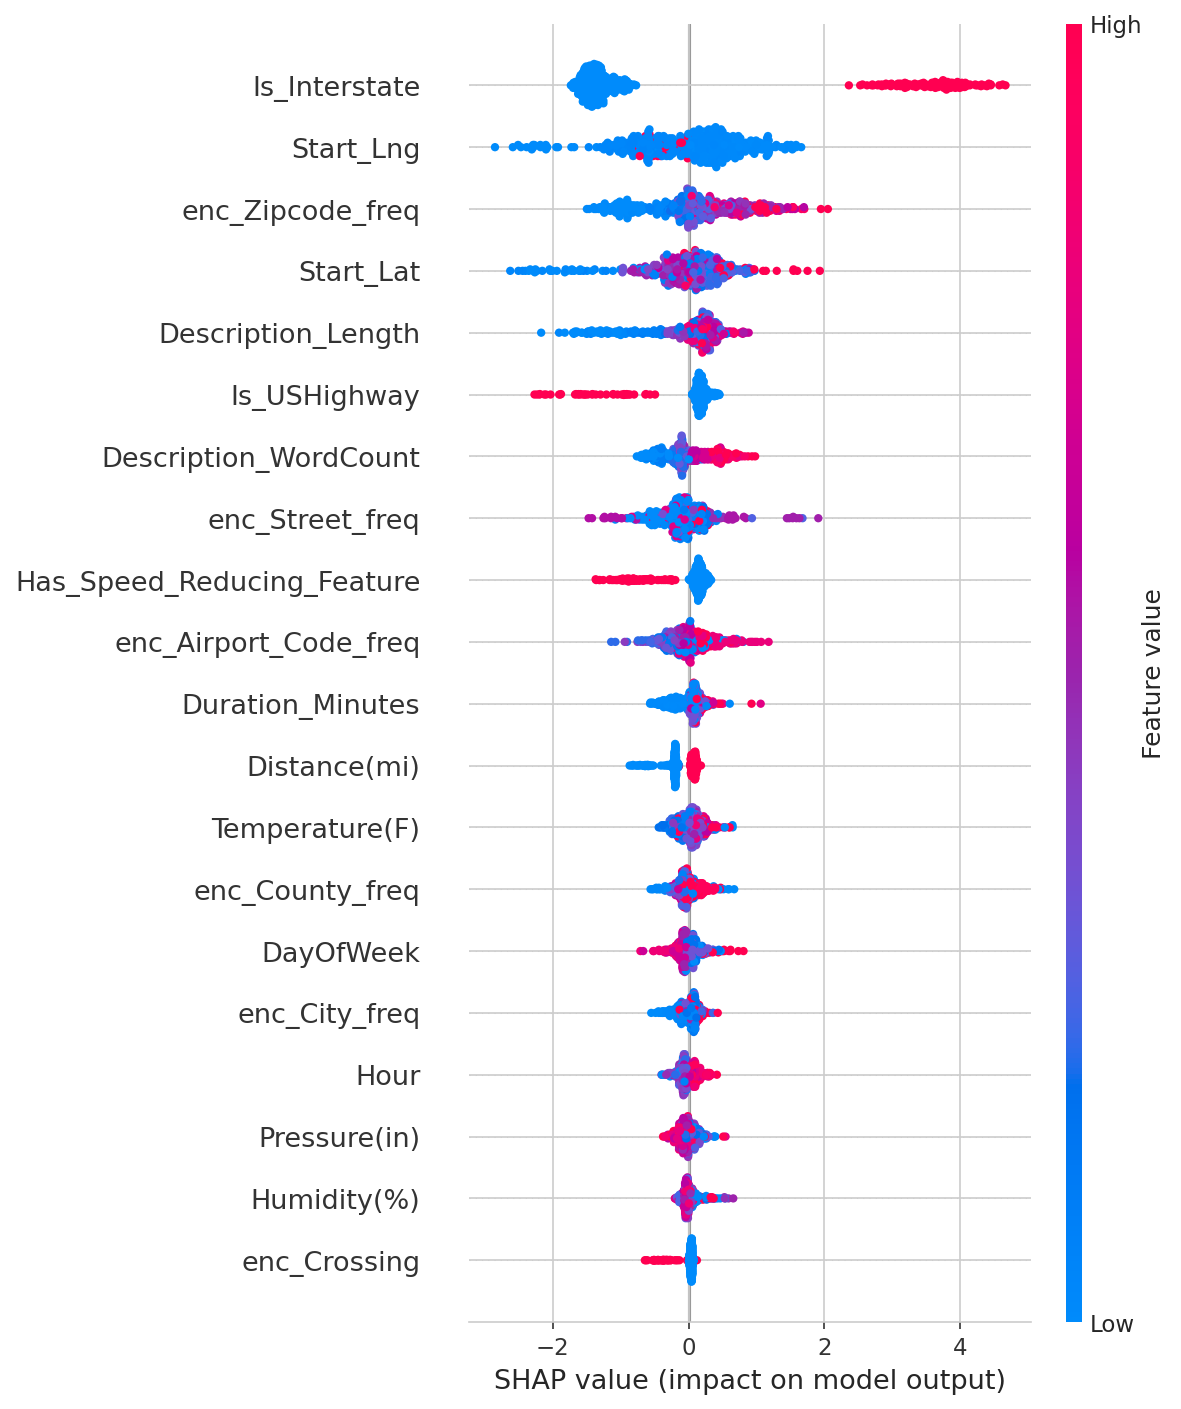


8. SHAP Feature Importance - LightGBM
[GENERATED] shap_bar_plot.png


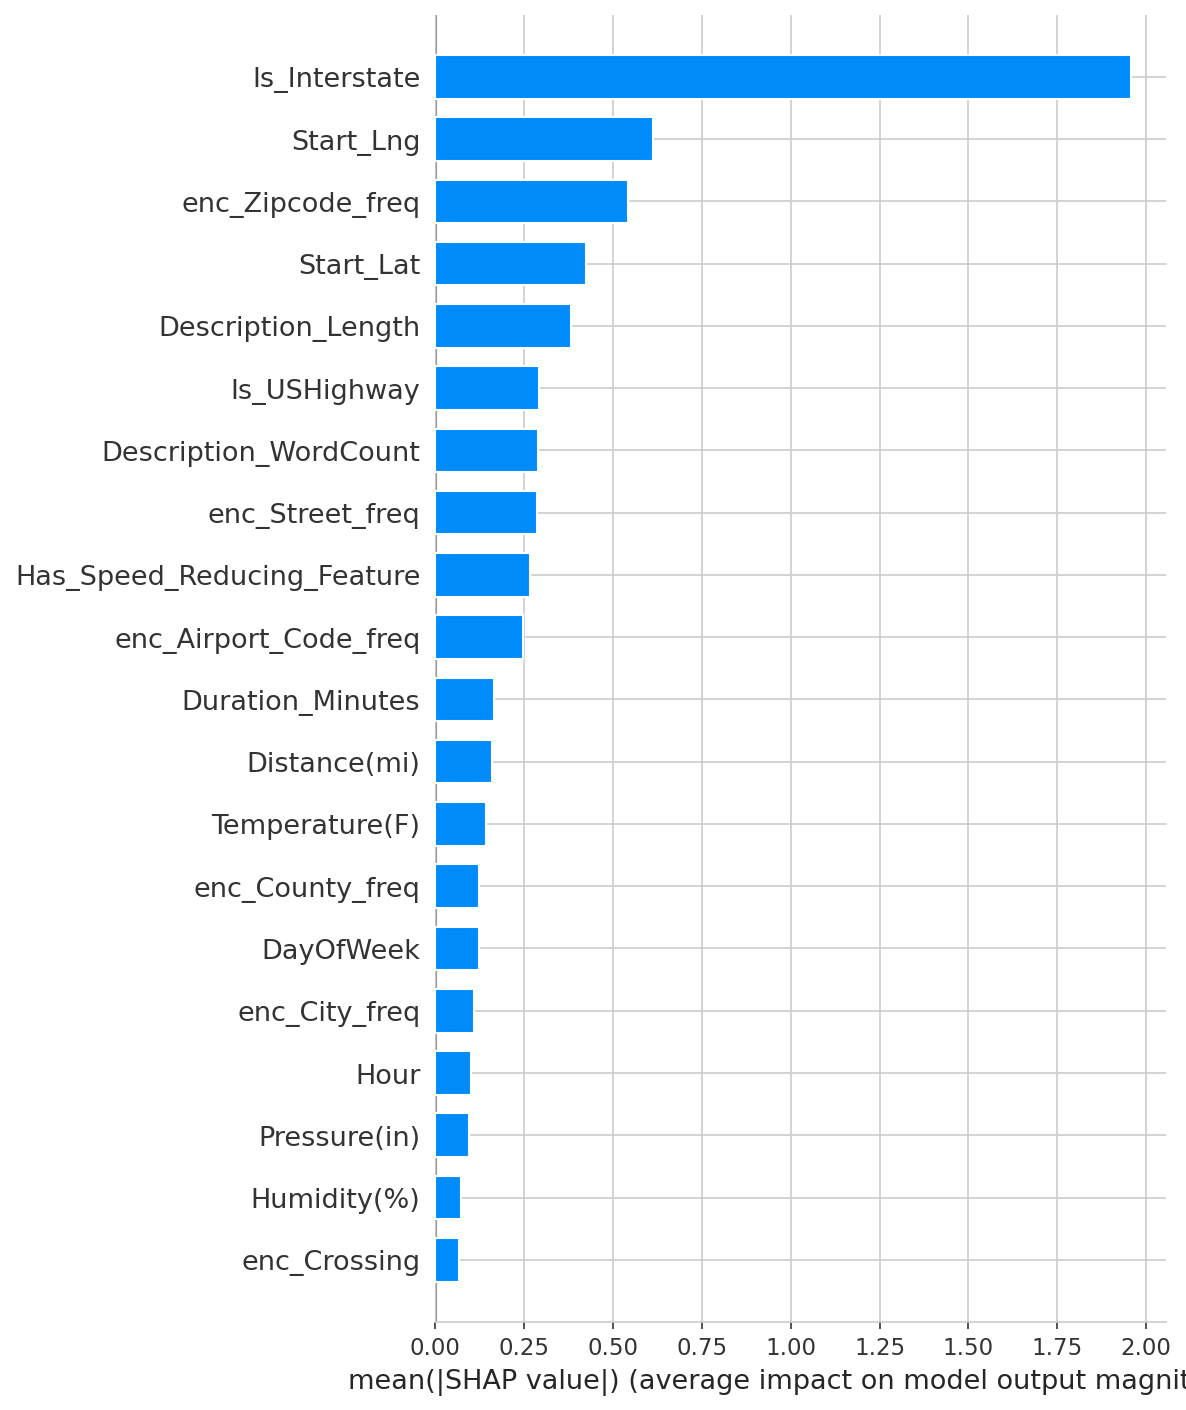


FIGURE LOADING COMPLETE
Final Model Used for Figures: LightGBM

Note:
If any figure shows [NOT GENERATED], run the figure generation/main() cell first.


In [685]:
import os
import pandas as pd
from IPython.display import display, Image

# Output folders
R = "outputs/Figures"
T = "outputs/Tables"


# ============================================================
# SAFE IMAGE DISPLAY FUNCTION
# ============================================================
def show_image(path, title, size=None):
    print("\n" + "=" * 60)
    print(title)
    print("=" * 60)

    if os.path.exists(path):
        print(f"[GENERATED] {os.path.basename(path)}")

        # Display image
        if size is not None:
            display(Image(filename=path, width=size[0] * 100))
        else:
            display(Image(filename=path))

    else:
        print(f"[NOT GENERATED] {os.path.basename(path)}")
        print("This figure file was not found. Run the figure generation cell first.")


# ============================================================
# FINAL MODEL
# ============================================================
BEST_MODEL = "LightGBM"

print("=" * 60)
print(f"FINAL MODEL FOR FIGURES: {BEST_MODEL}")
print("=" * 60)


# ============================================================
# 1. CONFUSION MATRIX - LIGHTGBM
# ============================================================
show_image(
    f"{R}/confusion_matrix_best_model.png",
    "1. Confusion Matrix - LightGBM",
    (6, 5)
)


# ============================================================
# 2. LEARNING CURVE - LIGHTGBM
# ============================================================
show_image(
    f"{R}/learning_curve_best_model.png",
    "2. Learning Curve - LightGBM",
    (8, 6)
)


# ============================================================
# 3. FEATURE IMPORTANCE TABLE
# ============================================================
print("\n" + "=" * 60)
print("3. LightGBM Feature Importance")
print("=" * 60)

fi_path = f"{T}/feature_importance_best_model.csv"

if os.path.exists(fi_path):
    try:
        fi = pd.read_csv(fi_path)

        print("[GENERATED] feature_importance_best_model.csv")
        display(fi.head(20))

    except Exception as e:
        print(f"[WARNING] Could not read feature importance CSV: {e}")

else:
    print("[NOT GENERATED] feature_importance_best_model.csv")


# ============================================================
# 4. FEATURE IMPORTANCE FIGURE
# ============================================================
show_image(
    f"{R}/feature_importance_best_model.png",
    "4. Top Feature Importance - LightGBM",
    (9, 8)
)


# ============================================================
# 5. ROC CURVE - LIGHTGBM
# ============================================================
show_image(
    f"{R}/roc_curves_lightgbm.png",
    "5. ROC Curve - LightGBM",
    (8, 6)
)


# ============================================================
# 6. PRECISION-RECALL CURVE - LIGHTGBM
# ============================================================
show_image(
    f"{R}/pr_curves_lightgbm.png",
    "6. Precision-Recall Curve - LightGBM",
    (8, 6)
)


# ============================================================
# 7. SHAP SUMMARY PLOT
# ============================================================
show_image(
    f"{R}/shap_summary_plot.png",
    "7. SHAP Summary Plot - LightGBM",
    (10, 8)
)


# ============================================================
# 8. SHAP FEATURE IMPORTANCE
# ============================================================
show_image(
    f"{R}/shap_bar_plot.png",
    "8. SHAP Feature Importance - LightGBM",
    (9, 8)
)


# ============================================================
# FINAL STATUS
# ============================================================
print("\n" + "=" * 60)
print("FIGURE LOADING COMPLETE")
print(f"Final Model Used for Figures: {BEST_MODEL}")
print("=" * 60)

print("\nNote:")
print("If any figure shows [NOT GENERATED], run the figure generation/main() cell first.")

# Safe Actual vs Model Prediction

**Important:** This section does not retrain the model and does not change the existing reference results. It only loads an already-saved LightGBM model and produces predictions for comparison with the actual values.


In [686]:
import os
import hashlib
import joblib
import numpy as np
import pandas as pd

os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(TABLES_DIR, exist_ok=True)

# Use the already-prepared processed dataset for the prediction demonstration.
PREDICTION_DATA_PATH = PROCESSED_DATA_PATH
if not os.path.isfile(PREDICTION_DATA_PATH):
    raise FileNotFoundError(
        f"Prediction dataset not found: {PREDICTION_DATA_PATH}. "
        "Upload processed_full_dataset.csv to the notebook working directory."
    )

# [CORRECTION cell 35] The recovered files were uploaded as a flat folder, not inside
# outputs/Models/, which caused the original FileNotFoundError. Look in the standard
# locations (read-only; the files are never written, moved or re-saved).
def _find_existing(filename):
    for folder in [MODELS_DIR, ".", "/content"]:
        candidate = os.path.join(folder, filename)
        if os.path.isfile(candidate):
            return candidate
    return None

ORIGINAL_MODEL_PATH = _find_existing("LightGBM.pkl") or os.path.join(MODELS_DIR, "LightGBM.pkl")
SCALER_PATH = _find_existing("standard_scaler.pkl") or os.path.join(MODELS_DIR, "standard_scaler.pkl")

# [CORRECTION cell 35] The "prediction-only / unscaled" replacement model is no longer
# preferred. The recovered LightGBM.pkl was fitted on standardised features, so it must be
# used together with standard_scaler.pkl. This name is kept only so later cells still run.
PREDICTION_MODEL_PATH = ORIGINAL_MODEL_PATH

if not os.path.isfile(ORIGINAL_MODEL_PATH):
    raise FileNotFoundError(
        "LightGBM.pkl was not found in outputs/Models/, the working folder or /content. "
        "This notebook will not silently retrain or create a replacement model."
    )
if not os.path.isfile(SCALER_PATH):
    raise FileNotFoundError(
        "standard_scaler.pkl was not found in outputs/Models/, the working folder or /content. "
        "The original model's preprocessing cannot be reproduced safely."
    )

prediction_model = joblib.load(ORIGINAL_MODEL_PATH)
prediction_scaler = joblib.load(SCALER_PATH)
print("[OK] Original LightGBM model and matching scaler loaded (read-only).")
print("     model :", ORIGINAL_MODEL_PATH)
print("     scaler:", SCALER_PATH)

# Integrity information only (does not block anything): fingerprints of the recovered files.
def _sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

RECOVERED_SHA256 = {
    "LightGBM.pkl": "f1e618c45b589989a3c1d5bdebdae9f46e830bffe7d86d0df1cc7a2b87485fa3",
    "standard_scaler.pkl": "d3d0c0da8e647d85788f98a2214c9d50cab792a89efda47a9dac7a9546d61f22",
}
for _label, _path in [("LightGBM.pkl", ORIGINAL_MODEL_PATH), ("standard_scaler.pkl", SCALER_PATH)]:
    _h = _sha256(_path)
    print(f"[HASH] {_label}: {_h[:16]}...  ->",
          "matches the recovered file" if _h == RECOVERED_SHA256[_label]
          else "DIFFERENT from the recovered file that was inspected")

print("[OK] Prediction dataset:", PREDICTION_DATA_PATH)


[OK] Original LightGBM model and matching scaler loaded (read-only).
     model : outputs/Models/LightGBM.pkl
     scaler: outputs/Models/standard_scaler.pkl
[HASH] LightGBM.pkl: 7db25ac33c0a0471...  -> DIFFERENT from the recovered file that was inspected
[HASH] standard_scaler.pkl: 6fc4087e1716849d...  -> DIFFERENT from the recovered file that was inspected
[OK] Prediction dataset: processed_full_dataset.csv


In [687]:
def prepare_prediction_features(dataframe, model, scaler=None, reference_medians=None):
    """Prepare prediction input exactly as the saved model was trained, without guessing.

    [CORRECTION cell 36]
    * LightGBM stored 14 weather feature names with underscores (e.g. 'Heavy_Rain') while
      the scaler and dataset keep the original names with spaces ('Heavy Rain'). The two
      lists are the same 109 features in the same order, so columns are matched by the
      scaler's original names and the match is verified position by position.
    * No feature is ever zero-filled or invented: any missing or non-numeric required
      column raises an error that lists it.
    * NaNs are filled only with the training-time medians passed in `reference_medians`
      (never with medians of the file being predicted). A NaN with no reference median
      raises an error.
    * The scaler is mandatory: the model was fitted on standardised features.
    """
    if not isinstance(dataframe, pd.DataFrame):
        raise TypeError("Prediction input must be a pandas DataFrame.")
    if scaler is None:
        raise ValueError(
            "standard_scaler.pkl is required: the saved LightGBM model was fitted on "
            "standardised features and cannot be used on unscaled data."
        )
    if not hasattr(scaler, "feature_names_in_"):
        raise ValueError("The scaler does not expose its training feature names.")

    scaler_names = list(scaler.feature_names_in_)
    if hasattr(model, "feature_name_") and model.feature_name_:
        model_names = list(model.feature_name_)
    elif hasattr(model, "feature_names_in_"):
        model_names = list(model.feature_names_in_)
    else:
        raise ValueError(
            "The saved model does not expose its training feature names. "
            "Cannot guarantee correct feature alignment."
        )

    # Verify scaler order == model order. The only tolerated difference is LightGBM's
    # space -> underscore renaming of the same feature at the same position.
    if len(scaler_names) != len(model_names):
        raise ValueError(f"Scaler has {len(scaler_names)} features but model has {len(model_names)}.")
    mismatched = [
        (i, s, m) for i, (s, m) in enumerate(zip(scaler_names, model_names))
        if s != m and s.replace(" ", "_") != m
    ]
    if mismatched:
        raise ValueError(
            "Scaler and model feature lists do not correspond position by position: "
            + "; ".join(f"#{i}: scaler='{s}' model='{m}'" for i, s, m in mismatched[:10])
        )

    data = dataframe.copy()
    # Target columns must never be used as prediction features (they are not model features,
    # and selecting by name below already excludes them).
    data = data.drop(
        columns=[c for c in [TARGET_COL_ORIGINAL, TARGET_COL_BINARY, "Prediction"] if c in data.columns],
        errors="ignore",
    )

    missing = [c for c in scaler_names if c not in data.columns]
    if missing:
        raise ValueError(
            f"Prediction data is missing {len(missing)} required model features. "
            "They are NOT guessed or zero-filled: " + ", ".join(missing[:30])
        )

    X_new = data[scaler_names].copy()
    non_numeric = [c for c in scaler_names
                   if not (pd.api.types.is_numeric_dtype(X_new[c]) or pd.api.types.is_bool_dtype(X_new[c]))]
    if non_numeric:
        raise ValueError("Required features are not numeric: " + ", ".join(non_numeric[:30]))
    X_new = X_new.astype(float).replace([np.inf, -np.inf], np.nan)

    nan_cols = [c for c in scaler_names if X_new[c].isna().any()]
    if nan_cols:
        if reference_medians is None:
            raise ValueError(
                "NaN values found in " + ", ".join(nan_cols) +
                " but no training-time reference_medians were supplied."
            )
        no_ref = [c for c in nan_cols if c not in reference_medians.index or pd.isna(reference_medians[c])]
        if no_ref:
            raise ValueError("No training-time median available for: " + ", ".join(no_ref))
        for c in nan_cols:
            n = int(X_new[c].isna().sum())
            X_new[c] = X_new[c].fillna(float(reference_medians[c]))
            print(f"[INFO] {c}: {n} NaN value(s) filled with the training-time median "
                  f"({float(reference_medians[c])}).")

    # Standardise with the saved scaler (its own original column names), then hand the model
    # its own stored names; positions were verified identical above.
    transformed = scaler.transform(X_new)
    X_out = pd.DataFrame(transformed, columns=model_names, index=X_new.index)

    print(f"[OK] Features aligned and scaled: {X_out.shape[1]} columns, order verified against scaler and model")
    return X_out


In [688]:
# Load the dataset and generate predictions.
prediction_df = pd.read_csv(PREDICTION_DATA_PATH)

print("[OK] Prediction data loaded.")
print("Data shape:", prediction_df.shape)

# [CORRECTION cell 37] Reproduce the original (cell 3 / cell 4) split so results can be
# reported per split. This only labels rows; nothing is retrained.
for _needed in ["build_feature_matrix", "split_data"]:
    if _needed not in globals():
        raise NameError(f"'{_needed}' is not defined. Run the original cells 2, 3 and 4 first (definitions only).")

_X_ref, _y_ref = build_feature_matrix(prediction_df)
assert list(_X_ref.columns) == list(prediction_scaler.feature_names_in_), \
    "Cell-3 feature matrix does not match the scaler's feature names/order."
_Xtr, _Xva, _Xte, _, _, _ = split_data(_X_ref, _y_ref)
SPLIT_LABELS = pd.Series("", index=prediction_df.index, dtype=object)
SPLIT_LABELS.loc[_Xtr.index] = "train"
SPLIT_LABELS.loc[_Xva.index] = "validation"
SPLIT_LABELS.loc[_Xte.index] = "test"
prediction_df["Split"] = SPLIT_LABELS

# Training-time imputation medians: cell 3 filled NaNs with the median of the processed dataset.
TRAINING_MEDIANS = (
    prediction_df[list(prediction_scaler.feature_names_in_)]
    .astype(float).replace([np.inf, -np.inf], np.nan).median()
)

X_prediction = prepare_prediction_features(
    prediction_df,
    prediction_model,
    prediction_scaler,
    reference_medians=TRAINING_MEDIANS,
)

model_prediction = prediction_model.predict(X_prediction)
prediction_df["Prediction"] = model_prediction

print("[OK] Prediction completed.")
display(prediction_df.head())


[OK] Prediction data loaded.
Data shape: (10000, 149)
[FEATURES] X shape: (10000, 114)
[SPLIT] Train=7000  Val=1500  Test=1500
[INFO] Wind_Chill(F): 85 NaN value(s) filled with the training-time median (57.0).
[OK] Features aligned and scaled: 114 columns, order verified against scaler and model
[OK] Prediction completed.


,ID,Source,Severity,Start_Time,End_Time,Start_Lat,Start_Lng,End_Lat,End_Lng,Distance(mi),Description,Street,City,County,State,...,enc_Traffic_Calming,enc_Traffic_Signal,enc_Turning_Loop,Distance(mi)_log,Precipitation(in)_log,Description_Length_log,Description_WordCount_log,Duration_Minutes_log,enc_Source_Source2,enc_Timezone_US/Eastern,enc_State_CA,enc_Wind_Direction_Calm,enc_Weather_Condition_Clear,Split,Prediction
0,A-1,Source2,3,2016-02-08 05:46:00,2016-02-08 11:00:00,39.865147,-84.058723,39.865147,-84.058723,0.01,Right lane blocked due to accident on I-70 Eas...,I-70 E,Dayton,Montgomery,OH,...,0,0,0,0.00995,0.0,4.454347,2.833213,5.752573,1,1,0,1,0,train,1
1,A-2,Source2,2,2016-02-08 06:07:59,2016-02-08 06:37:59,39.928059,-82.831184,39.928059,-82.831184,0.01,Accident on Brice Rd at Tussing Rd. Expect del...,Brice Rd,Reynoldsburg,Franklin,OH,...,0,0,0,0.00995,0.0,3.931826,2.302585,3.433987,1,1,0,1,0,validation,0
2,A-3,Source2,2,2016-02-08 06:49:27,2016-02-08 07:19:27,39.063148,-84.032608,39.063148,-84.032608,0.01,Accident on OH-32 State Route 32 Westbound at ...,State Route 32,Williamsburg,Clermont,OH,...,0,1,0,0.00995,0.0,4.330733,2.639057,3.433987,1,1,0,0,0,train,0
3,A-4,Source2,3,2016-02-08 07:23:34,2016-02-08 07:53:34,39.747753,-84.205582,39.747753,-84.205582,0.01,Accident on I-75 Southbound at Exits 52 52B US...,I-75 S,Dayton,Montgomery,OH,...,0,0,0,0.00995,0.0,4.189655,2.484907,3.433987,1,1,0,0,0,train,1
4,A-5,Source2,2,2016-02-08 07:39:07,2016-02-08 08:09:07,39.627781,-84.188354,39.627781,-84.188354,0.01,Accident on McEwen Rd at OH-725 Miamisburg Cen...,Miamisburg Centerville Rd,Dayton,Montgomery,OH,...,0,1,0,0.00995,0.0,4.304065,2.484907,3.433987,1,1,0,0,0,train,0


In [689]:
# Duplicate model-loading step intentionally removed.
# The model and its matching preprocessing object are loaded in Cell 35.
print("[INFO] Model loading is handled once in Cell 35.")


[INFO] Model loading is handled once in Cell 35.


In [690]:
# Do not reload LightGBM.pkl here: doing so could replace the correctly matched
# prediction-only model and create a model/scaler mismatch.
print("[INFO] The selected prediction model remains unchanged.")


[INFO] The selected prediction model remains unchanged.


In [691]:
# Duplicate prediction step intentionally removed.
# Predictions have already been generated in Cell 37.
print("[INFO] Prediction results are available in prediction_df.")
display(prediction_df.head())


[INFO] Prediction results are available in prediction_df.


,ID,Source,Severity,Start_Time,End_Time,Start_Lat,Start_Lng,End_Lat,End_Lng,Distance(mi),Description,Street,City,County,State,...,enc_Traffic_Calming,enc_Traffic_Signal,enc_Turning_Loop,Distance(mi)_log,Precipitation(in)_log,Description_Length_log,Description_WordCount_log,Duration_Minutes_log,enc_Source_Source2,enc_Timezone_US/Eastern,enc_State_CA,enc_Wind_Direction_Calm,enc_Weather_Condition_Clear,Split,Prediction
0,A-1,Source2,3,2016-02-08 05:46:00,2016-02-08 11:00:00,39.865147,-84.058723,39.865147,-84.058723,0.01,Right lane blocked due to accident on I-70 Eas...,I-70 E,Dayton,Montgomery,OH,...,0,0,0,0.00995,0.0,4.454347,2.833213,5.752573,1,1,0,1,0,train,1
1,A-2,Source2,2,2016-02-08 06:07:59,2016-02-08 06:37:59,39.928059,-82.831184,39.928059,-82.831184,0.01,Accident on Brice Rd at Tussing Rd. Expect del...,Brice Rd,Reynoldsburg,Franklin,OH,...,0,0,0,0.00995,0.0,3.931826,2.302585,3.433987,1,1,0,1,0,validation,0
2,A-3,Source2,2,2016-02-08 06:49:27,2016-02-08 07:19:27,39.063148,-84.032608,39.063148,-84.032608,0.01,Accident on OH-32 State Route 32 Westbound at ...,State Route 32,Williamsburg,Clermont,OH,...,0,1,0,0.00995,0.0,4.330733,2.639057,3.433987,1,1,0,0,0,train,0
3,A-4,Source2,3,2016-02-08 07:23:34,2016-02-08 07:53:34,39.747753,-84.205582,39.747753,-84.205582,0.01,Accident on I-75 Southbound at Exits 52 52B US...,I-75 S,Dayton,Montgomery,OH,...,0,0,0,0.00995,0.0,4.189655,2.484907,3.433987,1,1,0,0,0,train,1
4,A-5,Source2,2,2016-02-08 07:39:07,2016-02-08 08:09:07,39.627781,-84.188354,39.627781,-84.188354,0.01,Accident on McEwen Rd at OH-725 Miamisburg Cen...,Miamisburg Centerville Rd,Dayton,Montgomery,OH,...,0,1,0,0.00995,0.0,4.304065,2.484907,3.433987,1,1,0,0,0,train,0


In [692]:
# Keep the selected model path visible for reference.
print("[INFO] Selected prediction model:", PREDICTION_MODEL_PATH
      if os.path.isfile(PREDICTION_MODEL_PATH) else ORIGINAL_MODEL_PATH)


[INFO] Selected prediction model: outputs/Models/LightGBM.pkl


In [693]:
# Do not reload another model here; retain the model selected in Cell 35.
print("[INFO] No additional model reload is required.")


[INFO] No additional model reload is required.


In [694]:
# Compare predictions with actual labels only if the target column is present.
actual_values = (
    prediction_df[TARGET_COL_BINARY].copy()
    if TARGET_COL_BINARY in prediction_df.columns
    else pd.Series(pd.NA, index=prediction_df.index, dtype="Int64")
)

actual_vs_prediction = pd.DataFrame({
    "Actual": actual_values,
    "Model_Prediction": model_prediction
}, index=prediction_df.index)
# [CORRECTION cell 43] record which split each row belongs to
if "Split" in prediction_df.columns:
    actual_vs_prediction["Split"] = prediction_df["Split"]

actual_numeric = pd.to_numeric(actual_vs_prediction["Actual"], errors="coerce")
actual_vs_prediction["Match"] = pd.Series(pd.NA, index=prediction_df.index, dtype="boolean")
valid_actual = actual_numeric.notna()
actual_vs_prediction.loc[valid_actual, "Match"] = (
    actual_numeric.loc[valid_actual].astype(int).to_numpy()
    == np.asarray(model_prediction)[valid_actual.to_numpy()]
)

display(actual_vs_prediction.head(20))

if valid_actual.any():
    accuracy = (
        actual_numeric.loc[valid_actual].astype(int).to_numpy()
        == np.asarray(model_prediction)[valid_actual.to_numpy()]
    ).mean() * 100
    # [CORRECTION cell 43] this figure includes the 7,000 training rows, so it is NOT the
    # thesis test accuracy. The per-split figures below are the comparable ones.
    print(f"Whole-file accuracy (train+validation+test rows, NOT the thesis test accuracy): {accuracy:.2f}%")

    if "Split" in actual_vs_prediction.columns:
        print("\nAccuracy by split:")
        for _split in ["train", "validation", "test"]:
            _m = valid_actual & (actual_vs_prediction["Split"] == _split)
            if _m.any():
                _acc = (actual_numeric.loc[_m].astype(int).to_numpy()
                        == np.asarray(model_prediction)[_m.to_numpy()]).mean() * 100
                print(f"  {_split:<11} n={int(_m.sum()):>5}  accuracy = {_acc:6.2f}%")

        _ref_path = os.path.join("reference_outputs", "all_models_results.csv")
        if os.path.isfile(_ref_path):
            _ref = pd.read_csv(_ref_path)
            _ref = _ref[_ref["Model"] == "LightGBM"]
            if len(_ref):
                print(f"\nOriginal thesis reference (unchanged): LightGBM test accuracy = "
                      f"{float(_ref['Test_Accuracy'].iloc[0]):.2f}%, "
                      f"train accuracy = {float(_ref['Train_Accuracy'].iloc[0]):.2f}%")
                print("The line above is the thesis result; it is read from the reference file and never recomputed or edited here.")
                print("The 'test' line in the split table is measured from the recovered LightGBM.pkl.")
else:
    print("[INFO] No actual target labels were supplied; predictions only.")


,Actual,Model_Prediction,Split,Match
0,1,1,train,True
1,0,0,validation,True
2,0,0,train,True
3,1,1,train,True
4,0,0,train,True
5,1,0,train,False
6,0,0,train,True
7,1,0,train,False
8,0,0,test,True
9,1,0,train,False


Whole-file accuracy (train+validation+test rows, NOT the thesis test accuracy): 82.64%

Accuracy by split:
  train       n= 7000  accuracy =  82.77%
  validation  n= 1500  accuracy =  82.00%
  test        n= 1500  accuracy =  82.67%

Original thesis reference (unchanged): LightGBM test accuracy = 94.00%, train accuracy = 98.14%
The line above is the thesis result; it is read from the reference file and never recomputed or edited here.
The 'test' line in the split table is measured from the recovered LightGBM.pkl.


In [695]:
# Save only a new prediction output; never overwrite reference result files.
os.makedirs(TABLES_DIR, exist_ok=True)
PREDICTION_OUTPUT_PATH = os.path.join(
    TABLES_DIR, "actual_vs_model_prediction.csv"
)
actual_vs_prediction.to_csv(PREDICTION_OUTPUT_PATH, index=False)

print("[SAVED]", PREDICTION_OUTPUT_PATH)
print("[PROTECTED] Original thesis reference CSVs, figures and model files were not overwritten.")


[SAVED] outputs/Tables/actual_vs_model_prediction.csv
[PROTECTED] Original thesis reference CSVs, figures and model files were not overwritten.


In [696]:
import numpy as np, pandas as pd, joblib

model  = joblib.load("LightGBM.pkl")
scaler = joblib.load("standard_scaler.pkl")
names  = list(scaler.feature_names_in_)          # the 109 features, in the right order

d = [
    {"Start_Lat": 37.701683, "Start_Lng": -121.882751, "End_Lat": 37.701683, "End_Lng": -121.882751, "Distance(mi)": 0.01, "Temperature(F)": 51.1, "Wind_Chill(F)": 51.1, "Humidity(%)": 54, "Pressure(in)": 29.99, "Visibility(mi)": 10, "Wind_Speed(mph)": 3.5, "Precipitation(in)": 0, "Duration_Minutes": 29.666667, "Hour": 17, "DayOfWeek": 3, "Month": 12, "Year": 2016, "Is_Weekend": 0, "Is_Night": 1, "Is_RushHour": 1, "Is_Interstate": 1, "Is_USHighway": 0, "Is_StateRoute": 0, "Is_HighSpeedRoad": 1, "Traffic_Control_Count": 0, "Has_Speed_Reducing_Feature": 0, "No_Traffic_Control": 1, "Low_Visibility": 0, "Speed_Violation_Risk_Score": 1, "High_Speed_Violation_Risk": 1, "Weather_Severity_Index": 0, "Lat_Diff": 0, "Lng_Diff": 0, "Description_Length": 104, "Description_WordCount": 19, "enc_Source_Source3": 0, "enc_Wind_Direction_E": 0, "enc_Wind_Direction_ENE": 0, "enc_Wind_Direction_ESE": 1, "enc_Wind_Direction_East": 0, "enc_Wind_Direction_NE": 0, "enc_Wind_Direction_NNE": 0, "enc_Wind_Direction_NNW": 0, "enc_Wind_Direction_NW": 0, "enc_Wind_Direction_North": 0, "enc_Wind_Direction_SE": 0, "enc_Wind_Direction_SSE": 0, "enc_Wind_Direction_SSW": 0, "enc_Wind_Direction_SW": 0, "enc_Wind_Direction_South": 0, "enc_Wind_Direction_Variable": 0, "enc_Wind_Direction_W": 0, "enc_Wind_Direction_WNW": 0, "enc_Wind_Direction_WSW": 0, "enc_Wind_Direction_West": 0, "enc_Weather_Condition_Cloudy": 0, "enc_Weather_Condition_Drizzle": 0, "enc_Weather_Condition_Fog": 0, "enc_Weather_Condition_Haze": 0, "enc_Weather_Condition_Heavy Rain": 0, "enc_Weather_Condition_Light Drizzle": 0, "enc_Weather_Condition_Light Freezing Drizzle": 0, "enc_Weather_Condition_Light Freezing Fog": 0, "enc_Weather_Condition_Light Freezing Rain": 0, "enc_Weather_Condition_Light Haze": 0, "enc_Weather_Condition_Light Rain": 0, "enc_Weather_Condition_Light Rain Showers": 0, "enc_Weather_Condition_Light Snow": 0, "enc_Weather_Condition_Mist": 0, "enc_Weather_Condition_Mostly Cloudy": 0, "enc_Weather_Condition_Overcast": 0, "enc_Weather_Condition_Partly Cloudy": 0, "enc_Weather_Condition_Patches of Fog": 0, "enc_Weather_Condition_Rain": 0, "enc_Weather_Condition_Scattered Clouds": 0, "enc_Weather_Condition_Shallow Fog": 0, "enc_Weather_Condition_Smoke": 0, "enc_Weather_Condition_Snow": 0, "enc_Sunrise_Sunset_Night": 1, "enc_Civil_Twilight_Night": 1, "enc_Nautical_Twilight_Night": 0, "enc_Astronomical_Twilight_Night": 0, "enc_Timezone_US/Pacific": 1, "enc_State_OH": 0, "enc_State_WV": 0, "enc_Street_freq": 0.0262, "enc_City_freq": 0.0048, "enc_County_freq": 0.1627, "enc_Zipcode_freq": 0.0036, "enc_Airport_Code_freq": 0.0529, "enc_Country_freq": 1, "enc_Amenity": 0, "enc_Bump": 0, "enc_Crossing": 0, "enc_Give_Way": 0, "enc_Junction": 0, "enc_No_Exit": 0, "enc_Railway": 0, "enc_Roundabout": 0, "enc_Station": 0, "enc_Stop": 0, "enc_Traffic_Calming": 0, "enc_Traffic_Signal": 0, "enc_Turning_Loop": 0, "Distance(mi)_log": 0.00995, "Precipitation(in)_log": 0, "Description_Length_log": 4.65396, "Description_WordCount_log": 2.995732, "Duration_Minutes_log": 3.423176},
    {"Start_Lat": 38.496071, "Start_Lng": -121.4291, "End_Lat": 38.496071, "End_Lng": -121.4291, "Distance(mi)": 0.01, "Temperature(F)": 48, "Wind_Chill(F)": 48, "Humidity(%)": 80, "Pressure(in)": 30.02, "Visibility(mi)": 10, "Wind_Speed(mph)": 10.4, "Precipitation(in)": 0, "Duration_Minutes": 29.583333, "Hour": 17, "DayOfWeek": 0, "Month": 1, "Year": 2017, "Is_Weekend": 0, "Is_Night": 1, "Is_RushHour": 1, "Is_Interstate": 0, "Is_USHighway": 0, "Is_StateRoute": 0, "Is_HighSpeedRoad": 0, "Traffic_Control_Count": 2, "Has_Speed_Reducing_Feature": 1, "No_Traffic_Control": 0, "Low_Visibility": 0, "Speed_Violation_Risk_Score": 0.166667, "High_Speed_Violation_Risk": 0, "Weather_Severity_Index": 0, "Lat_Diff": 0, "Lng_Diff": 0, "Description_Length": 39, "Description_WordCount": 7, "enc_Source_Source3": 0, "enc_Wind_Direction_E": 0, "enc_Wind_Direction_ENE": 0, "enc_Wind_Direction_ESE": 0, "enc_Wind_Direction_East": 0, "enc_Wind_Direction_NE": 0, "enc_Wind_Direction_NNE": 0, "enc_Wind_Direction_NNW": 0, "enc_Wind_Direction_NW": 0, "enc_Wind_Direction_North": 0, "enc_Wind_Direction_SE": 0, "enc_Wind_Direction_SSE": 1, "enc_Wind_Direction_SSW": 0, "enc_Wind_Direction_SW": 0, "enc_Wind_Direction_South": 0, "enc_Wind_Direction_Variable": 0, "enc_Wind_Direction_W": 0, "enc_Wind_Direction_WNW": 0, "enc_Wind_Direction_WSW": 0, "enc_Wind_Direction_West": 0, "enc_Weather_Condition_Cloudy": 0, "enc_Weather_Condition_Drizzle": 0, "enc_Weather_Condition_Fog": 0, "enc_Weather_Condition_Haze": 0, "enc_Weather_Condition_Heavy Rain": 0, "enc_Weather_Condition_Light Drizzle": 0, "enc_Weather_Condition_Light Freezing Drizzle": 0, "enc_Weather_Condition_Light Freezing Fog": 0, "enc_Weather_Condition_Light Freezing Rain": 0, "enc_Weather_Condition_Light Haze": 0, "enc_Weather_Condition_Light Rain": 0, "enc_Weather_Condition_Light Rain Showers": 0, "enc_Weather_Condition_Light Snow": 0, "enc_Weather_Condition_Mist": 0, "enc_Weather_Condition_Mostly Cloudy": 0, "enc_Weather_Condition_Overcast": 1, "enc_Weather_Condition_Partly Cloudy": 0, "enc_Weather_Condition_Patches of Fog": 0, "enc_Weather_Condition_Rain": 0, "enc_Weather_Condition_Scattered Clouds": 0, "enc_Weather_Condition_Shallow Fog": 0, "enc_Weather_Condition_Smoke": 0, "enc_Weather_Condition_Snow": 0, "enc_Sunrise_Sunset_Night": 1, "enc_Civil_Twilight_Night": 0, "enc_Nautical_Twilight_Night": 0, "enc_Astronomical_Twilight_Night": 0, "enc_Timezone_US/Pacific": 1, "enc_State_OH": 0, "enc_State_WV": 0, "enc_Street_freq": 0.0023, "enc_City_freq": 0.1151, "enc_County_freq": 0.1693, "enc_Zipcode_freq": 0.0084, "enc_Airport_Code_freq": 0.0664, "enc_Country_freq": 1, "enc_Amenity": 0, "enc_Bump": 0, "enc_Crossing": 1, "enc_Give_Way": 0, "enc_Junction": 0, "enc_No_Exit": 0, "enc_Railway": 0, "enc_Roundabout": 0, "enc_Station": 0, "enc_Stop": 0, "enc_Traffic_Calming": 0, "enc_Traffic_Signal": 1, "enc_Turning_Loop": 0, "Distance(mi)_log": 0.00995, "Precipitation(in)_log": 0, "Description_Length_log": 3.688879, "Description_WordCount_log": 2.079442, "Duration_Minutes_log": 3.420455},
]

df = pd.DataFrame(d)
missing = [c for c in names if c not in df.columns]
if missing:
    raise ValueError(f"Missing features: {missing}")
X  = df[names].astype(float)
Xs = pd.DataFrame(scaler.transform(X), columns=list(model.feature_name_))

df["Predicted"] = model.predict(Xs)               # 0 = Low (1-2), 1 = High (3-4)
df["Prob_High"] = model.predict_proba(Xs)[:, 1].round(3)
print(df[["Predicted", "Prob_High"]])

   Predicted  Prob_High
0          1      0.999
1          0      0.000


In [697]:
import numpy as np, pandas as pd, joblib

model  = joblib.load("LightGBM.pkl")
scaler = joblib.load("standard_scaler.pkl")
names  = list(scaler.feature_names_in_)

d = [
    {"Start_Lat": 37.701683, "Start_Lng": -121.882751, "End_Lat": 37.701683, "End_Lng": -121.882751, "Distance(mi)": 0.01, "Temperature(F)": 51.1, "Wind_Chill(F)": 51.1, "Humidity(%)": 54, "Pressure(in)": 29.99, "Visibility(mi)": 10, "Wind_Speed(mph)": 3.5, "Precipitation(in)": 0, "Duration_Minutes": 29.666667, "Hour": 17, "DayOfWeek": 3, "Month": 12, "Year": 2016, "Is_Weekend": 0, "Is_Night": 1, "Is_RushHour": 1, "Is_Interstate": 1, "Is_USHighway": 0, "Is_StateRoute": 0, "Is_HighSpeedRoad": 1, "Traffic_Control_Count": 0, "Has_Speed_Reducing_Feature": 0, "No_Traffic_Control": 1, "Low_Visibility": 0, "Speed_Violation_Risk_Score": 1, "High_Speed_Violation_Risk": 1, "Weather_Severity_Index": 0, "Lat_Diff": 0, "Lng_Diff": 0, "Description_Length": 104, "Description_WordCount": 19, "enc_Source_Source3": 0, "enc_Wind_Direction_E": 0, "enc_Wind_Direction_ENE": 0, "enc_Wind_Direction_ESE": 1, "enc_Wind_Direction_East": 0, "enc_Wind_Direction_NE": 0, "enc_Wind_Direction_NNE": 0, "enc_Wind_Direction_NNW": 0, "enc_Wind_Direction_NW": 0, "enc_Wind_Direction_North": 0, "enc_Wind_Direction_SE": 0, "enc_Wind_Direction_SSE": 0, "enc_Wind_Direction_SSW": 0, "enc_Wind_Direction_SW": 0, "enc_Wind_Direction_South": 0, "enc_Wind_Direction_Variable": 0, "enc_Wind_Direction_W": 0, "enc_Wind_Direction_WNW": 0, "enc_Wind_Direction_WSW": 0, "enc_Wind_Direction_West": 0, "enc_Weather_Condition_Cloudy": 0, "enc_Weather_Condition_Drizzle": 0, "enc_Weather_Condition_Fog": 0, "enc_Weather_Condition_Haze": 0, "enc_Weather_Condition_Heavy Rain": 0, "enc_Weather_Condition_Light Drizzle": 0, "enc_Weather_Condition_Light Freezing Drizzle": 0, "enc_Weather_Condition_Light Freezing Fog": 0, "enc_Weather_Condition_Light Freezing Rain": 0, "enc_Weather_Condition_Light Haze": 0, "enc_Weather_Condition_Light Rain": 0, "enc_Weather_Condition_Light Rain Showers": 0, "enc_Weather_Condition_Light Snow": 0, "enc_Weather_Condition_Mist": 0, "enc_Weather_Condition_Mostly Cloudy": 0, "enc_Weather_Condition_Overcast": 0, "enc_Weather_Condition_Partly Cloudy": 0, "enc_Weather_Condition_Patches of Fog": 0, "enc_Weather_Condition_Rain": 0, "enc_Weather_Condition_Scattered Clouds": 0, "enc_Weather_Condition_Shallow Fog": 0, "enc_Weather_Condition_Smoke": 0, "enc_Weather_Condition_Snow": 0, "enc_Sunrise_Sunset_Night": 1, "enc_Civil_Twilight_Night": 1, "enc_Nautical_Twilight_Night": 0, "enc_Astronomical_Twilight_Night": 0, "enc_Timezone_US/Pacific": 1, "enc_State_OH": 0, "enc_State_WV": 0, "enc_Street_freq": 0.0262, "enc_City_freq": 0.0048, "enc_County_freq": 0.1627, "enc_Zipcode_freq": 0.0036, "enc_Airport_Code_freq": 0.0529, "enc_Country_freq": 1, "enc_Amenity": 0, "enc_Bump": 0, "enc_Crossing": 0, "enc_Give_Way": 0, "enc_Junction": 0, "enc_No_Exit": 0, "enc_Railway": 0, "enc_Roundabout": 0, "enc_Station": 0, "enc_Stop": 0, "enc_Traffic_Calming": 0, "enc_Traffic_Signal": 0, "enc_Turning_Loop": 0, "Distance(mi)_log": 0.00995, "Precipitation(in)_log": 0, "Description_Length_log": 4.65396, "Description_WordCount_log": 2.995732, "Duration_Minutes_log": 3.423176},
    {"Start_Lat": 38.496071, "Start_Lng": -121.4291, "End_Lat": 38.496071, "End_Lng": -121.4291, "Distance(mi)": 0.01, "Temperature(F)": 48, "Wind_Chill(F)": 48, "Humidity(%)": 80, "Pressure(in)": 30.02, "Visibility(mi)": 10, "Wind_Speed(mph)": 10.4, "Precipitation(in)": 0, "Duration_Minutes": 29.583333, "Hour": 17, "DayOfWeek": 0, "Month": 1, "Year": 2017, "Is_Weekend": 0, "Is_Night": 1, "Is_RushHour": 1, "Is_Interstate": 0, "Is_USHighway": 0, "Is_StateRoute": 0, "Is_HighSpeedRoad": 0, "Traffic_Control_Count": 2, "Has_Speed_Reducing_Feature": 1, "No_Traffic_Control": 0, "Low_Visibility": 0, "Speed_Violation_Risk_Score": 0.166667, "High_Speed_Violation_Risk": 0, "Weather_Severity_Index": 0, "Lat_Diff": 0, "Lng_Diff": 0, "Description_Length": 39, "Description_WordCount": 7, "enc_Source_Source3": 0, "enc_Wind_Direction_E": 0, "enc_Wind_Direction_ENE": 0, "enc_Wind_Direction_ESE": 0, "enc_Wind_Direction_East": 0, "enc_Wind_Direction_NE": 0, "enc_Wind_Direction_NNE": 0, "enc_Wind_Direction_NNW": 0, "enc_Wind_Direction_NW": 0, "enc_Wind_Direction_North": 0, "enc_Wind_Direction_SE": 0, "enc_Wind_Direction_SSE": 1, "enc_Wind_Direction_SSW": 0, "enc_Wind_Direction_SW": 0, "enc_Wind_Direction_South": 0, "enc_Wind_Direction_Variable": 0, "enc_Wind_Direction_W": 0, "enc_Wind_Direction_WNW": 0, "enc_Wind_Direction_WSW": 0, "enc_Wind_Direction_West": 0, "enc_Weather_Condition_Cloudy": 0, "enc_Weather_Condition_Drizzle": 0, "enc_Weather_Condition_Fog": 0, "enc_Weather_Condition_Haze": 0, "enc_Weather_Condition_Heavy Rain": 0, "enc_Weather_Condition_Light Drizzle": 0, "enc_Weather_Condition_Light Freezing Drizzle": 0, "enc_Weather_Condition_Light Freezing Fog": 0, "enc_Weather_Condition_Light Freezing Rain": 0, "enc_Weather_Condition_Light Haze": 0, "enc_Weather_Condition_Light Rain": 0, "enc_Weather_Condition_Light Rain Showers": 0, "enc_Weather_Condition_Light Snow": 0, "enc_Weather_Condition_Mist": 0, "enc_Weather_Condition_Mostly Cloudy": 0, "enc_Weather_Condition_Overcast": 1, "enc_Weather_Condition_Partly Cloudy": 0, "enc_Weather_Condition_Patches of Fog": 0, "enc_Weather_Condition_Rain": 0, "enc_Weather_Condition_Scattered Clouds": 0, "enc_Weather_Condition_Shallow Fog": 0, "enc_Weather_Condition_Smoke": 0, "enc_Weather_Condition_Snow": 0, "enc_Sunrise_Sunset_Night": 1, "enc_Civil_Twilight_Night": 0, "enc_Nautical_Twilight_Night": 0, "enc_Astronomical_Twilight_Night": 0, "enc_Timezone_US/Pacific": 1, "enc_State_OH": 0, "enc_State_WV": 0, "enc_Street_freq": 0.0023, "enc_City_freq": 0.1151, "enc_County_freq": 0.1693, "enc_Zipcode_freq": 0.0084, "enc_Airport_Code_freq": 0.0664, "enc_Country_freq": 1, "enc_Amenity": 0, "enc_Bump": 0, "enc_Crossing": 1, "enc_Give_Way": 0, "enc_Junction": 0, "enc_No_Exit": 0, "enc_Railway": 0, "enc_Roundabout": 0, "enc_Station": 0, "enc_Stop": 0, "enc_Traffic_Calming": 0, "enc_Traffic_Signal": 1, "enc_Turning_Loop": 0, "Distance(mi)_log": 0.00995, "Precipitation(in)_log": 0, "Description_Length_log": 3.688879, "Description_WordCount_log": 2.079442, "Duration_Minutes_log": 3.420455},
]
actual = [1, 0]      # true answers if you know them (1 = High, 0 = Low). Use None if unknown.

# ---------- step 1: ask the model ----------
df = pd.DataFrame(d)
X  = df[names].astype(float)
Xs = pd.DataFrame(scaler.transform(X), columns=list(model.feature_name_))
pred    = model.predict(Xs)
prob    = model.predict_proba(Xs)[:, 1]
contrib = model.booster_.predict(Xs, pred_contrib=True)

# ---------- step 2: simple words for each feature ----------
def easy_name(f, v):
    if f == "Is_Interstate":
        return "the crash happened on an Interstate (big highway)" if v == 1 else "the crash did NOT happen on an Interstate"
    if f in ("Start_Lat", "Start_Lng", "End_Lat", "End_Lng"):  return "the place where the crash happened"
    if f.endswith("_freq"):                                    return "how common this area is in the data"
    if f.startswith("Description"):                            return "how long the crash report text is"
    if f.startswith("Duration"):                               return "how long the crash lasted"
    if f in ("Hour", "DayOfWeek", "Month", "Year"):            return "the time of the crash"
    if f in ("Temperature(F)", "Wind_Chill(F)", "Humidity(%)", "Pressure(in)", "Visibility(mi)", "Wind_Speed(mph)"):
        return "the weather"
    if "Speed_Violation" in f:                                 return "the speed-violation risk"
    return f

# ---------- step 3: say it in easy words ----------
for i in range(len(df)):
    high = int(pred[i]) == 1
    p    = prob[i]
    sure = p if high else 1 - p
    print("=" * 60)
    print(f"Crash number {i}")
    print("  The model says:", "this crash is HIGH severity (bad crash)" if high
                                else "this crash is LOW severity (less serious)")
    print(f"  How sure is it? {sure:.1%} sure.")
    print("  Why? The 3 biggest reasons:")
    for j in np.argsort(-np.abs(contrib[i, :-1]))[:3]:
        way = "towards HIGH" if contrib[i, j] > 0 else "towards LOW"
        print(f"    - {easy_name(names[j], X.iloc[i][names[j]])}  ->  pushes {way}")
    if actual is not None:
        right = (actual[i] == int(pred[i]))
        print("  Real answer:", "HIGH" if actual[i] == 1 else "LOW",
              "-> the model is", "RIGHT" if right else "WRONG")

Crash number 0
  The model says: this crash is HIGH severity (bad crash)
  How sure is it? 99.9% sure.
  Why? The 3 biggest reasons:
    - the crash happened on an Interstate (big highway)  ->  pushes towards HIGH
    - how long the crash report text is  ->  pushes towards HIGH
    - the place where the crash happened  ->  pushes towards HIGH
  Real answer: HIGH -> the model is RIGHT
Crash number 1
  The model says: this crash is LOW severity (less serious)
  How sure is it? 100.0% sure.
  Why? The 3 biggest reasons:
    - the crash did NOT happen on an Interstate  ->  pushes towards LOW
    - the place where the crash happened  ->  pushes towards LOW
    - how common this area is in the data  ->  pushes towards HIGH
  Real answer: LOW -> the model is RIGHT


In [698]:
import numpy as np, pandas as pd, joblib

model  = joblib.load("LightGBM.pkl")
scaler = joblib.load("standard_scaler.pkl")
names  = list(scaler.feature_names_in_)          # the 109 features, in the right order

d = [
    {"Start_Lat": 37.601013, "Start_Lng": -121.872475, "End_Lat": 37.601013, "End_Lng": -121.872475, "Distance(mi)": 0, "Temperature(F)": 68, "Wind_Chill(F)": 68, "Humidity(%)": 61, "Pressure(in)": 29.83, "Visibility(mi)": 10, "Wind_Speed(mph)": 4.6, "Precipitation(in)": 0, "Duration_Minutes": 60, "Hour": 7, "DayOfWeek": 4, "Month": 7, "Year": 2016, "Is_Weekend": 0, "Is_Night": 0, "Is_RushHour": 1, "Is_Interstate": 1, "Is_USHighway": 0, "Is_StateRoute": 0, "Is_HighSpeedRoad": 1, "Traffic_Control_Count": 0, "Has_Speed_Reducing_Feature": 0, "No_Traffic_Control": 1, "Low_Visibility": 0, "Speed_Violation_Risk_Score": 0.833333, "High_Speed_Violation_Risk": 1, "Weather_Severity_Index": 0, "Lat_Diff": 0, "Lng_Diff": 0, "Description_Length": 47, "Description_WordCount": 7, "enc_Source_Source3": 0, "enc_Wind_Direction_E": 0, "enc_Wind_Direction_ENE": 0, "enc_Wind_Direction_ESE": 0, "enc_Wind_Direction_East": 0, "enc_Wind_Direction_NE": 0, "enc_Wind_Direction_NNE": 0, "enc_Wind_Direction_NNW": 0, "enc_Wind_Direction_NW": 0, "enc_Wind_Direction_North": 0, "enc_Wind_Direction_SE": 0, "enc_Wind_Direction_SSE": 0, "enc_Wind_Direction_SSW": 0, "enc_Wind_Direction_SW": 0, "enc_Wind_Direction_South": 0, "enc_Wind_Direction_Variable": 0, "enc_Wind_Direction_W": 0, "enc_Wind_Direction_WNW": 1, "enc_Wind_Direction_WSW": 0, "enc_Wind_Direction_West": 0, "enc_Weather_Condition_Cloudy": 0, "enc_Weather_Condition_Drizzle": 0, "enc_Weather_Condition_Fog": 0, "enc_Weather_Condition_Haze": 0, "enc_Weather_Condition_Heavy Rain": 0, "enc_Weather_Condition_Light Drizzle": 0, "enc_Weather_Condition_Light Freezing Drizzle": 0, "enc_Weather_Condition_Light Freezing Fog": 0, "enc_Weather_Condition_Light Freezing Rain": 0, "enc_Weather_Condition_Light Haze": 0, "enc_Weather_Condition_Light Rain": 0, "enc_Weather_Condition_Light Rain Showers": 0, "enc_Weather_Condition_Light Snow": 0, "enc_Weather_Condition_Mist": 0, "enc_Weather_Condition_Mostly Cloudy": 0, "enc_Weather_Condition_Overcast": 0, "enc_Weather_Condition_Partly Cloudy": 0, "enc_Weather_Condition_Patches of Fog": 0, "enc_Weather_Condition_Rain": 0, "enc_Weather_Condition_Scattered Clouds": 0, "enc_Weather_Condition_Shallow Fog": 0, "enc_Weather_Condition_Smoke": 0, "enc_Weather_Condition_Snow": 0, "enc_Sunrise_Sunset_Night": 0, "enc_Civil_Twilight_Night": 0, "enc_Nautical_Twilight_Night": 0, "enc_Astronomical_Twilight_Night": 0, "enc_Timezone_US/Pacific": 1, "enc_State_OH": 0, "enc_State_WV": 0, "enc_Street_freq": 0.0196, "enc_City_freq": 0.0051, "enc_County_freq": 0.1627, "enc_Zipcode_freq": 0.005, "enc_Airport_Code_freq": 0.0529, "enc_Country_freq": 1, "enc_Amenity": 0, "enc_Bump": 0, "enc_Crossing": 0, "enc_Give_Way": 0, "enc_Junction": 0, "enc_No_Exit": 0, "enc_Railway": 0, "enc_Roundabout": 0, "enc_Station": 0, "enc_Stop": 0, "enc_Traffic_Calming": 0, "enc_Traffic_Signal": 0, "enc_Turning_Loop": 0, "Distance(mi)_log": 0, "Precipitation(in)_log": 0, "Description_Length_log": 3.871201, "Description_WordCount_log": 2.079442, "Duration_Minutes_log": 4.110874},
    {"Start_Lat": 37.948418, "Start_Lng": -121.300972, "End_Lat": 37.948418, "End_Lng": -121.300972, "Distance(mi)": 0.01, "Temperature(F)": 61, "Wind_Chill(F)": 61, "Humidity(%)": 81, "Pressure(in)": 30.02, "Visibility(mi)": 10, "Wind_Speed(mph)": 5.8, "Precipitation(in)": 0, "Duration_Minutes": 29.45, "Hour": 12, "DayOfWeek": 2, "Month": 12, "Year": 2016, "Is_Weekend": 0, "Is_Night": 0, "Is_RushHour": 0, "Is_Interstate": 0, "Is_USHighway": 0, "Is_StateRoute": 0, "Is_HighSpeedRoad": 0, "Traffic_Control_Count": 0, "Has_Speed_Reducing_Feature": 0, "No_Traffic_Control": 1, "Low_Visibility": 0, "Speed_Violation_Risk_Score": 0.5, "High_Speed_Violation_Risk": 1, "Weather_Severity_Index": 0, "Lat_Diff": 0, "Lng_Diff": 0, "Description_Length": 79, "Description_WordCount": 14, "enc_Source_Source3": 0, "enc_Wind_Direction_E": 0, "enc_Wind_Direction_ENE": 0, "enc_Wind_Direction_ESE": 1, "enc_Wind_Direction_East": 0, "enc_Wind_Direction_NE": 0, "enc_Wind_Direction_NNE": 0, "enc_Wind_Direction_NNW": 0, "enc_Wind_Direction_NW": 0, "enc_Wind_Direction_North": 0, "enc_Wind_Direction_SE": 0, "enc_Wind_Direction_SSE": 0, "enc_Wind_Direction_SSW": 0, "enc_Wind_Direction_SW": 0, "enc_Wind_Direction_South": 0, "enc_Wind_Direction_Variable": 0, "enc_Wind_Direction_W": 0, "enc_Wind_Direction_WNW": 0, "enc_Wind_Direction_WSW": 0, "enc_Wind_Direction_West": 0, "enc_Weather_Condition_Cloudy": 0, "enc_Weather_Condition_Drizzle": 0, "enc_Weather_Condition_Fog": 0, "enc_Weather_Condition_Haze": 1, "enc_Weather_Condition_Heavy Rain": 0, "enc_Weather_Condition_Light Drizzle": 0, "enc_Weather_Condition_Light Freezing Drizzle": 0, "enc_Weather_Condition_Light Freezing Fog": 0, "enc_Weather_Condition_Light Freezing Rain": 0, "enc_Weather_Condition_Light Haze": 0, "enc_Weather_Condition_Light Rain": 0, "enc_Weather_Condition_Light Rain Showers": 0, "enc_Weather_Condition_Light Snow": 0, "enc_Weather_Condition_Mist": 0, "enc_Weather_Condition_Mostly Cloudy": 0, "enc_Weather_Condition_Overcast": 0, "enc_Weather_Condition_Partly Cloudy": 0, "enc_Weather_Condition_Patches of Fog": 0, "enc_Weather_Condition_Rain": 0, "enc_Weather_Condition_Scattered Clouds": 0, "enc_Weather_Condition_Shallow Fog": 0, "enc_Weather_Condition_Smoke": 0, "enc_Weather_Condition_Snow": 0, "enc_Sunrise_Sunset_Night": 0, "enc_Civil_Twilight_Night": 0, "enc_Nautical_Twilight_Night": 0, "enc_Astronomical_Twilight_Night": 0, "enc_Timezone_US/Pacific": 1, "enc_State_OH": 0, "enc_State_WV": 0, "enc_Street_freq": 0.0014, "enc_City_freq": 0.0214, "enc_County_freq": 0.0604, "enc_Zipcode_freq": 0.0031, "enc_Airport_Code_freq": 0.0525, "enc_Country_freq": 1, "enc_Amenity": 0, "enc_Bump": 0, "enc_Crossing": 0, "enc_Give_Way": 0, "enc_Junction": 0, "enc_No_Exit": 0, "enc_Railway": 0, "enc_Roundabout": 0, "enc_Station": 0, "enc_Stop": 0, "enc_Traffic_Calming": 0, "enc_Traffic_Signal": 0, "enc_Turning_Loop": 0, "Distance(mi)_log": 0.00995, "Precipitation(in)_log": 0, "Description_Length_log": 4.382027, "Description_WordCount_log": 2.70805, "Duration_Minutes_log": 3.416086},
]
actual = [1, 1]     # optional: true labels (0 = Low, 1 = High), or set to None

# ---------- predict ----------
df = pd.DataFrame(d)
missing = [c for c in names if c not in df.columns]
if missing:
    raise ValueError(f"Missing features: {missing}")
X  = df[names].astype(float)
Xs = pd.DataFrame(scaler.transform(X), columns=list(model.feature_name_))
pred = model.predict(Xs)
prob = model.predict_proba(Xs)[:, 1]
contrib = model.booster_.predict(Xs, pred_contrib=True)   # per-feature push, in log-odds; last column = baseline

# ---------- describe each result ----------
LABEL = {0: "LOW severity (1-2)", 1: "HIGH severity (3-4)"}
DAYS  = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

def active(row, prefix):                      # which one-hot flag is switched on
    hits = [c[len(prefix):].replace("_", " ") for c in names if c.startswith(prefix) and row[c] == 1]
    return hits[0] if hits else "none flagged"

def confidence(p):
    c = max(p, 1 - p)
    return "very confident" if c >= 0.90 else "fairly confident" if c >= 0.75 else "uncertain (borderline)"

for i, row in X.iterrows():
    p_high, k = prob[i], int(pred[i])
    road = [n for n, c in [("Interstate", "Is_Interstate"), ("US highway", "Is_USHighway"),
                           ("State route", "Is_StateRoute")] if row[c] == 1] or ["other road"]
    print("=" * 66)
    print(f"ROW {i}: model predicts {LABEL[k]}")
    print(f"  Probability of HIGH severity: {p_high:.1%}  ->  {confidence(p_high)}")
    print("  Situation in this row:")
    print(f"    when    : {DAYS[int(row['DayOfWeek'])]}, {int(row['Hour']):02d}:00, month {int(row['Month'])}/{int(row['Year'])}"
          f"{' (weekend)' if row['Is_Weekend'] else ''}{', night' if row['Is_Night'] else ''}"
          f"{', rush hour' if row['Is_RushHour'] else ''}")
    print(f"    road    : {', '.join(road)}{', high-speed road' if row['Is_HighSpeedRoad'] else ''}; "
          f"traffic controls nearby: {int(row['Traffic_Control_Count'])}")
    print(f"    speed-violation risk score: {row['Speed_Violation_Risk_Score']:.2f}"
          f"{'  (flagged HIGH risk)' if row['High_Speed_Violation_Risk'] else ''}")
    print(f"    weather : {active(row, 'enc_Weather_Condition_')}, {row['Temperature(F)']:.0f}F, "
          f"humidity {row['Humidity(%)']:.0f}%, visibility {row['Visibility(mi)']:.0f} mi, wind {row['Wind_Speed(mph)']:.1f} mph")
    print(f"    crash   : lasted {row['Duration_Minutes']:.0f} min, report text {int(row['Description_Length'])} characters")
    order = np.argsort(-np.abs(contrib[i, :-1]))[:5]
    print("  Top 5 factors behind this prediction (+ pushes toward HIGH, - toward LOW):")
    for j in order:
        print(f"    {contrib[i, j]:+.2f}  {names[j]} = {row[names[j]]:g}")
    if actual is not None:
        ok = (actual[i] == k)
        print(f"  Actual label: {LABEL[actual[i]]}  ->  {'CORRECT' if ok else 'WRONG (model missed this one)'}")

ROW 0: model predicts HIGH severity (3-4)
  Probability of HIGH severity: 95.9%  ->  very confident
  Situation in this row:
    when    : Friday, 07:00, month 7/2016, rush hour
    road    : Interstate, high-speed road; traffic controls nearby: 0
    speed-violation risk score: 0.83  (flagged HIGH risk)
    weather : none flagged, 68F, humidity 61%, visibility 10 mi, wind 4.6 mph
    crash   : lasted 60 min, report text 47 characters
  Top 5 factors behind this prediction (+ pushes toward HIGH, - toward LOW):
    +2.51  Is_Interstate = 1
    +1.45  enc_Street_freq = 0.0196
    -1.08  Description_WordCount = 7
    +0.67  enc_Zipcode_freq = 0.005
    +0.47  Start_Lat = 37.601
  Actual label: HIGH severity (3-4)  ->  CORRECT
ROW 1: model predicts LOW severity (1-2)
  Probability of HIGH severity: 18.4%  ->  fairly confident
  Situation in this row:
    when    : Wednesday, 12:00, month 12/2016
    road    : other road; traffic controls nearby: 0
    speed-violation risk score: 0.50  (fla

In [699]:
print("Bangla")
print("=" * 65)
print("ROW 0: HIGH SEVERITY PREDICTION")
print("=" * 65)

print("Model Prediction: HIGH Severity (3-4)")
print("Probability of HIGH Severity: 95.9%")
print("Actual Label: HIGH Severity (3-4)")
print("Result: CORRECT")

print("\nExplanation:")
print("1. Is_Interstate (+2.51): Interstate road হওয়ায় High prediction বেড়েছে।")
print("2. enc_Street_freq (+1.45): Street frequency High prediction বাড়িয়েছে।")
print("3. Description_WordCount (-1.08): এই feature Low prediction-এর দিকে প্রভাব ফেলেছে।")
print("4. enc_Zipcode_freq (+0.67): Zipcode frequency High prediction বাড়িয়েছে।")
print("5. Start_Lat (+0.47): Latitude High prediction-এর দিকে প্রভাব ফেলেছে।")

print("\nConclusion:")
print("মডেল 95.9% probability দিয়ে High Severity predict করেছে।")
print("বাস্তবেও High Severity ছিল। তাই prediction সঠিক হয়েছে.")


print("\n" + "=" * 65)
print("ROW 1: LOW SEVERITY PREDICTION")
print("=" * 65)

print("Model Prediction: LOW Severity (1-2)")
print("Probability of HIGH Severity: 18.4%")
print("Actual Label: HIGH Severity (3-4)")
print("Result: WRONG (False Negative)")

print("\nExplanation:")
print("1. Is_Interstate (-1.62): Interstate road নয়, তাই Low prediction বাড়িয়েছে।")
print("2. Description_Length (+0.76): High prediction-এর দিকে প্রভাব ফেলেছে।")
print("3. Start_Lat (+0.69): High prediction-এর দিকে প্রভাব ফেলেছে।")
print("4. Duration_Minutes (-0.67): Low prediction-এর দিকে প্রভাব ফেলেছে।")
print("5. enc_City_freq (+0.52): High prediction-এর দিকে প্রভাব ফেলেছে।")

print("\nSpeed Violation Analysis:")
print("Speed Violation Risk Score: 0.50")
print("Risk Status: HIGH")

print("যদিও Speed Violation Risk Score High ছিল,")
print("অন্যান্য feature-এর সম্মিলিত প্রভাবে মডেল Low Severity predict করেছে।")

print("\nConclusion:")
print("বাস্তবে দুর্ঘটনাটি High Severity ছিল, কিন্তু মডেল Low predict করেছে।")
print("তাই এটি একটি False Negative prediction.")

print("\n" + "=" * 65)
print("OVERALL SUMMARY")
print("=" * 65)
print("Row 0: Correct Prediction")
print("Row 1: Incorrect Prediction (False Negative)")
print("SHAP explains how different features influence model predictions.")
print("=" * 65)

Bangla
ROW 0: HIGH SEVERITY PREDICTION
Model Prediction: HIGH Severity (3-4)
Probability of HIGH Severity: 95.9%
Actual Label: HIGH Severity (3-4)
Result: CORRECT

Explanation:
1. Is_Interstate (+2.51): Interstate road হওয়ায় High prediction বেড়েছে।
2. enc_Street_freq (+1.45): Street frequency High prediction বাড়িয়েছে।
3. Description_WordCount (-1.08): এই feature Low prediction-এর দিকে প্রভাব ফেলেছে।
4. enc_Zipcode_freq (+0.67): Zipcode frequency High prediction বাড়িয়েছে।
5. Start_Lat (+0.47): Latitude High prediction-এর দিকে প্রভাব ফেলেছে।

Conclusion:
মডেল 95.9% probability দিয়ে High Severity predict করেছে।
বাস্তবেও High Severity ছিল। তাই prediction সঠিক হয়েছে.

ROW 1: LOW SEVERITY PREDICTION
Model Prediction: LOW Severity (1-2)
Probability of HIGH Severity: 18.4%
Actual Label: HIGH Severity (3-4)
Result: WRONG (False Negative)

Explanation:
1. Is_Interstate (-1.62): Interstate road নয়, তাই Low prediction বাড়িয়েছে।
2. Description_Length (+0.76): High prediction-এর দিকে প্রভাব ফেলেছে।


In [700]:

print ("Easy Bangla")
print("========== ROW 0 ==========")


print("Model বলেছে: দুর্ঘটনাটি ভয়াবহ হবে।")
print("সম্ভাবনা: 95.9%")
print("বাস্তব ফলাফল: ভয়াবহ দুর্ঘটনা।")
print("তাই Model সঠিক বলেছে।")

print("\nকেন এমন বলেছে?")
print("- Interstate Road থাকার কারণে Severity বেড়েছে।")
print("- অন্যান্য কিছু তথ্যও Severity বাড়িয়েছে।")

print("\n========== ROW 1 ==========")

print("Model বলেছে: দুর্ঘটনাটি কম ভয়াবহ হবে।")
print("High Severity হওয়ার সম্ভাবনা: 18.4%")
print("বাস্তব ফলাফল: ভয়াবহ দুর্ঘটনা।")
print("তাই Model ভুল বলেছে।")

print("\nকেন ভুল বলেছে?")
print("- Speed Violation Risk Score ছিল 0.50 (High Risk)।")
print("- কিন্তু Model অন্যান্য তথ্যও বিবেচনা করেছে।")
print("- সব তথ্য মিলিয়ে Model Low Severity predict করেছে।")

print("\n========== FINAL RESULT ==========")

print("Row 0: সঠিক Prediction")
print("Row 1: ভুল Prediction")
print("Model সবসময় সঠিক Prediction করতে পারে না।")

Easy Bangla
========== ROW 0 ==========
Model বলেছে: দুর্ঘটনাটি ভয়াবহ হবে।
সম্ভাবনা: 95.9%
বাস্তব ফলাফল: ভয়াবহ দুর্ঘটনা।
তাই Model সঠিক বলেছে।

কেন এমন বলেছে?
- Interstate Road থাকার কারণে Severity বেড়েছে।
- অন্যান্য কিছু তথ্যও Severity বাড়িয়েছে।

========== ROW 1 ==========
Model বলেছে: দুর্ঘটনাটি কম ভয়াবহ হবে।
High Severity হওয়ার সম্ভাবনা: 18.4%
বাস্তব ফলাফল: ভয়াবহ দুর্ঘটনা।
তাই Model ভুল বলেছে।

কেন ভুল বলেছে?
- Speed Violation Risk Score ছিল 0.50 (High Risk)।
- কিন্তু Model অন্যান্য তথ্যও বিবেচনা করেছে।
- সব তথ্য মিলিয়ে Model Low Severity predict করেছে।

========== FINAL RESULT ==========
Row 0: সঠিক Prediction
Row 1: ভুল Prediction
Model সবসময় সঠিক Prediction করতে পারে না।
